# Modelado · RNN, LSTM y GRU

**Caso de uso III · Aprendizaje automático**

Este notebook recoge el entrenamiento y la comparación de las tres redes recurrentes. Irá creciendo por fases (ver D16 en `docs/diario_de_ruta.md`):

| Sección | Contenido | Estado |
|---|---|---|
| 1 | Prueba inicial con la configuración base | ✅ |
| 2 | Fase A: estudio de ventana × recorte × nivel | ✅ |
| 3 | Cierre de la fase A: confirmación con semillas y elección de los datos | ✅ |
| 4 | Revisión antes de la fase B: la tendencia media | ✅ |
| 5 | Fase A de 1 año, repetida sin tendencia | ✅ |
| 6 | Fase B: búsqueda de la mejor configuración de cada red (Optuna) | ✅ |
| 7 | Estabilidad: promedio de semillas | ✅ |
| 8 | Combinación de red y lineal | ✅ |
| 9 | Qué ve cada modelo | ✅ |
| 10 | Examen final en test y tabla comparativa | pendiente |

El código está en `src/oil_price/`: `modelos.py` (las tres redes comparten estructura y solo cambia la celda; modelo lineal de referencia), `entrenamiento.py` (igual para las tres), `evaluacion.py` (métricas y comparación con el ingenuo), `busqueda.py` (fase B), `estabilidad.py` (promedio de semillas), `combinacion.py` (red y lineal) y `explicacion.py` (qué ve cada modelo).

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oil_price import config, datos, entrenamiento as ent, evaluacion as ev, preprocesado as pp
from oil_price.graficos import C, EJE, FONDO, TINTA, TINTA_2, TINTA_SUAVE, aplicar_estilo
from oil_price.modelos import ModeloLineal

aplicar_estilo()
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)
COLOR_RED = {"RNN": C["azul"], "LSTM": C["naranja"], "GRU": C["aqua"]}
print("Dispositivo de cálculo:", ent.dispositivo_disponible())

Dispositivo de cálculo: cpu


## 1. Prueba inicial con la configuración base

**Objetivo:** comprobar que todo el circuito funciona con datos reales y ver cómo se comportan las redes **sin ajustar nada**. No es un resultado del estudio: es un solo pliegue y una sola configuración.

- **Pliegue 1:** entrenamiento hasta el 31/12/2017 y validación en 2018.
- **Datos:** ventana de 60 días, recorte 1-99 % e indicador de nivel incluido.
- **Estructura base, igual para las tres:** 64 neuronas, 1 capa, dropout 0,2, velocidad de aprendizaje 0,001, lotes de 64.
- **Referencias:** modelo ingenuo y modelo lineal (Ridge).

In [2]:
base = pp.preparar_base(datos.cargar_datos_limpios())
pliegue = pp.pliegues_walk_forward()[0]
train, val, _ = pp.construir_particion(base, 60, (1.0, 99.0), **pliegue)
print(f"Train: {len(train):,} fichas ({train.fechas[0]:%d/%m/%Y} → {train.fechas[-1]:%d/%m/%Y})")
print(f"Validación: {len(val):,} fichas ({val.fechas[0]:%d/%m/%Y} → {val.fechas[-1]:%d/%m/%Y})")
print("Configuración base:", config.HIPERPARAMETROS_BASE)

Train: 3,814 fichas (03/04/2002 → 29/12/2017)
Validación: 252 fichas (02/01/2018 → 28/12/2018)
Configuración base: {'unidades': 64, 'capas': 1, 'dropout': 0.2, 'lr': 0.001, 'l2': 0.0, 'lote': 64}


In [3]:
# La prueba inicial se hizo con tendencia (antes de D20); hoy el entrenamiento es sin tendencia por defecto
resultados = {celda: ent.entrenar_red(celda, train, ajustes={"sin_tendencia": False}) for celda in config.CELDAS}
lineal = ModeloLineal(alfa=1e4).ajustar(train)

predicciones = {celda: ent.predecir(r, val.X) for celda, r in resultados.items()}
predicciones["Lineal"] = lineal.predecir(val.X)
for celda, r in resultados.items():
    print(f"{celda:<5} {r.parametros:>7,} parámetros · {len(r.historial):>3} épocas · "
          f"mejor época {r.mejor_epoca:>2} · {r.segundos:5.1f} s")

RNN     4,931 parámetros ·  14 épocas · mejor época  4 ·   6.3 s
LSTM   19,139 parámetros ·  22 épocas · mejor época 12 ·   9.5 s
GRU    14,403 parámetros ·  12 épocas · mejor época  2 ·   8.7 s


### 1.1 Curvas de aprendizaje

Pérdida en el **entrenamiento** y en el **trozo de parada** (último 15 % del train, 2015-2017) en cada época, ambas medidas sin dropout. La línea vertical marca la mejor época, la versión de la red que se guarda.

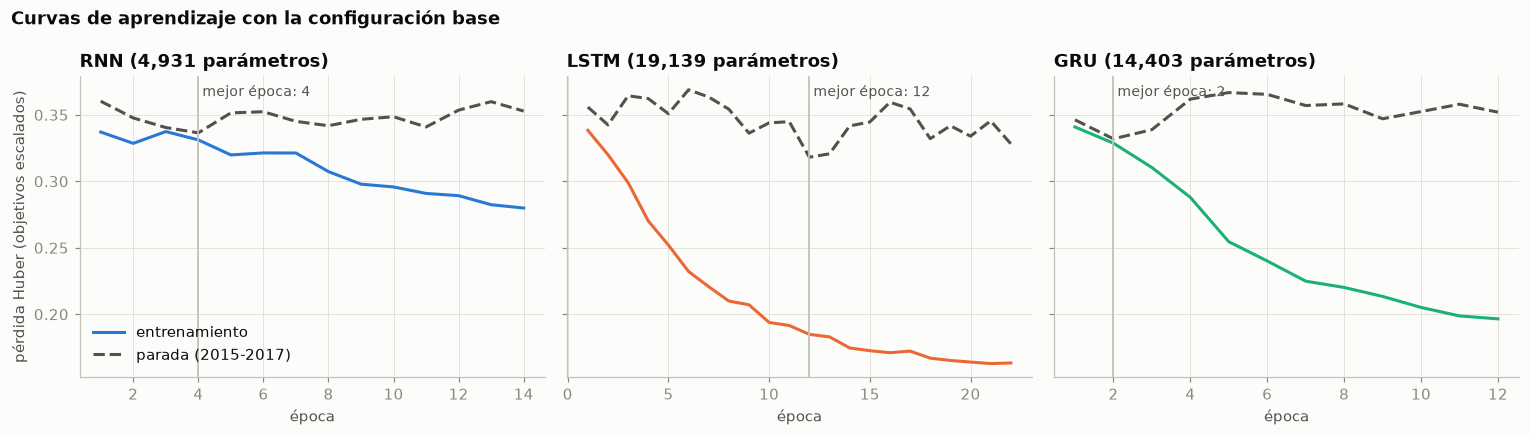

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (celda, r) in zip(axes, resultados.items()):
    h = r.historial
    ax.plot(h["época"], h["pérdida train"], color=COLOR_RED[celda], lw=2, label="entrenamiento")
    ax.plot(h["época"], h["pérdida parada"], color=TINTA_2, lw=2, ls="--", label="parada (2015-2017)")
    ax.axvline(r.mejor_epoca, color=EJE, lw=1.2)
    ax.text(r.mejor_epoca, 0.97, f" mejor época: {r.mejor_epoca}", transform=ax.get_xaxis_transform(),
            fontsize=9, color=TINTA_2, va="top")
    ax.set_title(f"{celda} ({r.parametros:,} parámetros)")
    ax.set_xlabel("época")
axes[0].set_ylabel("pérdida Huber (objetivos escalados)")
axes[0].legend(loc="lower left")
fig.suptitle("Curvas de aprendizaje con la configuración base", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

> **Cómo leer las curvas**
> - En las tres redes, la pérdida de **entrenamiento baja** de forma continua: aprenden… los datos con los que se entrenan.
> - La pérdida de **parada no baja**: oscila entre 0,32 y 0,37 desde la primera época. Lo que aprenden no sirve fuera del periodo de entrenamiento.
> - Es el patrón de **memorización** (sobreajuste): la distancia entre las dos curvas crece con las épocas, sobre todo en la LSTM (el entrenamiento pasa de 0,34 a 0,16) y en la GRU.
> - La parada temprana cumple su función y guarda la versión de la época 4 (RNN), 12 (LSTM) y 2 (GRU). En la RNN y la GRU, la mejor versión es casi la red recién empezada.
> - El zigzag de la curva de parada es normal: el trozo de parada es corto (unos 570 días) y la señal, débil.
>
> **Qué implica:** con la configuración base, las redes tienen demasiada capacidad para la poca señal que hay. La fase B tendrá que probar redes más pequeñas, más dropout, regularización L2 y velocidades de aprendizaje menores.

### 1.2 Resultados en validación (2018)

**MAE / ingenuo**: error del modelo dividido por el del ingenuo. Por debajo de 1, el modelo mejora al ingenuo.

In [5]:
errores_ingenuo = ev.errores(val)
filas, detalle = {}, {}
for nombre, prediccion in predicciones.items():
    comparacion = ev.comparar_con_ingenuo(ev.errores(val, prediccion), errores_ingenuo)
    detalle[nombre] = comparacion
    r = resultados.get(nombre)
    filas[nombre] = {**{f"MAE/ingenuo {h}": v for h, v in comparacion["MAE / ingenuo"].items()},
                     "puntuación (media)": ev.puntuacion(comparacion),
                     "parámetros": r.parametros if r else lineal.n_parametros,
                     "segundos": r.segundos if r else np.nan}
tabla = pd.DataFrame(filas).T
tabla

,MAE/ingenuo corto,MAE/ingenuo medio,MAE/ingenuo largo,puntuación (media),parámetros,segundos
RNN,0.992,1.035,1.171,1.066,"4,931.000",6.282
LSTM,1.075,1.262,4.082,2.140,"19,139.000",9.454
GRU,0.989,0.988,1.599,1.192,"14,403.000",8.665
Lineal,1.006,1.062,1.114,1.061,"1,443.000",NaN


In [6]:
# Error medio absoluto en $/barril (MAE) por horizonte
mae = pd.DataFrame({"Ingenuo": detalle["RNN"]["MAE ingenuo"],
                    **{nombre: d["MAE"] for nombre, d in detalle.items()}})
mae.T.round(2)

horizonte,corto,medio,largo
Ingenuo,2.450,9.040,9.050
RNN,2.440,9.360,10.590
LSTM,2.640,11.410,36.940
GRU,2.430,8.930,14.470
Lineal,2.470,9.600,10.080


### 1.3 Previsiones frente a la realidad (2018)

Cada punto del eje X es un día de 2018 en el que se hace la previsión. La línea oscura es el precio que **realmente** hubo *h* sesiones después; la gris, lo que dice el ingenuo (el precio de ese día); la de color, lo que previó cada red.

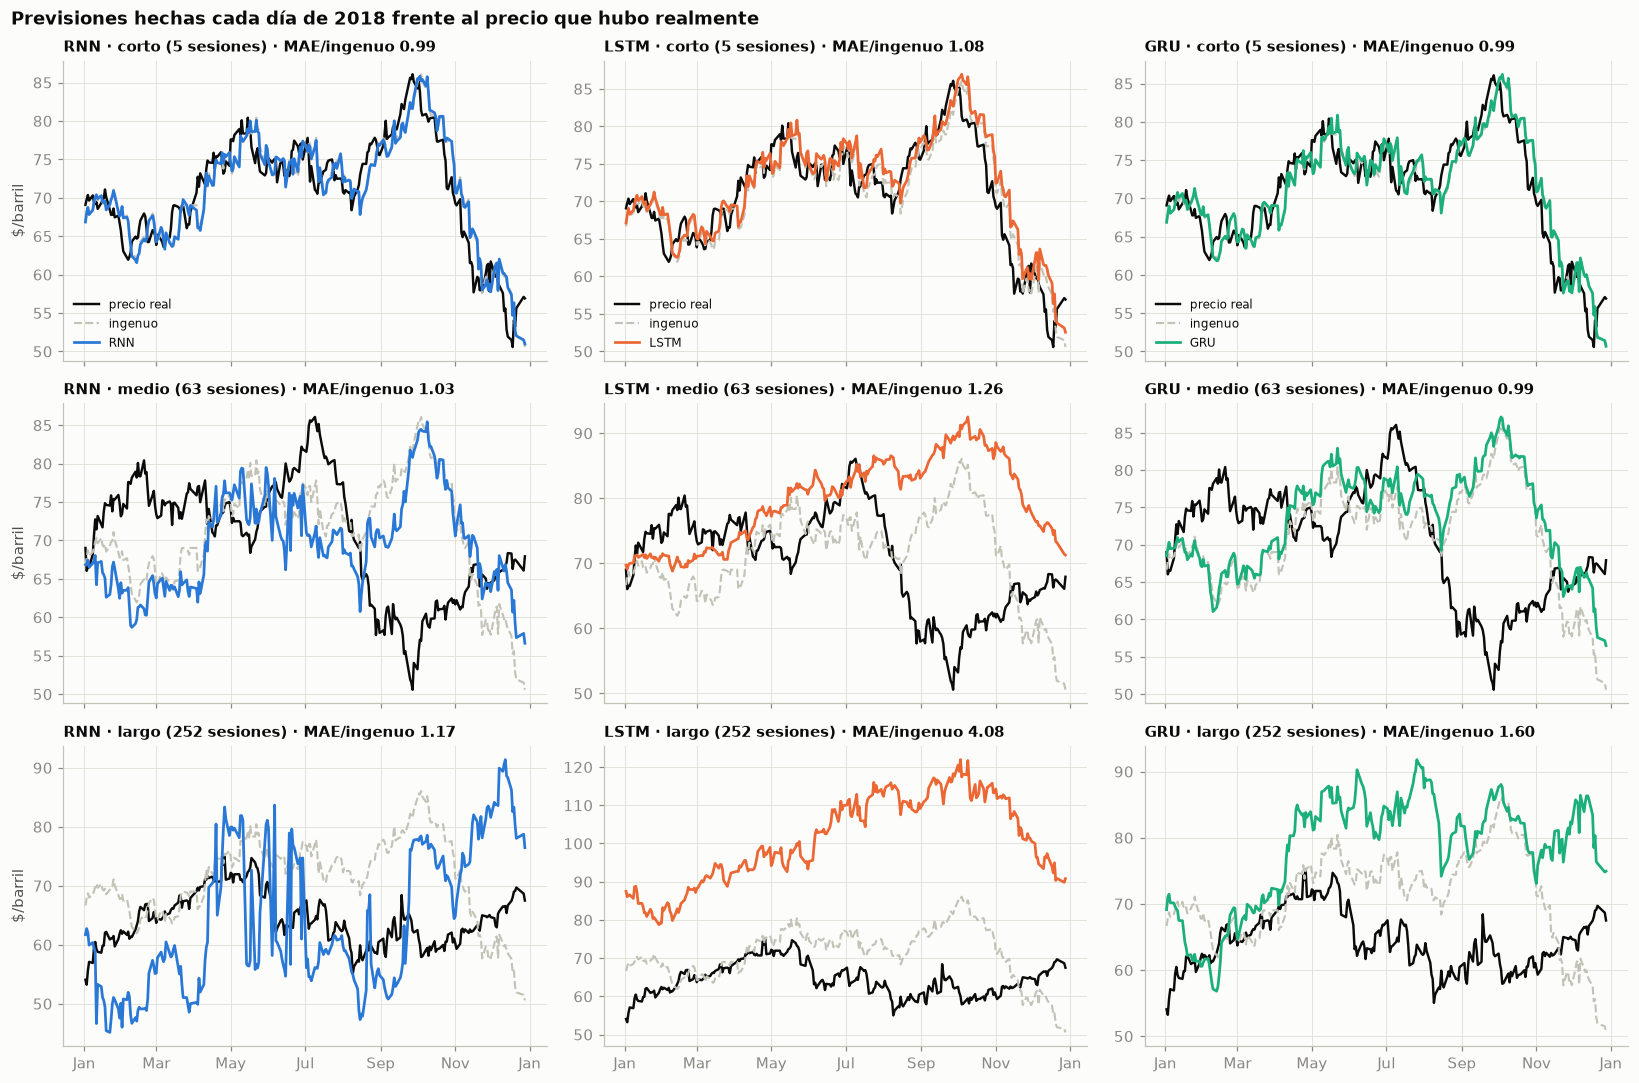

In [7]:
precio_futuro = {h: np.exp(val.Y[:, j]) * val.precio_origen for j, h in enumerate(val.horizontes)}
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for fila, (j, horizonte) in zip(axes, enumerate(val.horizontes)):
    for ax, celda in zip(fila, config.CELDAS):
        previsto = np.exp(predicciones[celda][:, j]) * val.precio_origen
        ax.plot(val.fechas, precio_futuro[horizonte], color=TINTA, lw=1.6, label="precio real")
        ax.plot(val.fechas, val.precio_origen, color=EJE, lw=1.4, ls="--", label="ingenuo")
        ax.plot(val.fechas, previsto, color=COLOR_RED[celda], lw=1.8, label=celda)
        ratio = detalle[celda].loc[horizonte, "MAE / ingenuo"]
        ax.set_title(f"{celda} · {horizonte} ({config.HORIZONTES[horizonte]} sesiones) · MAE/ingenuo {ratio:.2f}",
                     fontsize=10)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fila[0].set_ylabel("$/barril")
for ax in axes[0]:
    ax.legend(loc="lower left", fontsize=8)
fig.suptitle("Previsiones hechas cada día de 2018 frente al precio que hubo realmente",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

> **Cómo leer las previsiones**
> - **A 5 sesiones (fila de arriba)**, las tres redes dibujan una línea casi pegada al precio real, pero también pegada al ingenuo: repiten el precio del día con pequeños retoques. Es el «espejismo» del que hablamos (D15): parece que aciertan, pero su error es prácticamente el mismo que el del ingenuo (MAE de 2,43 a 2,64 $ frente a 2,45 $).
> - **A 63 sesiones**, la GRU sigue de cerca al ingenuo y queda a la par (0,99). La LSTM se despega hacia arriba y prevé subidas que no llegan.
> - **A 252 sesiones está el problema:** las tres redes prevén precios **más altos** que el ingenuo durante casi todo 2018. La LSTM llega a prever entre 80 y 120 $ cuando el precio real un año después estuvo entre 55 y 75 $. Han aprendido la tendencia alcista del periodo de entrenamiento (el Brent pasó de unos 25 $ en 2002 a 140 $ en 2008) y la proyectan hacia el futuro. La RNN, además, salta de forma brusca de un día a otro.
> - El ingenuo también falla (en la segunda mitad de 2018 el precio cayó de 85 $ a 50 $), pero se equivoca menos porque no apuesta por nada.

### 1.4 Qué nos dice esta prueba

1. **El circuito funciona** de principio a fin (datos → fichas → entrenamiento → previsiones en $ → comparación con el ingenuo) y es **reproducible**: la misma semilla da los mismos números.
2. **Sin ajustar, ninguna red mejora claramente al ingenuo.** A corto plazo quedan a la par (0,99); a medio y largo plazo empeoran, sobre todo la LSTM. El modelo lineal queda cerca del ingenuo en los tres horizontes (1,01 / 1,06 / 1,11) y, a largo plazo, es más prudente que las redes.
3. **Dos problemas concretos para la fase B:** la **memorización** (curvas de aprendizaje) y el **sesgo alcista a largo plazo** (previsiones).
4. Es **un solo pliegue (2018) y una sola configuración**. Las conclusiones de verdad saldrán de las fases A y B, con los 4 pliegues.

Todo es coherente con lo que anticipaba el EDA (H1): la variación del Brent es casi impredecible a partir de su pasado. El reto real es conseguir que las redes **no empeoren** al ingenuo, sobre todo a largo plazo, y que aporten algo a corto plazo.

## 2. Fase A: estudio de ventana × recorte × indicador de nivel

**Objetivo (D6, D9, D16):** para cada horizonte, encontrar qué datos le sientan mejor a las redes:
- **ventana:** 10, 20, 40, 60, 120 o 252 días;
- **recorte de extremos:** ninguno, 0,5-99,5 % o 1-99 %;
- **indicador «caro o barato»:** con o sin.

Son 36 combinaciones por horizonte. Cada una se entrena con la **estructura base** en las tres redes y en todos los pliegues de validación (2018-2021; a 252 sesiones, 2018-2020). El modelo lineal se ajusta con 6 fuerzas de regularización y se toma la mejor.

**Medida:** «MAE / ingenuo», juntando las fichas de todos los pliegues. Por debajo de 1, el modelo mejora al ingenuo.

Los entrenamientos los hace `scripts/fase_a.py` y se guardan en `resultados/fase_a.csv`; aquí solo se leen y analizan. **Todo se mide con la estructura base y una sola semilla**, así que cada número lleva algo de ruido: las mejores combinaciones se confirman después con 3 semillas.

In [8]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import NullLocator

from oil_price import experimentos as ex
from oil_price.graficos import DIVERGENTE

# on_bad_lines="skip": por si el archivo se está escribiendo mientras se lee
resultados = pd.read_csv(config.DIR_RESULTADOS / "fase_a.csv", on_bad_lines="skip").dropna(subset=["MAE"])
redes_crudo = resultados[resultados["modelo"] != "Lineal"]

# Entrenamientos esperados por horizonte y ventana: 6 variantes × 3 redes × pliegues
esperados = {h: 6 * 3 * (3 if h == "largo" else 4) for h in config.HORIZONTES}
estado = (redes_crudo.pivot_table(index="horizonte", columns="ventana", values="MAE", aggfunc="size")
          .reindex(index=list(config.HORIZONTES), columns=config.VENTANAS).fillna(0).astype(int))
completas = [v for v in config.VENTANAS if all(estado.loc[h, v] == esperados[h] for h in config.HORIZONTES)]
print(f"Entrenamientos de redes: {len(redes_crudo):,} · del modelo lineal: {len(resultados) - len(redes_crudo):,}")
print(f"Ventanas completas: {completas}  ·  pendientes: {[v for v in config.VENTANAS if v not in completas]}")
estado

Entrenamientos de redes: 1,188 · del modelo lineal: 2,376
Ventanas completas: [10, 20, 40, 60, 120, 252]  ·  pendientes: []


ventana,10,20,40,60,120,252
horizonte,,,,,,
corto,72,72,72,72,72,72
medio,72,72,72,72,72,72
largo,54,54,54,54,54,54


In [9]:
resumen = ex.resumir(resultados)
resumen = resumen[resumen["ventana"].isin(completas)]
redes = resumen[resumen["modelo"] != "Lineal"]
lineal = resumen[resumen["modelo"] == "Lineal"]
CLAVE_DATOS = ["horizonte", "ventana", "recorte", "nivel"]
# Del modelo lineal se toma, en cada combinación, su mejor fuerza de regularización (su «ajuste»)
lineal_mejor = lineal.loc[lineal.groupby(CLAVE_DATOS)["MAE / ingenuo"].idxmin()]
NOMBRE_VARIANTE = {("ninguno", True): "sin recorte\ncon nivel", ("ninguno", False): "sin recorte\nsin nivel",
                   ("0.5-99.5", True): "0,5-99,5\ncon nivel", ("0.5-99.5", False): "0,5-99,5\nsin nivel",
                   ("1-99", True): "1-99\ncon nivel", ("1-99", False): "1-99\nsin nivel"}

### 2.1 Error según la ventana

Para cada horizonte, cómo cambia el error al mirar más o menos días atrás. Cada punto es la media de las 6 variantes de recorte y nivel. La línea gris horizontal es el ingenuo (= 1). **Cada panel tiene su propia escala**: los tres horizontes se mueven en rangos muy distintos.

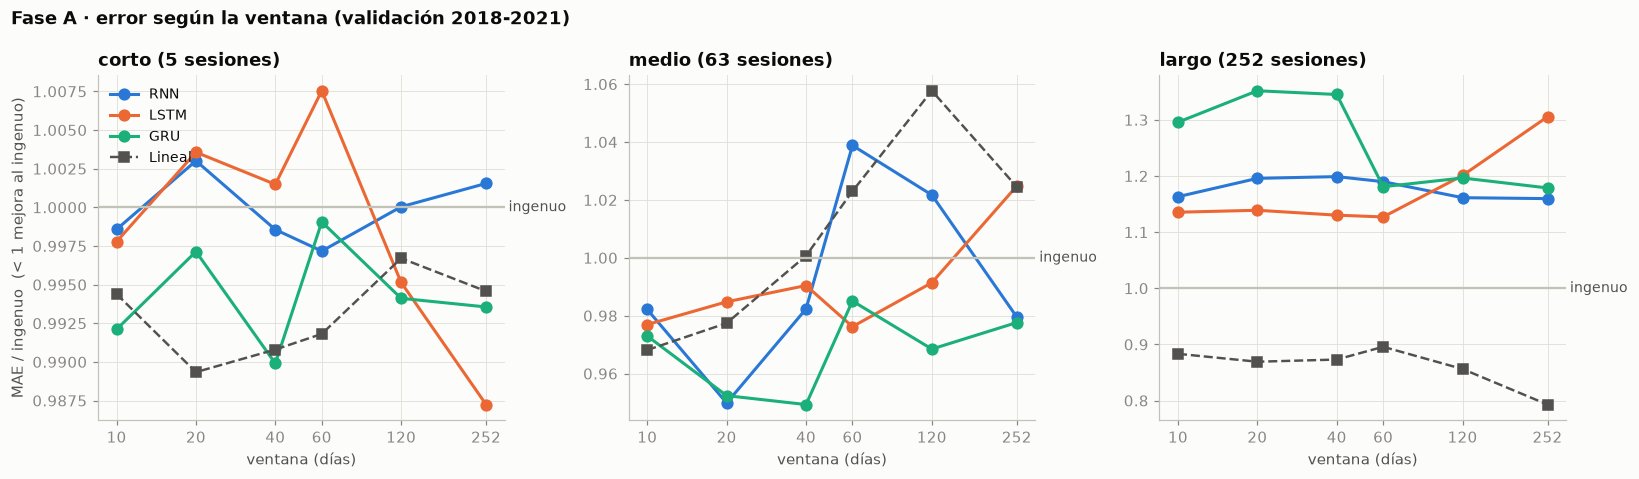

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, h in zip(axes, config.HORIZONTES):
    for celda, color in COLOR_RED.items():
        s = redes[(redes["horizonte"] == h) & (redes["modelo"] == celda)].groupby("ventana")["MAE / ingenuo"].mean()
        ax.plot(s.index, s.values, "o-", color=color, lw=2, ms=7, label=celda)
    s = lineal_mejor[lineal_mejor["horizonte"] == h].groupby("ventana")["MAE / ingenuo"].mean()
    ax.plot(s.index, s.values, "s--", color=TINTA_2, lw=1.6, ms=6, label="Lineal")
    ax.axhline(1, color=EJE, lw=1.5)
    ax.text(1.0, 1, " ingenuo", transform=ax.get_yaxis_transform(), va="center", fontsize=9, color=TINTA_2)
    ax.set_xscale("log")
    ax.set_xticks(completas, [str(v) for v in completas])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("ventana (días)")
    ax.set_title(f"{h} ({config.HORIZONTES[h]} sesiones)")
axes[0].set_ylabel("MAE / ingenuo  (< 1 mejora al ingenuo)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Fase A · error según la ventana (validación 2018-2021)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.2 Todas las combinaciones

Cada casilla es la media de las tres redes para una combinación. **Azul: mejora al ingenuo; rojo: empeora.** La intensidad del color se ajusta a cada horizonte, con una escala mínima de ±5 %: las diferencias menores que eso apenas se colorean, porque están dentro del ruido.

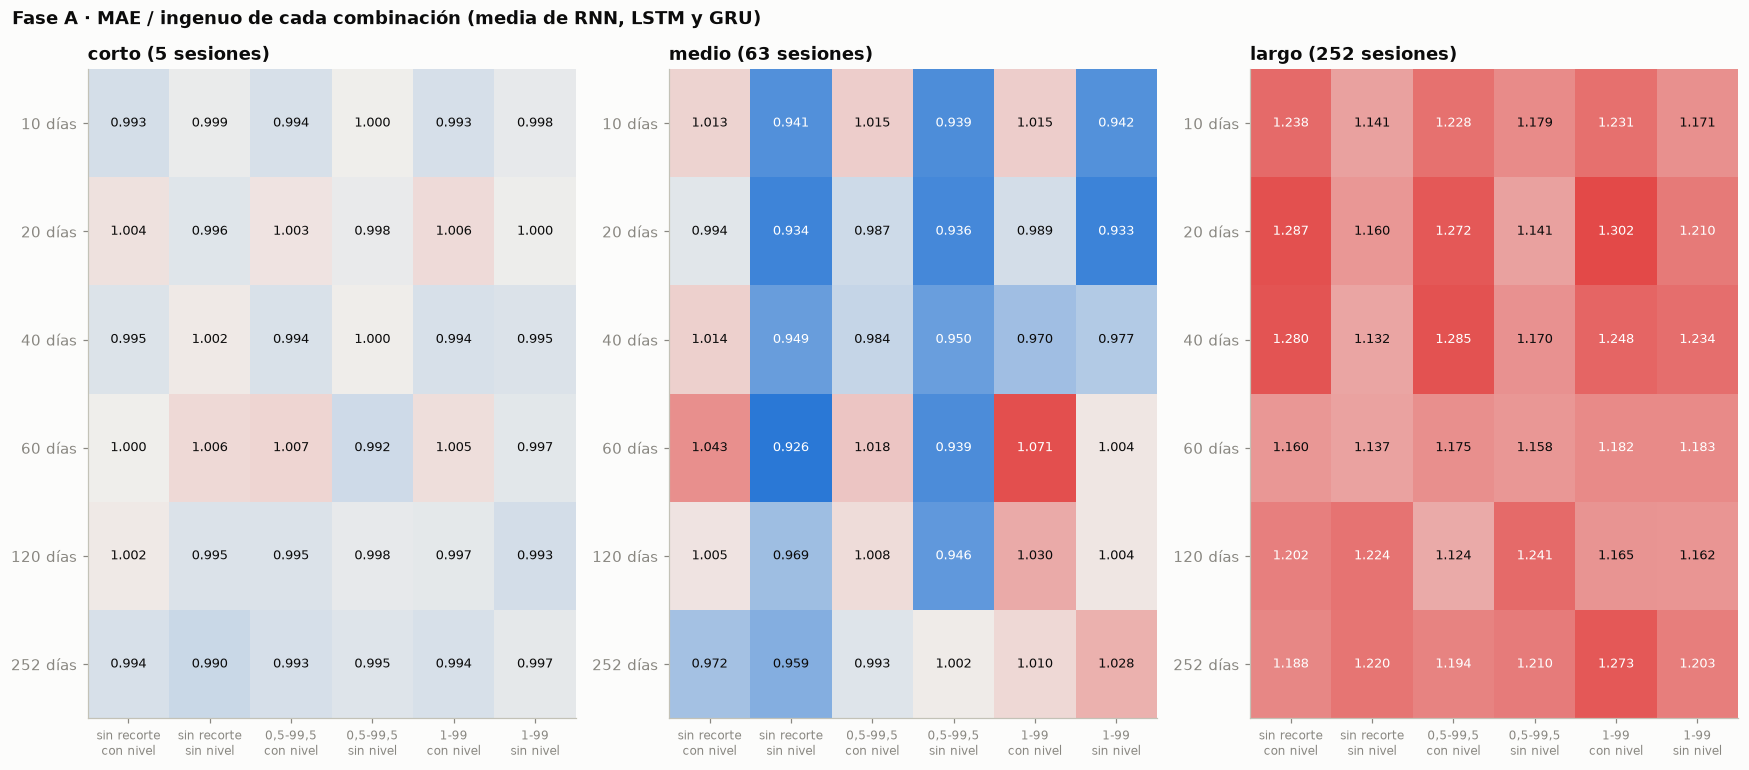

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 0.75 * len(completas) + 2.6))
for ax, h in zip(axes, config.HORIZONTES):
    tabla = (redes[redes["horizonte"] == h].groupby(["ventana", "recorte", "nivel"])["MAE / ingenuo"].mean()
             .unstack(["recorte", "nivel"]).reindex(columns=list(NOMBRE_VARIANTE)))
    distancia = max(abs(tabla.values - 1).max(), 0.05)   # escala mínima ±5 %: el ruido no se colorea
    norma = TwoSlopeNorm(vcenter=1, vmin=1 - distancia, vmax=1 + distancia)
    ax.imshow(tabla.values, cmap=DIVERGENTE.reversed(), norm=norma, aspect="auto")
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            valor = tabla.values[i, j]
            ax.text(j, i, f"{valor:.3f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if abs(valor - 1) > 0.6 * distancia else TINTA)
    ax.set_xticks(range(tabla.shape[1]), [NOMBRE_VARIANTE[c] for c in tabla.columns], fontsize=8)
    ax.set_yticks(range(tabla.shape[0]), [f"{v} días" for v in tabla.index])
    ax.grid(False)
    ax.set_title(f"{h} ({config.HORIZONTES[h]} sesiones)")
fig.suptitle("Fase A · MAE / ingenuo de cada combinación (media de RNN, LSTM y GRU)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Efecto medio del indicador de nivel y del recorte

In [12]:
efecto_nivel = redes.pivot_table(index="horizonte", columns="nivel", values="MAE / ingenuo", aggfunc="mean")
efecto_nivel.columns = ["sin nivel", "con nivel"]
efecto_recorte = redes.pivot_table(index="horizonte", columns="recorte", values="MAE / ingenuo", aggfunc="mean")
efecto_recorte = efecto_recorte[["ninguno", "0.5-99.5", "1-99"]].add_prefix("recorte ")
pd.concat([efecto_nivel, efecto_recorte], axis=1).reindex(list(config.HORIZONTES)).round(3)

,sin nivel,con nivel,recorte ninguno,recorte 0.5-99.5,recorte 1-99
horizonte,,,,,
corto,0.997,0.998,0.998,0.998,0.997
medio,0.960,1.007,0.977,0.976,0.998
largo,1.182,1.224,1.197,1.198,1.214


### 2.4 Clasificación

Las 5 mejores combinaciones de cada horizonte, ordenadas por la media de las tres redes (criterio D16). Al lado, el mejor modelo lineal con esos mismos datos.

In [13]:
por_red = redes.pivot_table(index=CLAVE_DATOS, columns="modelo", values="MAE / ingenuo")[config.CELDAS]
por_red["media redes"] = por_red.mean(axis=1)
por_red = por_red.join(lineal_mejor.set_index(CLAVE_DATOS)[["MAE / ingenuo", "alfa"]]
                       .rename(columns={"MAE / ingenuo": "Lineal", "alfa": "alfa lineal"}))
for h in config.HORIZONTES:
    print(f"{h} ({config.HORIZONTES[h]} sesiones)")
    display(por_red.loc[h].sort_values("media redes").head(5).round(3))

corto (5 sesiones)


,,,RNN,LSTM,GRU,media redes,Lineal,alfa lineal
ventana,recorte,nivel,,,,,,
252,ninguno,False,0.993,0.983,0.996,0.990,0.992,"100,000.000"
60,0.5-99.5,False,0.989,0.990,0.996,0.992,0.990,"100,000.000"
120,1-99,False,0.999,0.987,0.991,0.993,0.995,"100,000.000"
10,ninguno,True,0.999,0.990,0.990,0.993,0.996,"10,000.000"
252,0.5-99.5,True,0.997,0.987,0.996,0.993,0.998,"100,000.000"


medio (63 sesiones)


RNN  LSTM   GRU  media redes  Lineal  alfa lineal
ventana recorte  nivel                                                    
60      ninguno  False 0.962 0.902 0.913        0.926   1.007  100,000.000
20      1-99     False 0.939 0.942 0.919        0.933   0.965   10,000.000
        ninguno  False 0.949 0.942 0.910        0.934   0.966   10,000.000
        0.5-99.5 False 0.950 0.942 0.918        0.936   0.966   10,000.000
60      0.5-99.5 False 0.956 0.912 0.950        0.939   1.007  100,000.000

largo (252 sesiones)


,,,RNN,LSTM,GRU,media redes,Lineal,alfa lineal
ventana,recorte,nivel,,,,,,
120,0.5-99.5,True,1.074,1.126,1.170,1.124,0.874,"10,000.000"
40,ninguno,False,1.122,1.093,1.182,1.132,0.864,10.000
60,ninguno,False,1.129,1.101,1.181,1.137,0.870,1.000
10,ninguno,False,1.175,1.111,1.136,1.141,0.880,1.000
20,0.5-99.5,False,1.127,1.093,1.203,1.141,0.879,1.000


### 2.5 ¿Es estable año a año?

Para la mejor combinación de cada horizonte, el resultado de cada red **en cada año de validación**. Una combinación fiable debería mejorar al ingenuo en la mayoría de los años, no solo en uno.

In [14]:
mejores = {h: por_red.loc[h].sort_values("media redes").index[0] for h in config.HORIZONTES}
for h, (ventana, recorte, nivel) in mejores.items():
    filas = redes_crudo[(redes_crudo["horizonte"] == h) & (redes_crudo["ventana"] == ventana)
                        & (redes_crudo["recorte"] == recorte) & (redes_crudo["nivel"] == nivel)]
    tabla = filas.pivot_table(index="modelo", columns="pliegue", values="MAE / ingenuo").loc[config.CELDAS]
    tabla.loc["MAE ingenuo ($)"] = filas.groupby("pliegue")["MAE ingenuo"].first()
    print(f"{h}: ventana {ventana}, recorte {recorte}, {'con' if nivel else 'sin'} nivel")
    display(tabla.round(3))

corto: ventana 252, recorte ninguno, sin nivel


pliegue,2018,2019,2020,2021
modelo,,,,
RNN,1.001,0.997,0.984,0.991
LSTM,0.988,0.991,0.981,0.972
GRU,0.991,1.001,0.988,1.006
MAE ingenuo ($),2.455,1.920,2.873,2.297


medio: ventana 60, recorte ninguno, sin nivel


pliegue,2018,2019,2020,2021
modelo,,,,
RNN,0.921,0.978,0.939,1.082
LSTM,0.947,0.905,0.869,0.919
GRU,0.937,0.901,0.913,0.896
MAE ingenuo ($),9.040,8.523,15.787,6.597


largo: ventana 120, recorte 0.5-99.5, con nivel


pliegue,2018,2019,2020
modelo,,,
RNN,1.099,1.719,0.572
LSTM,0.847,2.017,0.524
GRU,1.515,1.983,0.444
MAE ingenuo ($),9.048,23.075,30.265


### 2.6 El modelo lineal

In [15]:
efecto_alfa = lineal.pivot_table(index="horizonte", columns="alfa", values="MAE / ingenuo", aggfunc="mean")
print("MAE / ingenuo del lineal según la fuerza de regularización (media de ventanas y variantes):")
display(efecto_alfa.reindex(list(config.HORIZONTES)).round(3))

comparacion = pd.DataFrame({
    "mejor red (media de las 3)": por_red.groupby(level="horizonte")["media redes"].min(),
    "mejor red individual": por_red[config.CELDAS].groupby(level="horizonte").min().min(axis=1),
    "mejor lineal": por_red.groupby(level="horizonte")["Lineal"].min(),
}).reindex(list(config.HORIZONTES))
print("Mejor resultado de cada tipo de modelo (MAE / ingenuo):")
comparacion.round(3)

MAE / ingenuo del lineal según la fuerza de regularización (media de ventanas y variantes):


alfa,1.000,10.000,100.000,"1,000.000","10,000.000","100,000.000"
horizonte,,,,,,
corto,1.149,1.116,1.087,1.041,1.000,0.994
medio,1.094,1.083,1.064,1.048,1.038,1.014
largo,0.920,0.902,0.881,0.880,0.898,0.932


Mejor resultado de cada tipo de modelo (MAE / ingenuo):


,mejor red (media de las 3),mejor red individual,mejor lineal
horizonte,,,
corto,0.990,0.983,0.988
medio,0.926,0.901,0.951
largo,1.124,1.074,0.759


Como el lineal gana con claridad a 1 año, conviene mirar si lo hace **todos los años o solo en uno**. Para cada horizonte, su mejor versión (combinación y fuerza de regularización elegidas con todos los pliegues), año a año:

In [16]:
filas = []
for h in config.HORIZONTES:
    mejor = lineal[lineal["horizonte"] == h].sort_values("MAE / ingenuo").iloc[0]
    sel = resultados[(resultados["modelo"] == "Lineal") & (resultados["horizonte"] == h)
                     & (resultados["ventana"] == mejor["ventana"]) & (resultados["recorte"] == mejor["recorte"])
                     & (resultados["nivel"] == mejor["nivel"]) & (resultados["alfa"] == mejor["alfa"])]
    filas.append(sel.set_index("pliegue")["MAE / ingenuo"].rename(
        f"{h}: ventana {mejor['ventana']}, recorte {mejor['recorte']}, "
        f"{'con' if mejor['nivel'] else 'sin'} nivel, alfa {mejor['alfa']:g}"))
print("Mejor modelo lineal de cada horizonte, año a año (MAE / ingenuo):")
pd.DataFrame(filas).round(3)

Mejor modelo lineal de cada horizonte, año a año (MAE / ingenuo):


pliegue,2018,2019,2020,2021
"corto: ventana 20, recorte 0.5-99.5, sin nivel, alfa 10000",0.995,0.991,0.982,0.987
"medio: ventana 10, recorte ninguno, sin nivel, alfa 1000",0.992,0.919,0.925,1.019
"largo: ventana 252, recorte ninguno, sin nivel, alfa 1000",0.810,1.020,0.543,NaN


### 2.7 Lectura de la fase A

> Las 6 ventanas completas: 1.188 entrenamientos de redes y 2.376 del modelo lineal. Estructura base y una sola semilla: cada número lleva algo de ruido, y las mejores combinaciones se confirman con 3 semillas antes de elegir.

**1 semana (5 sesiones): ninguna combinación aporta nada apreciable.**
- Todo queda entre 0,98 y 1,01, tanto en las redes como en el lineal. La mejor de media es la ventana de 252 días sin recorte ni nivel (0,990).
- Ni la ventana, ni el recorte, ni el indicador cambian nada de forma clara: las diferencias rondan el 0,5 %, dentro del ruido.

**3 meses (63 sesiones): la mejora más clara del estudio.**
- Con las mejores combinaciones, las redes mejoran al ingenuo un **6-7 %** de media (0,93), y la LSTM y la GRU llegan al 9-10 % (0,90-0,91).
- Hay **dos candidatas**, ambas sin indicador de nivel:
  - **60 días sin recorte** (0,926): la mejor, y la LSTM y la GRU mejoran al ingenuo los cuatro años. Pero es **frágil**: con recorte 1-99 pasa a 1,004.
  - **20 días** (0,933-0,936): da prácticamente lo mismo con los tres recortes, aunque en 2018 apenas mejora al ingenuo.
  - Las separa menos de un 1 %: es un empate dentro del ruido, y la confirmación con semillas decidirá.
- Las ventanas largas (120 y 252 días) no mejoran a las cortas: para prever a 3 meses no hace falta mirar más de 2-3 meses atrás.
- El factor decisivo sigue siendo **quitar el indicador de nivel** (0,96 sin él frente a 1,01 con él).
- Aquí **las redes superan al lineal** (0,93 frente a 0,95), y el lineal empeora con las ventanas largas.

**1 año (252 sesiones): las redes empeoran al ingenuo con cualquier combinación; el lineal lo mejora con claridad.**
- Las 36 combinaciones de las redes quedan entre 1,12 y 1,30: ninguna ventana corrige el problema. Además, aciertan si el precio sube o baja solo el 46 % de las veces, menos que una moneda al aire.
- El lineal mejora al ingenuo con todas las ventanas (0,79-0,90 de media), sobre todo con las largas: con 252 días llega a **0,76**.
- **Qué hace el lineal: apuesta por la corrección.** Tras una subida fuerte prevé una bajada; tras una caída, un rebote. Con 252 días de historia «ve» el último año completo. Le sale muy bien en 2020 (tras el desplome prevé un rebote fuerte, y lo hubo: 0,54), regular en 2018 (prevé una bajada y la hubo: 0,81) y nada en 2019 (1,02: la caída por la COVID era imprevisible).
- **Con cautela:** solo hay 3 años independientes, casi toda la ventaja viene de 2020, y el 0,76 es el mejor de 216 intentos (36 combinaciones × 6 fuerzas de regularización), así que es algo optimista. El test dirá si se sostiene.

**Otras observaciones**
- **El indicador de nivel empeora a las redes** a 3 meses y a 1 año, al contrario de lo que esperaba la hipótesis H6. El lineal sí aprovecha la idea de corrección, pero sobre todo a través de la ventana de 252 días, que contiene la misma información (cuánto ha subido o bajado el precio en el último año).
- **El recorte apenas influye** en ningún horizonte (diferencias de hasta un 2 %).
- **Las redes base memorizan con todas las ventanas:** su mejor época media está entre la 4 y la 6. La fase B, con redes más pequeñas y más reguladas, es la ocasión de corregirlo, sobre todo a 1 año.
- **Coste:** la ventana de 252 días multiplica el tiempo (GRU: unos 78 s por entrenamiento, frente a 5 s con 10 días) y no mejora a las redes.
- La hipótesis H1 («solo se mejora a 1 semana») **no se cumple en validación**: el horizonte que se mejora es el de 3 meses (y a 1 año, solo el lineal).

## 3. Cierre de la fase A: confirmación con semillas (D19)

**Por qué:** cada combinación de la fase A se entrenó con una sola semilla (la 42). La semilla decide los pesos con los que arranca la red y el orden en que ve los datos: con otra semilla, el resultado cambia algo aunque los datos sean idénticos. Muchas diferencias de la fase A son menores que ese azar. Para saber cuáles son reales, **las 3 mejores combinaciones de cada horizonte se repiten con dos semillas más** (43 y 44).

**Regla de elección, fijada antes de ver los resultados:**
- De cada finalista se toma la media de las 3 semillas (media de las tres redes).
- **Ruido:** lo que cambia una finalista de una semilla a otra (desviación típica entre semillas, media de las finalistas del horizonte).
- Empatan con la mejor las finalistas que quedan a menos de un ruido de ella. Entre las empatadas gana la **ventana más corta**; con la misma ventana, la **más sencilla** (menos recorte, sin indicador de nivel).

Los entrenamientos los hace `scripts/fase_a_semillas.py` y se guardan en `resultados/fase_a_semillas.csv`. La semilla 42 se toma de la fase A: repetida, da exactamente los mismos números. El modelo lineal no se repite porque no tiene azar.

In [17]:
finalistas = ex.finalistas(resultados)
claves_fin = pd.DataFrame([{**f, "recorte": ex.nombre_recorte(f["recorte"])} for f in finalistas])
nuevas = pd.read_csv(config.DIR_RESULTADOS / "fase_a_semillas.csv", on_bad_lines="skip").dropna(subset=["MAE"])
con_42 = redes_crudo.merge(claves_fin[ex.CLAVE_DATOS], on=ex.CLAVE_DATOS)
todas = pd.concat([con_42, nuevas], ignore_index=True)
todas["semilla"] = todas["semilla"].astype(int)
SEMILLAS = sorted(todas["semilla"].unique())
print(f"Entrenamientos: {len(todas)} de {len(con_42) * len([config.SEMILLA, *config.SEMILLAS_EXTRA])} "
      f"(semilla 42, de la fase A: {len(con_42)} · semillas nuevas: {len(nuevas)})")

# «MAE / ingenuo» de cada finalista, red y semilla (juntando los pliegues), y media de las tres redes
por_semilla = ex.resumir(todas, por=["semilla"])
orden = pd.MultiIndex.from_frame(claves_fin[ex.CLAVE_DATOS])
media_redes = (por_semilla.groupby(ex.CLAVE_DATOS + ["semilla"])["MAE / ingenuo"].mean()
               .unstack("semilla").reindex(orden))
decisiones = {h: ex.decidir(media_redes.loc[h]) for h in config.HORIZONTES}

Entrenamientos: 297 de 297 (semilla 42, de la fase A: 99 · semillas nuevas: 198)


### 3.1 Cada finalista con sus tres semillas

Cada punto es una semilla (media de las tres redes); el hueco, la de la fase A. La raya vertical es la media de las tres semillas, en naranja la elegida. La franja azul es la **zona de empate**: de la mejor media a un ruido de distancia. La línea gris es el ingenuo (= 1). Cada panel tiene su propia escala.

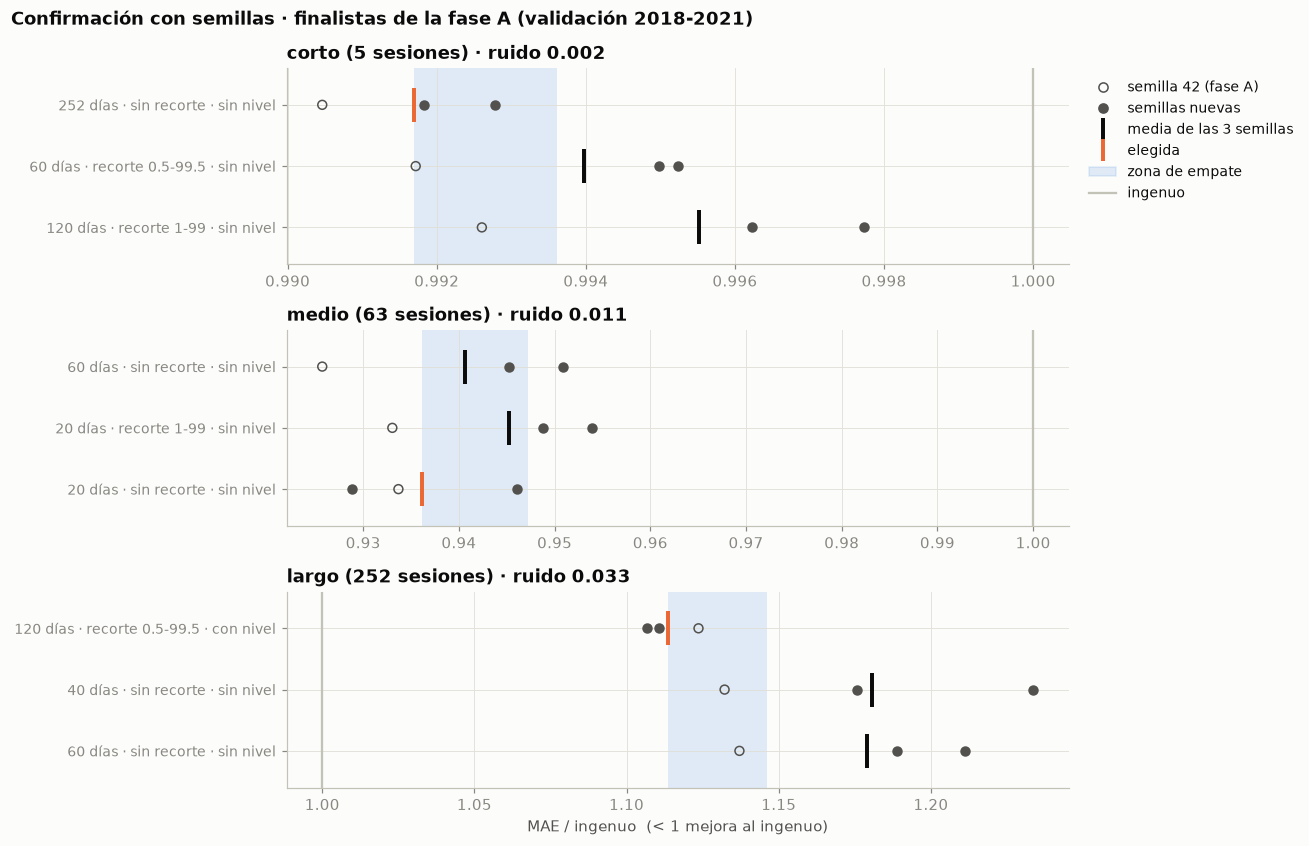

In [18]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, axes = plt.subplots(3, 1, figsize=(12, 7.8))
for ax, h in zip(axes, config.HORIZONTES):
    tabla, ruido = decisiones[h]
    y = np.arange(len(tabla))[::-1]   # la mejor de la fase A, arriba
    mejor = tabla["media"].min()
    ax.axvspan(mejor, mejor + ruido, color=C["azul"], alpha=0.13, lw=0)
    ax.axvline(1, color=EJE, lw=1.5)
    for yi, (_, fila) in zip(y, tabla.iterrows()):
        for s in SEMILLAS:
            ax.scatter(fila[s], yi, s=34, zorder=3, color=TINTA_2,
                       facecolor="none" if s == config.SEMILLA else TINTA_2)
        ax.scatter(fila["media"], yi, marker="|", s=500, lw=2.6, zorder=4,
                   color=C["naranja"] if fila["elegida"] else TINTA)
    ax.set_yticks(y, [f"{v} días · {'sin recorte' if r == 'ninguno' else 'recorte ' + r} · "
                      f"{'con' if n else 'sin'} nivel" for v, r, n in tabla.index], fontsize=9)
    ax.set_ylim(-0.6, len(tabla) - 0.4)
    ax.set_title(f"{h} ({config.HORIZONTES[h]} sesiones) · ruido {ruido:.3f}")
axes[-1].set_xlabel("MAE / ingenuo  (< 1 mejora al ingenuo)")
leyenda = [Line2D([], [], marker="o", ls="", mfc="none", mec=TINTA_2, label="semilla 42 (fase A)"),
           Line2D([], [], marker="o", ls="", color=TINTA_2, label="semillas nuevas"),
           Line2D([], [], marker="|", ls="", ms=14, mew=2.6, color=TINTA, label="media de las 3 semillas"),
           Line2D([], [], marker="|", ls="", ms=14, mew=2.6, color=C["naranja"], label="elegida"),
           Patch(color=C["azul"], alpha=0.13, label="zona de empate"),
           Line2D([], [], color=EJE, lw=1.5, label="ingenuo")]
axes[0].legend(handles=leyenda, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
fig.suptitle("Confirmación con semillas · finalistas de la fase A (validación 2018-2021)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 3.2 La regla aplicada

Para cada horizonte: el resultado de cada semilla, la media, la desviación entre semillas, si empata con la mejor y cuál se elige.

In [19]:
nombres = {s: f"semilla {s}" + (" (fase A)" if s == config.SEMILLA else "") for s in SEMILLAS}
for h in config.HORIZONTES:
    tabla, ruido = decisiones[h]
    ganadora_a = tabla.iloc[0]   # la mejor de la fase A
    nuevas_a = ganadora_a[[s for s in SEMILLAS if s != config.SEMILLA]].mean()
    print(f"{h} ({config.HORIZONTES[h]} sesiones) · ruido entre semillas: {ruido:.3f} · "
          f"la mejor de la fase A pasa de {ganadora_a[config.SEMILLA]:.3f} a {nuevas_a:.3f} con las semillas nuevas")
    display(tabla.rename(columns=nombres).round(3))

corto (5 sesiones) · ruido entre semillas: 0.002 · la mejor de la fase A pasa de 0.990 a 0.992 con las semillas nuevas


,,semilla,semilla 42 (fase A),semilla 43,semilla 44,media,desviación,empata con la mejor,elegida
ventana,recorte,nivel,,,,,,,
252,ninguno,False,0.990,0.993,0.992,0.992,0.001,True,True
60,0.5-99.5,False,0.992,0.995,0.995,0.994,0.002,False,False
120,1-99,False,0.993,0.998,0.996,0.996,0.003,False,False


medio (63 sesiones) · ruido entre semillas: 0.011 · la mejor de la fase A pasa de 0.926 a 0.948 con las semillas nuevas


semilla                semilla 42 (fase A)  semilla 43  semilla 44  media  desviación  empata con la mejor  elegida
ventana recorte nivel                                                                                              
60      ninguno False                0.926       0.951       0.945  0.941       0.013                 True    False
20      1-99    False                0.933       0.954       0.949  0.945       0.011                 True    False
        ninguno False                0.934       0.929       0.946  0.936       0.009                 True     True

largo (252 sesiones) · ruido entre semillas: 0.033 · la mejor de la fase A pasa de 1.124 a 1.109 con las semillas nuevas


,,semilla,semilla 42 (fase A),semilla 43,semilla 44,media,desviación,empata con la mejor,elegida
ventana,recorte,nivel,,,,,,,
120,0.5-99.5,True,1.124,1.111,1.107,1.114,0.009,True,True
40,ninguno,False,1.132,1.234,1.176,1.181,0.051,False,False
60,ninguno,False,1.137,1.211,1.189,1.179,0.038,False,False


### 3.3 ¿Qué red es más estable?

Cuánto cambia el resultado de cada red al cambiar solo la semilla (desviación típica de «MAE / ingenuo» entre semillas, en % del error del ingenuo, media de las finalistas). Cuanto más bajo, más estable. La última columna es la media de las tres redes, que es lo que usa la regla.

In [20]:
por_red = por_semilla.pivot_table(index=ex.CLAVE_DATOS + ["modelo"], columns="semilla", values="MAE / ingenuo")
estabilidad = por_red.std(axis=1, ddof=1).groupby(level=["horizonte", "modelo"]).mean().unstack("modelo")[config.CELDAS]
estabilidad["media de las 3 redes"] = media_redes.std(axis=1, ddof=1).groupby(level="horizonte").mean()
print("Desviación típica entre semillas, en % del error del ingenuo (media de las finalistas):")
(estabilidad.reindex(list(config.HORIZONTES)) * 100).map("{:.2f}".format)

Desviación típica entre semillas, en % del error del ingenuo (media de las finalistas):


modelo,RNN,LSTM,GRU,media de las 3 redes
horizonte,,,,
corto,0.49,0.40,0.36,0.19
medio,1.57,2.36,1.18,1.10
largo,4.49,5.89,4.87,3.26


### 3.4 Elección de los datos de cada horizonte

In [21]:
eleccion = {}
for h, (tabla, ruido) in decisiones.items():
    v, r, n = tabla.index[tabla["elegida"].to_numpy()][0]
    eleccion[h] = {"ventana (días)": v, "recorte": r, "indicador de nivel": "con" if n else "sin",
                   "MAE / ingenuo (media de 3 semillas)": round(tabla.loc[(v, r, n), "media"], 3),
                   "ruido": round(ruido, 3)}
pd.DataFrame(eleccion).T

,ventana (días),recorte,indicador de nivel,MAE / ingenuo (media de 3 semillas),ruido
corto,252,ninguno,sin,0.992,0.002
medio,20,ninguno,sin,0.936,0.011
largo,120,0.5-99.5,con,1.114,0.033


Y año a año: cómo le va a la combinación elegida en cada año de validación (media de las 3 semillas). Por debajo de 1, ese año mejora al ingenuo. A 1 año falta 2021, porque el precio un año después ya cae en el periodo de test.

In [22]:
por_año = {}
for h, (tabla, _) in decisiones.items():
    v, r, n = tabla.index[tabla["elegida"].to_numpy()][0]
    sel = todas[(todas["horizonte"] == h) & (todas["ventana"] == v) & (todas["recorte"] == r) & (todas["nivel"] == n)]
    año = (ex.resumir(sel, por=["semilla", "pliegue"])
           .pivot_table(index="modelo", columns="pliegue", values="MAE / ingenuo").reindex(config.CELDAS))
    año.loc["media de las 3 redes"] = año.mean()
    por_año[h] = año
print("Combinación elegida de cada horizonte, año a año (MAE / ingenuo, media de las 3 semillas):")
pd.concat(por_año, names=["horizonte", "modelo"]).round(3)

Combinación elegida de cada horizonte, año a año (MAE / ingenuo, media de las 3 semillas):


pliegue                         2018  2019  2020  2021
horizonte modelo                                      
corto     RNN                  0.999 1.000 0.988 1.001
          LSTM                 0.993 0.994 0.985 0.981
          GRU                  0.995 0.996 0.984 0.991
          media de las 3 redes 0.996 0.997 0.986 0.991
medio     RNN                  0.928 0.918 0.956 0.930
          LSTM                 0.990 1.055 0.924 0.771
          GRU                  1.010 0.938 0.919 0.745
          media de las 3 redes 0.976 0.970 0.933 0.815
largo     RNN                  1.047 1.756 0.597   NaN
          LSTM                 0.984 1.879 0.553   NaN
          GRU                  1.201 1.964 0.489   NaN
          media de las 3 redes 1.077 1.866 0.546   NaN

### 3.5 Lectura

> 297 entrenamientos: las 9 finalistas × 3 redes × 3 semillas, en todos los años de validación. La semilla 42 viene de la fase A; la 43 y la 44 se entrenaron con `scripts/fase_a_semillas.py` (1,04 h en el portátil).

**El azar del entrenamiento es pequeño a corto plazo y crece con el horizonte.** Al cambiar solo la semilla, la media de las tres redes varía un 0,2 % del error del ingenuo a 1 semana, un 1,1 % a 3 meses y un 3,3 % a 1 año. Cada red por separado varía más (0,4-0,5 %, 1,2-2,4 % y 4,5-5,9 %): al promediar las tres redes, parte del azar se compensa.

**Parte de la ventaja de la fase A era suerte.** 8 de las 9 finalistas empeoran con las semillas nuevas. Era de esperar: al quedarse con la mejor de 36 combinaciones entrenadas con una sola semilla, se elige también la más afortunada. El caso más claro es la LSTM con 60 días a 3 meses: 0,902 en la fase A; 0,983 y 0,969 con las semillas nuevas.

**1 semana: 252 días, sin recorte ni nivel (0,992).**
- Gana a las otras dos finalistas con las tres semillas, aunque por muy poco (0,2-0,4 %). Como aquí el azar es mínimo (0,2 %), esa diferencia basta para quedar fuera del empate.
- En la práctica da igual: las tres finalistas quedan entre 0,992 y 0,996, y la elegida mejora al ingenuo apenas un 1 % (0,986-0,997 según el año). Además, la ventana de 252 días es la más cara: unas 4-5 veces más lenta de entrenar que la de 60.

**3 meses: 20 días, sin recorte ni nivel (0,936).**
- La ventaja de los 60 días era suerte: con las semillas nuevas pasa de 0,926 a 0,95, y las tres finalistas empatan. Gana la de 20 días sin recorte, que además tiene la mejor media.
- Mejora al ingenuo los cuatro años, de media de las tres redes: 0,98 en 2018, 0,97 en 2019, 0,93 en 2020 y 0,82 en 2021. La RNN es la más regular (0,92-0,96 todos los años); la GRU empeora algo al ingenuo en 2018 (1,01) y la LSTM, en 2019 (1,06).

**1 año: 120 días, recorte 0,5-99,5, con nivel (1,114).**
- Gana con claridad: es la mejor con las tres semillas y la única finalista que no empeora con las nuevas.
- Aun así, juntando los tres años, **ninguna red baja de 1 con ninguna semilla** (la mejor, 1,07): el fallo de las redes a 1 año es sistemático, no mala suerte. Año a año es una apuesta: 1,08 en 2018, 1,87 en 2019 y 0,55 en 2020.
- Que la elegida lleve el indicador de nivel no significa que el indicador ayude: con 120 días y los otros dos recortes da parecido con él y sin él, y de media empeora a las redes (1,22 con él frente a 1,18 sin él, en la fase A). Las semillas descartan que su resultado sea suerte del entrenamiento, pero sigue siendo la mejor de 36 combinaciones.
- La fase B parte de aquí, con el lineal (0,76) como listón.

**¿Qué red es más estable?** Con la estructura base, la **GRU** a 1 semana y a 3 meses, y la RNN a 1 año, por poco. La **LSTM** es la que más cambia con la semilla a 3 meses y a 1 año. Con 3 semillas, la medida es aproximada.

**Lo esperado frente a lo obtenido:** se cumplió que el azar crece con el horizonte (a 1 semana es aún menor de lo previsto), que las finalistas empeoran con las semillas nuevas, que a 3 meses hay empate y ganan los 20 días, y que a 1 año nada baja de 1. Solo falló una previsión: a 1 semana esperábamos un empate y gana la de 252 días, aunque por un margen sin importancia práctica.

**Lo que las semillas no resuelven:** los años de validación son siempre los mismos, y elegir con ellos deja algo de optimismo. Para eso está el test, que se usa una sola vez.

## 4. Revisión antes de la fase B: la tendencia media (D20)

**El problema.** El ingenuo prevé que el precio no cambia. Las redes y el lineal, cuando no aprenden nada útil, prevén otra cosa: **la subida media del periodo de entrenamiento**, que es lo primero que aprende una red. Entre 2000 y 2014 el Brent subió de media un 12 % al año, así que, al validar 2018 a 1 año vista, las redes partían de «+12 %». La fase B, al regular más las redes, las acercaría todavía más a esa media.

**El experimento.** La combinación elegida de cada horizonte (sección 3) se repite con las tres semillas **sin tendencia**: la red aprende solo la variación respecto a esa media y, para el futuro, supone tendencia cero, como el ingenuo. El lineal se repite igual (sin término fijo), con todas las combinaciones y fuerzas de regularización. Lo hace `scripts/tendencia.py` y se guarda en `resultados/tendencia.csv`.

**Regla, fijada antes de ver los resultados:** en cada horizonte se adopta «sin tendencia» si no empeora más de un ruido (el medido en la sección 3) frente a «con tendencia», comparando la media de las 3 redes y las 3 semillas. En caso de empate se prefiere, por prudente.

### 4.1 ¿Cuánto cuesta proyectar la media?

Un «modelo» que prevé siempre la subida media del train, sin mirar la ficha: es lo que proyecta una red que no aprende nada útil. Para cada año de validación, la subida media del train que proyecta, la variación media que hubo de verdad y su error frente al ingenuo.

In [23]:
elegidas = ex.eleccion(resultados, nuevas)
solo_media = pd.DataFrame(ex.solo_la_media(list(elegidas.values())))
juntos = ex.resumir(solo_media).set_index("horizonte")["MAE / ingenuo"].reindex(list(config.HORIZONTES))
print("Solo la media, años juntos (MAE / ingenuo): "
      + " · ".join(f"{h} {v:.3f}" for h, v in juntos.items()))
(solo_media.set_index(["horizonte", "pliegue"])
 [["subida media del train (%)", "variación real media (%)", "MAE / ingenuo"]].round(3))

Solo la media, años juntos (MAE / ingenuo): corto 0.997 · medio 0.986 · largo 1.160


subida media del train (%)  variación real media (%)  MAE / ingenuo
horizonte pliegue                                                                     
corto     2018                          0.087                    -0.406          1.002
          2019                          0.084                     0.413          0.995
          2020                          0.080                    -0.492          1.000
          2021                          0.142                     0.747          0.989
medio     2018                          1.949                    -1.473          0.988
          2019                          0.980                    -6.641          1.018
          2020                          1.474                     5.825          0.998
          2021                          1.690                     8.863          0.888
largo     2018                         11.763                   -10.258          1.822
          2019                          6.136                   -46.748          1.154
          2020                          3.126                    56.375          0.968

### 4.2 Con y sin tendencia: la regla aplicada

«MAE / ingenuo» de la combinación elegida de cada horizonte (media de las 3 redes y las 3 semillas), con y sin tendencia.

In [24]:
claves_eleg = pd.DataFrame([{**c, "recorte": ex.nombre_recorte(c["recorte"])} for c in elegidas.values()])[ex.CLAVE_DATOS]
sin_tend = pd.read_csv(config.DIR_RESULTADOS / "tendencia.csv", on_bad_lines="skip").dropna(subset=["MAE"])
variantes = pd.concat([todas.merge(claves_eleg, on=ex.CLAVE_DATOS).assign(tendencia="con"),
                       sin_tend[sin_tend["modelo"] != "Lineal"].assign(tendencia="sin")], ignore_index=True)
variantes["semilla"] = variantes["semilla"].astype(int)
por_variante = ex.resumir(variantes, por=["tendencia", "semilla"])
print(f"Entrenamientos sin tendencia: {(variantes['tendencia'] == 'sin').sum()} de {(variantes['tendencia'] == 'con').sum()}")

# media de las 3 redes en cada semilla, y luego de las semillas
media_var = (por_variante.groupby(["horizonte", "tendencia", "semilla"])["MAE / ingenuo"].mean()
             .groupby(["horizonte", "tendencia"]).mean().unstack("tendencia")
             .reindex(index=list(config.HORIZONTES), columns=["con", "sin"]))
regla = media_var.rename(columns={"con": "con tendencia", "sin": "sin tendencia"})
regla["diferencia"] = regla["sin tendencia"] - regla["con tendencia"]
regla["ruido"] = [decisiones[h][1] for h in regla.index]
regla["se adopta"] = [("sin tendencia" if ex.adoptar_sin_tendencia(f["con tendencia"], f["sin tendencia"], f["ruido"])
                       else "con tendencia") if pd.notna(f["sin tendencia"]) else "—" for _, f in regla.iterrows()]
regla

Entrenamientos sin tendencia: 99 de 99


tendencia,con tendencia,sin tendencia,diferencia,ruido,se adopta
horizonte,,,,,
corto,0.992,0.993,0.001,0.002,sin tendencia
medio,0.936,0.937,0.001,0.011,sin tendencia
largo,1.114,1.044,-0.070,0.033,sin tendencia


Cada red por separado (media de las 3 semillas):

In [25]:
(por_variante.groupby(["horizonte", "modelo", "tendencia"])["MAE / ingenuo"].mean().unstack("tendencia")
 .reindex(index=pd.MultiIndex.from_product([list(config.HORIZONTES), config.CELDAS], names=["horizonte", "modelo"]),
          columns=["con", "sin"])
 .rename(columns={"con": "con tendencia", "sin": "sin tendencia"}).round(3))

tendencia         con tendencia  sin tendencia
horizonte modelo                              
corto     RNN             0.996          0.997
          LSTM            0.988          0.988
          GRU             0.991          0.993
medio     RNN             0.938          0.943
          LSTM            0.949          0.946
          GRU             0.922          0.922
largo     RNN             1.093          1.026
          LSTM            1.108          1.044
          GRU             1.140          1.061

### 4.3 Año a año

Media de las 3 redes y las 3 semillas en cada año de validación, con y sin tendencia, junto al «modelo» que solo prevé la media del train. Por debajo de la línea gris (= 1), ese año mejora al ingenuo.

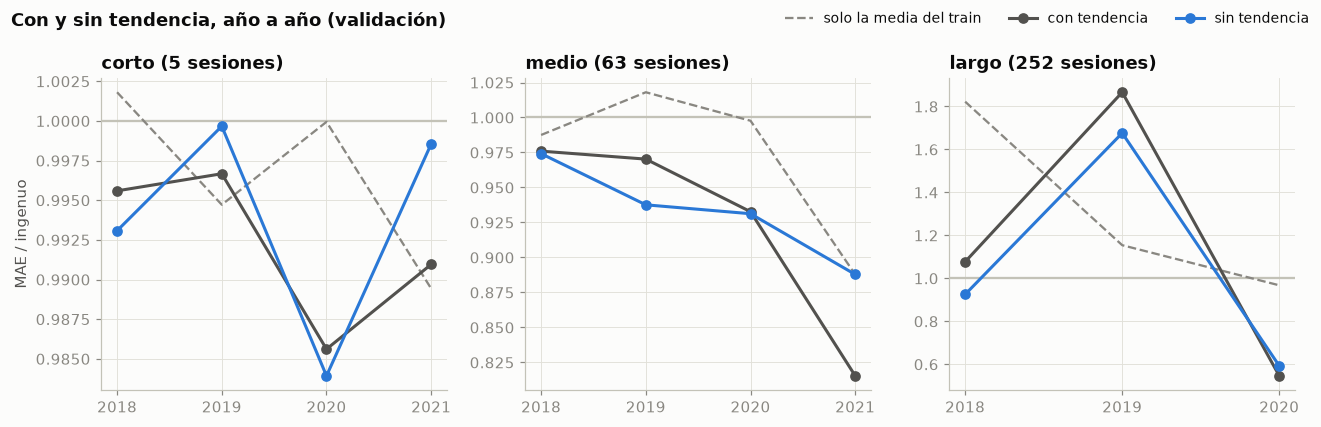

In [26]:
por_año_var = (ex.resumir(variantes, por=["tendencia", "semilla", "pliegue"])
               .groupby(["horizonte", "tendencia", "pliegue"])["MAE / ingenuo"].mean())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, h in zip(axes, config.HORIZONTES):
    ax.axhline(1, color=EJE, lw=1.5)
    s = solo_media[solo_media["horizonte"] == h].set_index("pliegue")["MAE / ingenuo"]
    ax.plot(s.index, s.values, "--", color=TINTA_SUAVE, lw=1.5, label="solo la media del train")
    for tendencia, color, etiqueta in [("con", TINTA_2, "con tendencia"), ("sin", C["azul"], "sin tendencia")]:
        if (h, tendencia) in por_año_var.index.droplevel("pliegue"):
            serie = por_año_var.loc[(h, tendencia)]
            ax.plot(serie.index, serie.values, "o-", color=color, lw=2, ms=6, label=etiqueta)
    ax.set_xticks(s.index)
    ax.set_title(f"{h} ({config.HORIZONTES[h]} sesiones)")
axes[0].set_ylabel("MAE / ingenuo")
fig.suptitle("Con y sin tendencia, año a año (validación)", x=0.01, ha="left", fontweight="bold")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

### 4.4 El modelo lineal

La mejor versión del lineal con y sin tendencia (combinación y fuerza de regularización elegidas en validación, como en la sección 2), y su resultado año a año.

In [27]:
lin = pd.concat([resultados[resultados["modelo"] == "Lineal"].assign(tendencia="con"),
                 sin_tend[sin_tend["modelo"] == "Lineal"].assign(tendencia="sin")], ignore_index=True)
res_lin = ex.resumir(lin, por=["tendencia"])
mejores_lin = res_lin.loc[res_lin.groupby(["horizonte", "tendencia"], sort=False)["MAE / ingenuo"].idxmin()]
filas = []
for _, m in mejores_lin.iterrows():
    sel = lin[(lin["horizonte"] == m["horizonte"]) & (lin["tendencia"] == m["tendencia"]) & (lin["ventana"] == m["ventana"])
              & (lin["recorte"] == m["recorte"]) & (lin["nivel"] == m["nivel"]) & (lin["alfa"] == m["alfa"])]
    filas.append({"horizonte": m["horizonte"], "tendencia": m["tendencia"],
                  "combinación": f"{m['ventana']} días · {m['recorte']} · {'con' if m['nivel'] else 'sin'} nivel · alfa {m['alfa']:g}",
                  "MAE / ingenuo": m["MAE / ingenuo"],
                  **sel.set_index("pliegue")["MAE / ingenuo"].rename(lambda a: f"año {a}").to_dict()})
tabla_lin = pd.DataFrame(filas).set_index(["horizonte", "tendencia"]).reindex(
    pd.MultiIndex.from_product([list(config.HORIZONTES), ["con", "sin"]], names=["horizonte", "tendencia"]))
tabla_lin.round(3)

combinación  MAE / ingenuo  año 2018  año 2019  año 2020  año 2021
horizonte tendencia                                                                                                    
corto     con        20 días · 0.5-99.5 · sin nivel · alfa 10000          0.988     0.995     0.991     0.982     0.987
          sin        20 días · 0.5-99.5 · sin nivel · alfa 10000          0.989     0.991     0.997     0.979     0.994
medio     con          10 días · ninguno · sin nivel · alfa 1000          0.951     0.992     0.919     0.925     1.019
          sin          10 días · ninguno · sin nivel · alfa 1000          0.959     1.011     0.888     0.926     1.092
largo     con         252 días · ninguno · sin nivel · alfa 1000          0.759     0.810     1.020     0.543       NaN
          sin            120 días · ninguno · sin nivel · alfa 1          0.714     1.362     0.851     0.417       NaN

### 4.5 Lectura

> 99 entrenamientos de redes sin tendencia (la combinación elegida de cada horizonte × 3 redes × 3 semillas) y 2.376 del lineal, en 1,23 h en el portátil. Las versiones con tendencia son las de las secciones 2 y 3.

**La regla adopta «sin tendencia» en los tres horizontes.** A 1 año, porque mejora con claridad; a 1 semana y a 3 meses, porque empata, y en caso de empate se prefiere por prudente (supone lo mismo que el ingenuo).

**1 año: la tendencia explicaba buena parte del problema.**
- Las redes pasan de 1,114 a **1,044**: mejoran 0,07, el doble del ruido. Mejoran las tres redes (entre 0,06 y 0,08 cada una) y con las tres semillas, aunque con la 44 apenas.
- Año a año pasa lo esperado. Ganan en los años de bajada: en 2018 pasan de 1,08 a 0,93, ya mejor que el ingenuo, y en 2019, de 1,87 a 1,68. Pierden algo en el año del rebote: en 2020, de 0,55 a 0,59.
- De lo que las redes perdían frente al ingenuo (un 11 %), la tendencia explicaba unas tres quintas partes. **Aun así siguen un 4 % peor que el ingenuo.** El resto es el problema de fondo (pocos ejemplos y un pasado que no se repite), y eso es lo que tendrá que atacar la fase B.
- Aciertan más veces si el precio sube o baja (del 55 % al 60 %).
- El azar entre semillas crece: con la semilla 44 da 1,10, y con las otras dos, 1,01-1,03.

**3 meses: la ventaja de las redes no venía de la tendencia.**
- El resultado es el mismo (de 0,936 a 0,937), pero mejor repartido entre años: mejora en 2019 (de 0,97 a 0,94) y empeora en 2021, un año de subida (de 0,82 a 0,89). La ventaja depende ahora menos de un solo año.
- Es una buena noticia: el 6 % que ganan las redes a 3 meses es señal, no la subida media del pasado.

**1 semana: sin cambios** (de 0,992 a 0,993). La pequeña ventaja de las redes tampoco venía de la tendencia, y sigue siendo prácticamente nula.

**El lineal**
- A 1 año, su mejor versión pasa de 0,759 a **0,714**. Pero es otra combinación (120 días y casi sin regularizar) y muy irregular por años (1,36 en 2018, 0,42 en 2020). Es la mejor de 216 intentos, así que hay que tomarla con cautela. Con la combinación de antes, sin tendencia pasa de 0,759 a 0,743; y la mediana de las 216 versiones, de 0,89 a 0,84.
- A 3 meses y a 1 semana queda prácticamente igual (de 0,951 a 0,959 y de 0,988 a 0,989), dentro del ruido.
- El listón para las redes a 1 año sigue entre 0,71 y 0,76.

**Lo esperado frente a lo obtenido:** en las redes se cumplió todo. A 1 año mejoran con claridad, ganando en 2018 y 2019 y perdiendo en 2020, y a 3 meses y a 1 semana apenas cambian. En el lineal, no del todo: con la combinación de antes, en 2018 empeora (de 0,81 a 0,95), porque ya apostaba por una bajada y sin tendencia la exagera.

**Qué implica**
- La hipótesis H7 se cumple.
- A partir de aquí (fase B y test), todo se hace sin tendencia.
- Los datos de 1 año se eligieron con tendencia, y quitarla cambia mucho el resultado. **Propuesta:** repetir la fase A de 1 año sin tendencia antes de la fase B. A 3 meses y a 1 semana el resultado no cambia, así que la elección se mantiene.

## 5. Fase A de 1 año, repetida sin tendencia (D21)

**Por qué:** los datos de 1 año (ventana, recorte e indicador de nivel) se eligieron en las secciones 2 y 3 **con tendencia**, y quitarla cambia el resultado en 0,07. Una combinación podía ganar solo porque compensaba la tendencia; el indicador de nivel, por ejemplo.

**Qué se hace:**
- Las 36 combinaciones de 1 año se repiten **sin tendencia**, con las tres redes y la semilla 42.
- Las 3 mejores se repiten con las semillas 43 y 44 y se elige con la **misma regla de la sección 3**. La elegida sustituye a la de 1 año.
- A 1 semana y a 3 meses la elección se mantiene: sin tendencia, su resultado era el mismo (sección 4).
- El lineal no se repite: sin tendencia ya está completo (sección 4.4).

Lo hacen `scripts/fase_a.py --horizontes largo --sin-tendencia` y `scripts/fase_a_semillas.py --horizontes largo --sin-tendencia`, que guardan en `resultados/fase_a_sin_tendencia.csv` y `resultados/fase_a_sin_tendencia_semillas.csv`.

In [28]:
a_sin = pd.read_csv(config.DIR_RESULTADOS / "fase_a_sin_tendencia.csv", on_bad_lines="skip").dropna(subset=["MAE"])
semillas_sin = pd.read_csv(config.DIR_RESULTADOS / "fase_a_sin_tendencia_semillas.csv",
                           on_bad_lines="skip").dropna(subset=["MAE"])
print(f"Fase A sin tendencia: {len(a_sin)} de {36 * 3 * 3} entrenamientos · "
      f"confirmación con semillas: {len(semillas_sin)} de {3 * 2 * 3 * 3}")


def media_combinaciones(df):
    """«MAE / ingenuo» de cada combinación de 1 año (media de las 3 redes, semilla 42)."""
    r = ex.resumir(df[(df["horizonte"] == "largo") & (df["modelo"] != "Lineal")])
    return r.groupby(["ventana", "recorte", "nivel"])["MAE / ingenuo"].mean()


comparacion = pd.DataFrame({"con tendencia": media_combinaciones(resultados),
                            "sin tendencia": media_combinaciones(a_sin)})
comparacion["mejora"] = comparacion["con tendencia"] - comparacion["sin tendencia"]
print(f"Mejoran sin tendencia: {(comparacion['mejora'] > 0).sum()} de {len(comparacion)} combinaciones · "
      f"mejora media {comparacion['mejora'].mean():.3f} (mínima {comparacion['mejora'].min():.3f}, "
      f"máxima {comparacion['mejora'].max():.3f})")

Fase A sin tendencia: 324 de 324 entrenamientos · confirmación con semillas: 54 de 54
Mejoran sin tendencia: 36 de 36 combinaciones · mejora media 0.164 (mínima 0.032, máxima 0.262)


### 5.1 Todas las combinaciones, con y sin tendencia

Como en la sección 2.2, cada casilla es la media de las tres redes (semilla 42). Los dos paneles comparten la escala de color: **azul, mejora al ingenuo; rojo, empeora.**

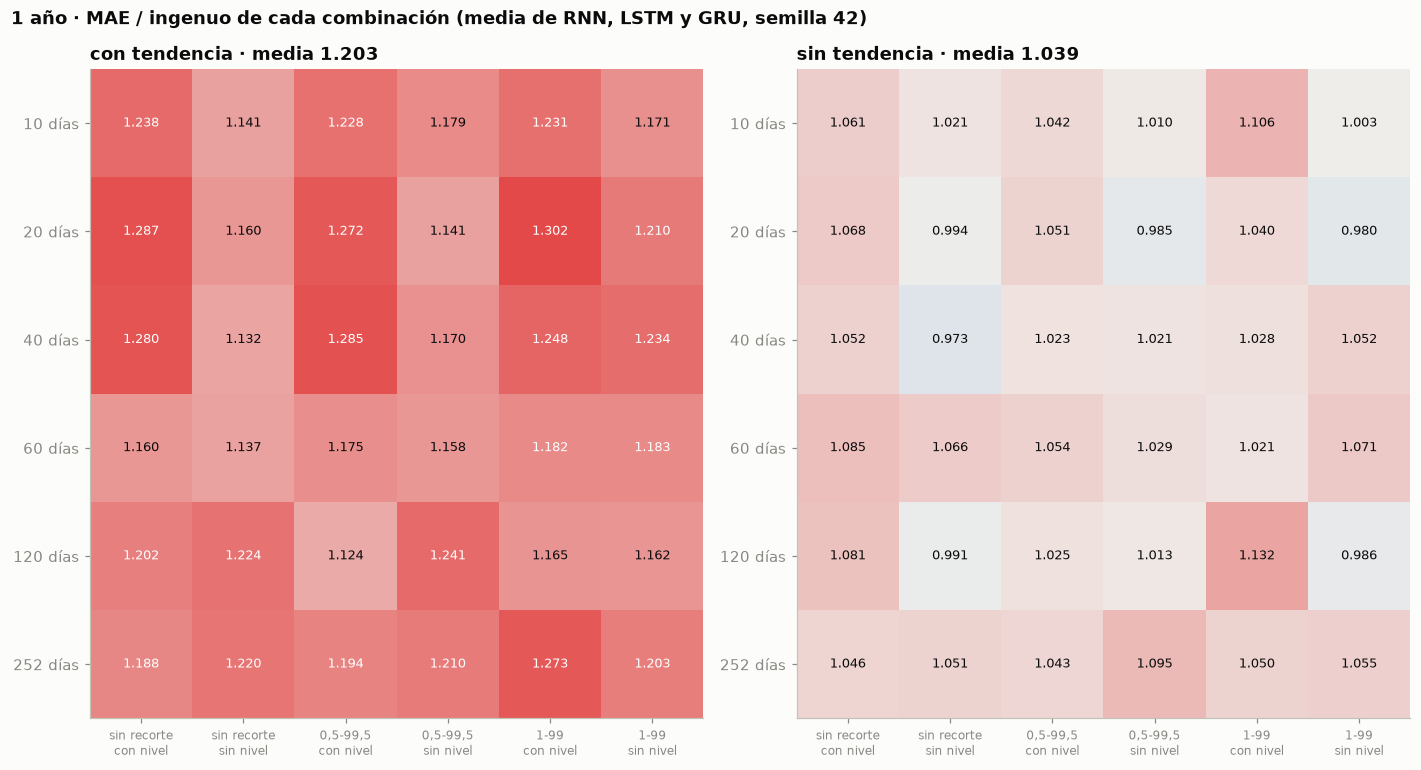

In [29]:
tablas = {nombre: comparacion[nombre].unstack(["recorte", "nivel"]).reindex(columns=list(NOMBRE_VARIANTE))
          for nombre in ["con tendencia", "sin tendencia"]}
distancia = max(max(abs(t.values - 1).max() for t in tablas.values()), 0.05)
norma = TwoSlopeNorm(vcenter=1, vmin=1 - distancia, vmax=1 + distancia)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.75 * len(config.VENTANAS) + 2.6))
for ax, (nombre, tabla) in zip(axes, tablas.items()):
    ax.imshow(tabla.values, cmap=DIVERGENTE.reversed(), norm=norma, aspect="auto")
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            valor = tabla.values[i, j]
            ax.text(j, i, f"{valor:.3f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if abs(valor - 1) > 0.6 * distancia else TINTA)
    ax.set_xticks(range(tabla.shape[1]), [NOMBRE_VARIANTE[c] for c in tabla.columns], fontsize=8)
    ax.set_yticks(range(tabla.shape[0]), [f"{v} días" for v in tabla.index])
    ax.grid(False)
    ax.set_title(f"{nombre} · media {tabla.values.mean():.3f}")
fig.suptitle("1 año · MAE / ingenuo de cada combinación (media de RNN, LSTM y GRU, semilla 42)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

Efecto medio de cada opción (media de las combinaciones que la llevan), con y sin tendencia:

In [30]:
columnas = ["con tendencia", "sin tendencia"]
efectos = pd.concat({
    "indicador de nivel": comparacion.groupby(level="nivel")[columnas].mean()
                          .rename(index={False: "sin", True: "con"}),
    "recorte": comparacion.groupby(level="recorte")[columnas].mean().reindex(["ninguno", "0.5-99.5", "1-99"]),
    "ventana": comparacion.groupby(level="ventana")[columnas].mean().rename(index=lambda v: f"{v} días"),
}, names=["opción", "valor"])
efectos.round(3)

con tendencia  sin tendencia
opción             valor                                 
indicador de nivel sin               1.182          1.022
                   con               1.224          1.056
recorte            ninguno           1.197          1.041
                   0.5-99.5          1.198          1.032
                   1-99              1.214          1.044
ventana            10 días           1.198          1.041
                   20 días           1.229          1.020
                   40 días           1.225          1.025
                   60 días           1.166          1.054
                   120 días          1.186          1.038
                   252 días          1.215          1.057

Las 10 mejores combinaciones sin tendencia:

In [31]:
comparacion.sort_values("sin tendencia").head(10).round(3)

con tendencia  sin tendencia  mejora
ventana recorte  nivel                                      
40      ninguno  False          1.132          0.973   0.159
20      1-99     False          1.210          0.980   0.231
        0.5-99.5 False          1.141          0.985   0.156
120     1-99     False          1.162          0.986   0.176
        ninguno  False          1.224          0.991   0.233
20      ninguno  False          1.160          0.994   0.166
10      1-99     False          1.171          1.003   0.168
        0.5-99.5 False          1.179          1.010   0.169
120     0.5-99.5 False          1.241          1.013   0.228
40      0.5-99.5 False          1.170          1.021   0.149

### 5.2 Confirmación con semillas y regla aplicada

Las 3 mejores de la fase A sin tendencia, con las tres semillas (media de las tres redes). Misma regla que en la sección 3: empatan con la mejor las que quedan a menos de un ruido de ella, y entre las empatadas gana la ventana más corta y, después, la más sencilla.

In [32]:
fin_sin = pd.DataFrame([{**f, "recorte": ex.nombre_recorte(f["recorte"])}
                        for f in ex.finalistas(a_sin) if f["horizonte"] == "largo"])
todas_sin = pd.concat([a_sin.merge(fin_sin[ex.CLAVE_DATOS], on=ex.CLAVE_DATOS), semillas_sin], ignore_index=True)
todas_sin["semilla"] = todas_sin["semilla"].astype(int)
por_semilla_sin = ex.resumir(todas_sin, por=["semilla"])
media_sin = (por_semilla_sin.groupby(ex.CLAVE_DATOS + ["semilla"])["MAE / ingenuo"].mean().unstack("semilla")
             .reindex(pd.MultiIndex.from_frame(fin_sin[ex.CLAVE_DATOS])))
tabla_sin, ruido_sin = ex.decidir(media_sin.loc["largo"])
nueva = tabla_sin.index[tabla_sin["elegida"].to_numpy()][0]
mejor_a = tabla_sin.iloc[0]
print(f"Ruido entre semillas: {ruido_sin:.3f} (con tendencia, sección 3: {decisiones['largo'][1]:.3f}) · "
      f"la mejor de la fase A pasa de {mejor_a[config.SEMILLA]:.3f} a "
      f"{mejor_a[[s for s in SEMILLAS if s != config.SEMILLA]].mean():.3f} con las semillas nuevas")
tabla_sin.rename(columns=nombres).round(3)

Ruido entre semillas: 0.060 (con tendencia, sección 3: 0.033) · la mejor de la fase A pasa de 0.973 a 1.042 con las semillas nuevas


semilla                 semilla 42 (fase A)  semilla 43  semilla 44  media  desviación  empata con la mejor  elegida
ventana recorte  nivel                                                                                              
40      ninguno  False                0.973       1.102       0.981  1.019       0.072                 True    False
20      1-99     False                0.980       1.083       0.978  1.014       0.060                 True    False
        0.5-99.5 False                0.985       1.080       1.015  1.027       0.048                 True     True

Cada red por separado:

In [33]:
por_red_sin = por_semilla_sin.pivot_table(index=["ventana", "recorte", "nivel", "modelo"], columns="semilla",
                                          values="MAE / ingenuo")
por_red_sin["media"] = por_red_sin.mean(axis=1)
por_red_sin.rename(columns=nombres).round(3)

semilla                        semilla 42 (fase A)  semilla 43  semilla 44  media
ventana recorte  nivel modelo                                                    
20      0.5-99.5 False GRU                   1.005       1.164       1.020  1.063
                       LSTM                  0.961       1.044       1.014  1.006
                       RNN                   0.990       1.032       1.012  1.011
        1-99     False GRU                   1.014       1.175       0.925  1.038
                       LSTM                  0.944       1.053       1.016  1.004
                       RNN                   0.981       1.023       0.993  0.999
40      ninguno  False GRU                   0.987       0.999       1.035  1.007
                       LSTM                  0.943       1.349       0.916  1.069
                       RNN                   0.989       0.958       0.992  0.980

### 5.3 La nueva elección frente a la anterior, año a año

Media de las tres redes y las tres semillas en cada año de validación y en los tres años juntos. Para comparar:
- la elección anterior, también sin tendencia (sección 4);
- el lineal sin tendencia con la misma combinación (con su mejor fuerza de regularización) y su mejor versión (sección 4.4);
- el «modelo» que solo prevé la subida media del train (sección 4.1).

In [34]:
def por_años(df):
    """«MAE / ingenuo» en cada año y en los años juntos (media de los modelos y, si hay, de las semillas)."""
    extra = ["semilla"] if "semilla" in df and df["semilla"].notna().any() else []
    años = ex.resumir(df, por=extra + ["pliegue"]).groupby("pliegue")["MAE / ingenuo"].mean()
    juntos = ex.resumir(df, por=extra)["MAE / ingenuo"].mean()
    return pd.Series({**{f"año {a}": v for a, v in años.items()}, "años juntos": juntos})


def filtrar(df, ventana, recorte, nivel, alfa=None):
    sel = (df["horizonte"] == "largo") & (df["ventana"] == ventana) & (df["recorte"] == recorte) & (df["nivel"] == nivel)
    return df[sel & (df["alfa"] == alfa)] if alfa is not None else df[sel]


def nombre_comb(v, r, n):
    return f"{v} días · {'sin recorte' if r == 'ninguno' else 'recorte ' + r} · {'con' if n else 'sin'} nivel"


anterior = (elegidas["largo"]["ventana"], ex.nombre_recorte(elegidas["largo"]["recorte"]), elegidas["largo"]["nivel"])
lin_sin = ex.resumir(sin_tend[(sin_tend["modelo"] == "Lineal") & (sin_tend["horizonte"] == "largo")])
alfa_nueva = filtrar(lin_sin, *nueva).set_index("alfa")["MAE / ingenuo"].idxmin()
mejor_lin = lin_sin.loc[lin_sin["MAE / ingenuo"].idxmin()]
media_nueva = pd.DataFrame(ex.solo_la_media([ex.eleccion(a_sin, semillas_sin, horizontes=["largo"])["largo"]]))

filas = {
    f"Redes · nueva: {nombre_comb(*nueva)}": por_años(filtrar(todas_sin, *nueva)),
    f"Redes · anterior: {nombre_comb(*anterior)}": por_años(filtrar(variantes[variantes["tendencia"] == "sin"], *anterior)),
    f"Lineal · {nombre_comb(*nueva)} · alfa {alfa_nueva:g}": por_años(filtrar(sin_tend, *nueva, alfa=alfa_nueva)),
    f"Lineal · mejor: {nombre_comb(mejor_lin['ventana'], mejor_lin['recorte'], mejor_lin['nivel'])} · alfa {mejor_lin['alfa']:g}":
        por_años(filtrar(sin_tend, mejor_lin["ventana"], mejor_lin["recorte"], mejor_lin["nivel"], alfa=mejor_lin["alfa"])),
    "Solo la media del train (nueva combinación)": por_años(media_nueva),
}
pd.DataFrame(filas).T.round(3)

,año 2018,año 2019,año 2020,años juntos
Redes · nueva: 20 días · recorte 0.5-99.5 · sin nivel,1.016,1.434,0.716,1.027
Redes · anterior: 120 días · recorte 0.5-99.5 · con nivel,0.925,1.676,0.593,1.044
Lineal · 20 días · recorte 0.5-99.5 · sin nivel · alfa 1,0.750,1.038,0.672,0.820
Lineal · mejor: 120 días · sin recorte · sin nivel · alfa 1,1.362,0.851,0.417,0.714
Solo la media del train (nueva combinación),1.858,1.171,0.964,1.169


### 5.4 Datos de partida para la fase B

Los datos elegidos para cada horizonte, todos sin tendencia: a 1 semana y a 3 meses, los de la sección 3; a 1 año, los de esta sección. «MAE / ingenuo» es la media de las tres redes y las tres semillas, sin tendencia, con la estructura base.

In [35]:
partida = {}
for h in config.HORIZONTES:
    if h == "largo":
        (v, r, n), valor, ruido, origen = nueva, tabla_sin.loc[nueva, "media"], ruido_sin, "sección 5 (D21)"
    else:
        c = elegidas[h]
        v, r, n = c["ventana"], ex.nombre_recorte(c["recorte"]), c["nivel"]
        valor, ruido, origen = media_var.loc[h, "sin"], decisiones[h][1], "sección 3 (D19)"
    partida[h] = {"ventana (días)": v, "recorte": r, "indicador de nivel": "con" if n else "sin",
                  "MAE / ingenuo": round(valor, 3), "ruido": round(ruido, 3), "elegida en": origen}
pd.DataFrame(partida).T

,ventana (días),recorte,indicador de nivel,MAE / ingenuo,ruido,elegida en
corto,252,ninguno,sin,0.993,0.002,sección 3 (D19)
medio,20,ninguno,sin,0.937,0.011,sección 3 (D19)
largo,20,0.5-99.5,sin,1.027,0.060,sección 5 (D21)


### 5.5 Lectura

> 324 entrenamientos de la fase A sin tendencia (36 combinaciones × 3 redes × 3 años de validación), en 1,26 h en el portátil, y 54 de la confirmación con semillas, en 4 minutos. La combinación elegida antes (120 días, con nivel) da exactamente los mismos números que en la sección 4: las dos tandas son comparables.

**Sin tendencia mejoran las 36 combinaciones.** De media pasan de 1,20 a 1,04; la que menos mejora, 0,03, y la que más, 0,26. Ninguna empeora.

**El indicador de nivel deja de destacar.** Las 11 mejores combinaciones son sin nivel, y de media el indicador empeora a las redes (1,056 con él frente a 1,022 sin él). La elegida antes, con nivel, queda en el puesto 14 de 36: con tendencia ganaba en parte porque compensaba la tendencia. El recorte apenas importa (1,03-1,04), y entre las ventanas van mejor las cortas (20 y 40 días: 1,02-1,03) que las de 60 y 252 días (1,05-1,06).

**Confirmación con semillas: otra vez, parte de la ventaja era suerte.**
- La mejor de la fase A (40 días, sin recorte, 0,973) pasa a 1,042 con las semillas nuevas. Ninguna finalista baja de 1 en la media de las tres semillas.
- El azar entre semillas es el doble que con tendencia (0,060 frente a 0,033). Una red sola puede cambiar mucho: la LSTM con 40 días da 0,92 con una semilla y 1,35 con otra (2,6 en 2018).
- Las tres finalistas empatan (1,014-1,027). Gana la ventana más corta (20 días) y, con la misma ventana, el recorte más suave (0,5-99,5). La de 1-99 tiene una media algo mejor, pero la diferencia (0,013) es una quinta parte del azar.

**Elección de 1 año: 20 días, recorte 0,5-99,5, sin nivel (1,027).**
- Frente a la anterior sin tendencia (1,044), la diferencia está dentro del azar: rinden igual. Pero la nueva es más sencilla (sin indicador de nivel), entrena más rápido (20 días frente a 120) y es más regular año a año: 1,02 / 1,43 / 0,72, frente a 0,93 / 1,68 / 0,59. Apuesta menos.
- Con la estructura base, las redes **siguen sin mejorar al ingenuo a 1 año**. Sin tendencia, una red que no aprende nada da exactamente 1: prevé «sin cambio», como el ingenuo. Que den 1,03 quiere decir que lo que aprenden, a 1 año, de media resta en vez de sumar: ayuda en 2020 y perjudica en 2019.

**El lineal, con los mismos datos, sí mejora al ingenuo: 0,82** (0,75 en 2018, 1,04 en 2019 y 0,67 en 2020). Es la comparación más limpia que tenemos a 1 año: mismos datos, mismos años de validación, sin tendencia; solo cambia el modelo. Apunta a que el problema de las redes a 1 año no está en los datos, sino en cómo aprenden: con muy pocas respuestas independientes, una red de miles de parámetros aprende cosas que no se repiten, y el lineal, mucho más sencillo, no. Es lo que tendrá que atacar la fase B (redes más pequeñas o más reguladas), con el lineal (0,82 con estos datos) como listón.

**Lo esperado frente a lo obtenido:** se cumplió todo lo apuntado antes de lanzar. Mejoran todas las combinaciones; el indicador de nivel deja de destacar y las finalistas son todas sin nivel; y la mejor media confirmada queda entre 1,00 y 1,05 (1,014-1,027). No lo esperábamos: que el azar entre semillas se duplicara sin tendencia.

**Datos de partida para la fase B** (tabla 5.4), todos sin tendencia: 1 semana, 252 días (0,993); 3 meses, 20 días (0,937); 1 año, 20 días con recorte 0,5-99,5 (1,027).

## 6. Fase B: la mejor configuración de cada red (D22-D25)

**Pregunta:** con los datos ya elegidos (tabla 5.4), ¿hay una configuración de cada red mejor que la estructura base?

**Cómo se busca** (igual para las tres redes, en cada horizonte):
- **Optuna** propone configuraciones dentro del mismo espacio: neuronas 8-128, 1 o 2 capas, dropout 0-0,5, velocidad de aprendizaje 0,0001-0,003, regularización L2 (sí o no, y cuánta) y lote 32, 64 o 128.
- **Intentos por red:** 40 a 1 año y a 3 meses, y 20 a 1 semana (D24), donde cada intento es lento por la ventana de 252 días. El 1.º es la estructura base; los 10 primeros son al azar e iguales para las tres redes, y después Optuna propone cerca de lo que mejor va.
- **Puntuación:** «MAE / ingenuo» juntando los años de validación. A 1 año, media de 3 semillas en cada intento, porque el azar entre semillas es grande; a 3 meses y a 1 semana, una semilla.
- **Poda:** desde el 11.º intento, un intento que va peor que la mediana de los anteriores tras el 2.º o el 3.º año se abandona.
- **Final:** las 3 mejores de cada red y la estructura base (D23) se miden con las semillas 42, 43 y 44. Gana la mejor media; las que quedan a menos de un ruido de ella empatan y, entre ellas, gana la de menos parámetros.
- **Ampliación (D25):** si la elegida está en el último cuarto de los intentos, esa red recibe 20 más, una sola vez. Solo pasó con la LSTM a 1 año.

Lo hace `scripts/fase_b.py`, que guarda en `resultados/fase_b.csv` (cada entrenamiento), `fase_b_intentos.csv` (cada intento), `fase_b_semillas.csv` (la final) y sus curvas de aprendizaje.

In [36]:
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr

from oil_price import busqueda as bu

b_entrenos, b_intentos, b_confirmados = bu.leer_resultados()
b_eleccion = bu.eleccion()
HORIZONTE = {"corto": "1 semana", "medio": "3 meses", "largo": "1 año"}
pares = pd.MultiIndex.from_product([list(config.HORIZONTES), config.CELDAS], names=["horizonte", "red"])


def por_par(serie):
    return serie.rename_axis(["horizonte", "red"]).reindex(pares)


estado_b = pd.DataFrame({
    "intentos": por_par(b_intentos.groupby(["horizonte", "modelo"]).size()),
    "podados": por_par(b_intentos[b_intentos["estado"] == "podado"].groupby(["horizonte", "modelo"]).size()).fillna(0),
    "horas de búsqueda": por_par(b_intentos.groupby(["horizonte", "modelo"])["segundos"].sum() / 3600),
    "horas de la final": por_par(b_confirmados.groupby(["horizonte", "modelo"])["segundos"].sum() / 3600).fillna(0),
}).astype({"intentos": int, "podados": int})
print(f"Entrenamientos: {len(b_entrenos):,} en la búsqueda y {len(b_confirmados):,} en la final · "
      f"{estado_b[['horas de búsqueda', 'horas de la final']].sum().sum():.1f} h de cálculo · "
      f"elección completa en {len(b_eleccion)} de {len(pares)} pares red-horizonte")
estado_b.rename(index=HORIZONTE, level="horizonte").round(2)

Entrenamientos: 1,854 en la búsqueda y 184 en la final · 18.3 h de cálculo · elección completa en 9 de 9 pares red-horizonte


C:\Users\Pablo\Desktop\cuarto\aprendizaje automatico\Caso-Oil-Price\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


intentos  podados  horas de búsqueda  horas de la final
horizonte red                                                          
1 semana  RNN         20        2              4.070              1.940
          LSTM        20        4              3.850              1.260
          GRU         20        4              3.200              1.030
3 meses   RNN         40       16              0.090              0.020
          LSTM        40       20              0.400              0.070
          GRU         40       23              0.230              0.060
1 año     RNN         40        0              0.220              0.000
          LSTM        60       10              0.830              0.000
          GRU         40        2              0.980              0.000

**El lineal de referencia** es el de la sección 4.4: sin tendencia, con los mismos datos que las redes en cada horizonte y su mejor fuerza de regularización.

In [37]:
def lineal_fase_b(h):
    """Filas del lineal sin tendencia con los datos de la fase B del horizonte y su mejor regularización."""
    d = config.DATOS_FASE_B[h]
    sel = sin_tend[(sin_tend["modelo"] == "Lineal") & (sin_tend["horizonte"] == h) & (sin_tend["ventana"] == d["ventana"])
                   & (sin_tend["recorte"] == ex.nombre_recorte(d["recorte"])) & (sin_tend["nivel"] == d["nivel"])]
    alfa = ex.resumir(sel).set_index("alfa")["MAE / ingenuo"].idxmin()
    return sel[sel["alfa"] == alfa]


lineal_b = {h: lineal_fase_b(h) for h in config.HORIZONTES}
nota_lineal_b = {h: ex.resumir(f)["MAE / ingenuo"].iloc[0] for h, f in lineal_b.items()}
print("Lineal (MAE / ingenuo): " + " · ".join(
    f"{HORIZONTE[h]} {nota_lineal_b[h]:.3f} (alfa {f['alfa'].iloc[0]:g})" for h, f in lineal_b.items()))

Lineal (MAE / ingenuo): 1 semana 0.993 (alfa 100000) · 3 meses 0.972 (alfa 1000) · 1 año 0.820 (alfa 1)


### 6.1 Cómo avanza la búsqueda

Cada punto es un intento: relleno si se completó y hueco si se podó (su nota es la que llevaba al podarse). La línea es la mejor nota hasta ese intento. A 1 año cada nota es la media de 3 semillas; a 3 meses y a 1 semana, de una. La línea punteada vertical separa los 10 intentos al azar de los que propone Optuna.

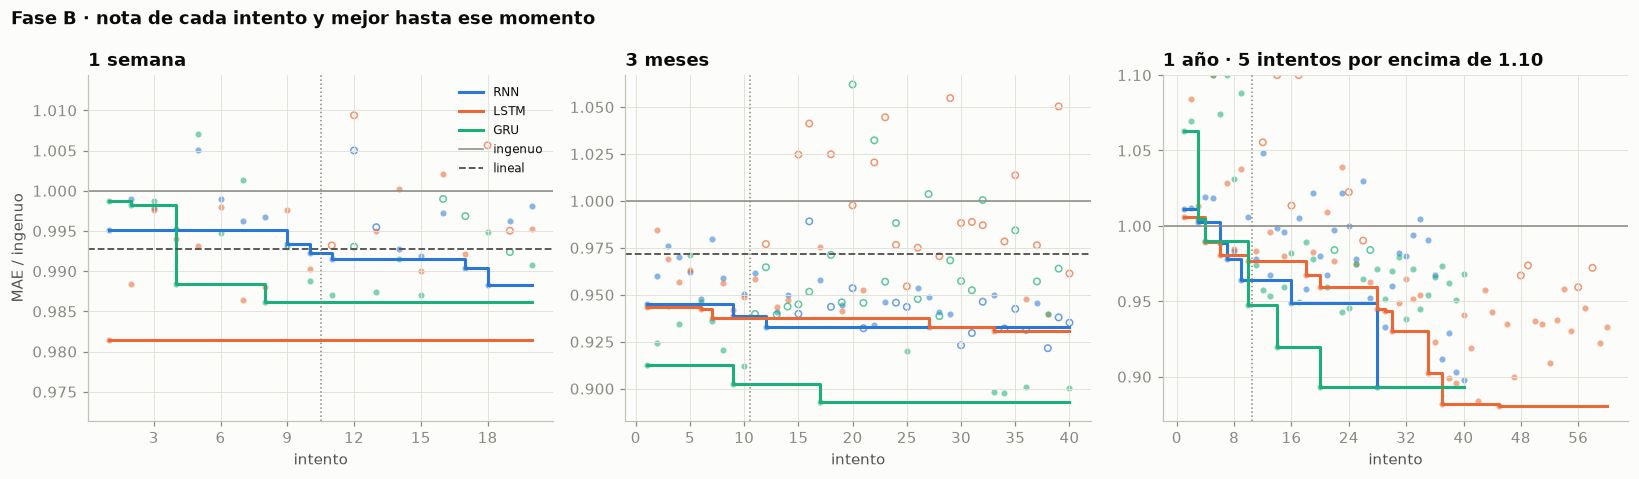

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, h in zip(axes, config.HORIZONTES):
    datos_h = b_intentos[b_intentos["horizonte"] == h]
    techo = min(datos_h["MAE / ingenuo"].max() + 0.005, 1.10)
    for red in config.CELDAS:
        d = datos_h[datos_h["modelo"] == red].sort_values("intento")
        completo = d["estado"] == "completo"
        ax.scatter(d.loc[completo, "intento"], d.loc[completo, "MAE / ingenuo"].clip(upper=techo),
                   s=16, color=COLOR_RED[red], alpha=0.55, linewidths=0)
        ax.scatter(d.loc[~completo, "intento"], d.loc[~completo, "MAE / ingenuo"].clip(upper=techo),
                   s=18, facecolors="none", edgecolors=COLOR_RED[red], alpha=0.7, linewidths=1)
        mejor = d["MAE / ingenuo"].where(completo).ffill().cummin()
        ax.step(d["intento"], mejor, where="post", color=COLOR_RED[red], linewidth=2, label=red)
    ax.axhline(1, color=TINTA_SUAVE, linewidth=1, label="ingenuo")
    ax.axhline(nota_lineal_b[h], color=TINTA_2, linestyle="--", linewidth=1.2, label="lineal")
    ax.axvline(10.5, color=TINTA_SUAVE, linestyle=":", linewidth=1)
    ax.set_ylim(datos_h["MAE / ingenuo"].min() - 0.01, techo)
    fuera = (datos_h["MAE / ingenuo"] > techo).sum()
    ax.set_title(f"{HORIZONTE[h]}" + (f" · {fuera} intentos por encima de {techo:.2f}" if fuera else ""))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("intento")
axes[0].set_ylabel("MAE / ingenuo")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Fase B · nota de cada intento y mejor hasta ese momento", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 6.2 Qué influye en el error

Correlación de rangos (Spearman) entre cada valor y la nota de los intentos de las tres redes. Positiva: cuanto más alto el valor, **peor** el error. Por encima de 0,3 en valor absoluto empieza a ser una relación clara.

Se usa la nota tras los 2 primeros años de validación (2018-2019), porque la tienen **todos** los intentos, también los podados. Con la nota final solo contarían los que sobrevivieron a la poda, que no son una muestra representativa: a 3 meses se podó la mitad. Aun así, conviene leerlas con cautela, porque Optuna no prueba al azar: cuando se concentra en una zona, sus valores se mueven juntos.

In [39]:
# Nota tras 2018-2019 de cada intento (a 1 año, media de sus 3 semillas)
b_intentos["nota 2 años"] = [
    bu.puntuar(b_entrenos[(b_entrenos["horizonte"] == f["horizonte"]) & (b_entrenos["modelo"] == f["modelo"])
                          & (b_entrenos["intento"] == f["intento"]) & (b_entrenos["pliegue"] <= 2019)])
    for _, f in b_intentos.iterrows()]
l2_efectiva = np.where(b_intentos["con l2"], np.log10(b_intentos["fuerza l2"]), -7)
valores = {"velocidad de aprendizaje": np.log10(b_intentos["lr"]), "lote": b_intentos["lote"],
           "neuronas": np.log2(b_intentos["unidades"]), "capas": b_intentos["capas"],
           "dropout": b_intentos["dropout"], "regularización L2": pd.Series(l2_efectiva, index=b_intentos.index),
           "parámetros": np.log10(b_intentos["parametros"])}
influencia = pd.DataFrame({
    HORIZONTE[h]: {nombre: spearmanr(v[b_intentos["horizonte"] == h],
                                     b_intentos.loc[b_intentos["horizonte"] == h, "nota 2 años"]).correlation
                   for nombre, v in valores.items()}
    for h in config.HORIZONTES})
influencia.round(2)

,1 semana,3 meses,1 año
velocidad de aprendizaje,0.200,-0.060,0.760
lote,-0.060,-0.180,-0.510
neuronas,-0.140,-0.190,-0.170
capas,0.240,0.170,-0.360
dropout,0.020,0.010,-0.100
regularización L2,-0.020,-0.150,-0.350
parámetros,-0.040,0.240,-0.320


La velocidad de aprendizaje frente a la nota tras 2 años, con el tamaño de lote en color:

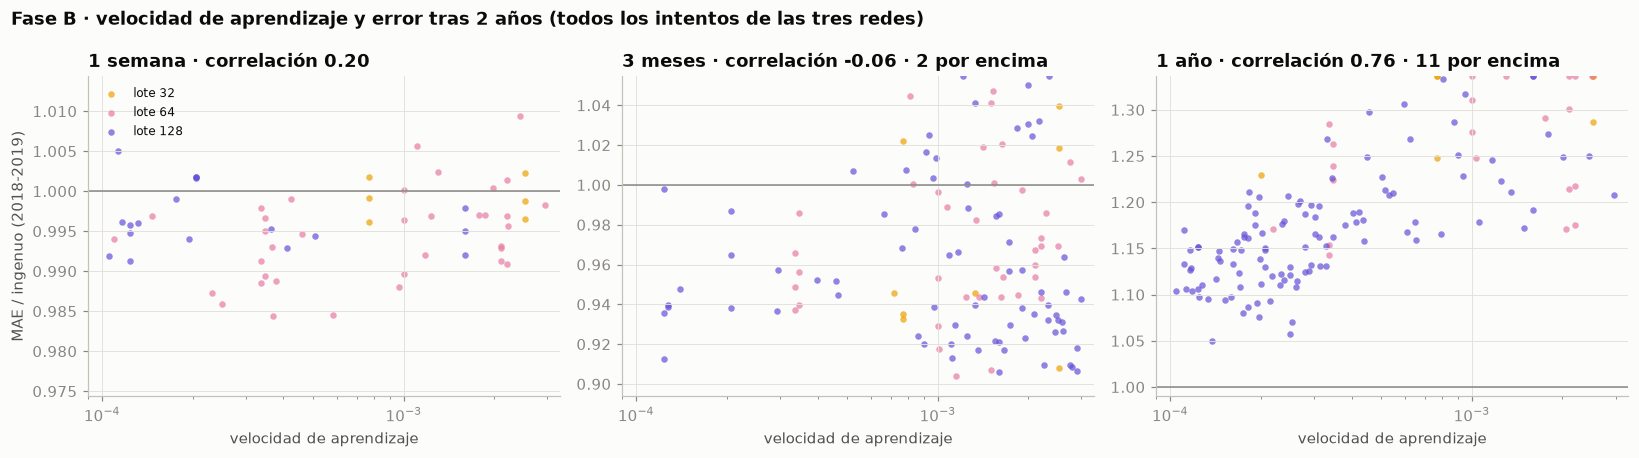

In [40]:
COLOR_LOTE = {32: C["amarillo"], 64: C["magenta"], 128: C["violeta"]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, h in zip(axes, config.HORIZONTES):
    d = b_intentos[b_intentos["horizonte"] == h]
    techo = min(d["nota 2 años"].max() + 0.005, d["nota 2 años"].quantile(0.9) + 0.03)
    for lote, g in d.groupby("lote"):
        ax.scatter(g["lr"], g["nota 2 años"].clip(upper=techo), s=18, color=COLOR_LOTE[lote], alpha=0.7,
                   linewidths=0, label=f"lote {lote}")
    ax.axhline(1, color=TINTA_SUAVE, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(9e-5, 3.3e-3)
    ax.set_ylim(min(d["nota 2 años"].min(), 1) - 0.01, techo)
    fuera = (d["nota 2 años"] > techo).sum()
    ax.set_title(f"{HORIZONTE[h]} · correlación {influencia.loc['velocidad de aprendizaje', HORIZONTE[h]]:.2f}"
                 + (f" · {fuera} por encima" if fuera else ""))
    ax.set_xlabel("velocidad de aprendizaje")
axes[0].set_ylabel("MAE / ingenuo (2018-2019)")
axes[0].legend(fontsize=8)
fig.suptitle("Fase B · velocidad de aprendizaje y error tras 2 años (todos los intentos de las tres redes)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 6.3 La final: las finalistas con tres semillas

Las 3 mejores de cada red y la estructura base (intento 1), con las semillas 42, 43 y 44. A 3 meses y a 1 semana la semilla 42 es la de la búsqueda: si las finalistas empeoran con la 43 y la 44, es que ganaron la primera ronda en parte por suerte.

In [41]:
SEMILLAS_B = [config.SEMILLA, *config.SEMILLAS_EXTRA]
final = []
for (h, red), (tabla, ruido) in b_eleccion.items():
    t = tabla.rename(columns={s: f"semilla {s}" for s in SEMILLAS_B}).reset_index()
    t.insert(0, "red", red)
    t.insert(0, "horizonte", HORIZONTE[h])
    t["ruido"] = ruido
    final.append(t)
final = pd.concat(final, ignore_index=True).set_index(["horizonte", "red", "intento"])
suerte = (final.groupby(level=["horizonte", "red"], sort=False)
          .apply(lambda t: pd.Series({"semilla 42": t["semilla 42"].mean(),
                                      "semillas 43 y 44": t[["semilla 43", "semilla 44"]].values.mean()})))
print("Media de las finalistas con la semilla de la búsqueda y con las nuevas:")
print(suerte.round(3).to_string())
final.round(3)

Media de las finalistas con la semilla de la búsqueda y con las nuevas:
                semilla 42  semillas 43 y 44
horizonte red                               
1 semana  RNN        0.991             0.996
          LSTM       0.985             0.992
          GRU        0.990             0.994
3 meses   RNN        0.938             0.951
          LSTM       0.936             0.952
          GRU        0.900             0.951
1 año     RNN        0.917             0.931
          LSTM       0.901             0.919
          GRU        0.952             0.955


semilla                 semilla 42  semilla 43  semilla 44  media  desviación  parámetros  empata con la mejor  elegida  ruido
horizonte red  intento                                                                                                        
1 semana  RNN  18            0.988       0.999       0.988  0.992       0.006       25381                 True    False  0.004
               17            0.990       0.997       0.999  0.995       0.004       38296                 True    False  0.004
               11            0.992       0.994       0.995  0.994       0.002        4789                 True     True  0.004
               1             0.995       0.998       0.998  0.997       0.002        4737                False    False  0.004
          LSTM 1             0.981       0.993       0.991  0.988       0.006       18753                 True    False  0.005
               7             0.986       0.995       0.990  0.990       0.004      172399                 True    False  0.005
               8             0.988       0.989       0.995  0.991       0.004        2968                 True     True  0.005
          GRU  8             0.986       0.990       0.993  0.990       0.003        2232                 True    False  0.005
               15            0.987       0.996       0.998  0.994       0.006         417                 True     True  0.005
               11            0.987       0.997       0.998  0.994       0.006         417                 True    False  0.005
               1             0.999       0.991       0.990  0.993       0.005       14081                 True    False  0.005
3 meses   RNN  12            0.933       0.957       0.956  0.949       0.014        6060                 True    False  0.018
               22            0.934       0.978       0.944  0.952       0.023       15852                 True    False  0.018
               9             0.939       0.927       0.964  0.943       0.019        5160                 True    False  0.018
               1             0.945       0.928       0.957  0.943       0.014        4737                 True     True  0.018
          LSTM 33            0.931       0.958       0.960  0.949       0.016       46248                 True    False  0.017
               27            0.933       0.940       0.956  0.943       0.012       13198                 True     True  0.017
               7             0.938       0.921       0.989  0.949       0.035      172399                 True    False  0.017
               1             0.944       0.943       0.951  0.946       0.004       18753                 True    False  0.017
          GRU  17            0.893       0.940       0.987  0.940       0.047       51801                 True    False  0.033
               34            0.897       0.950       0.966  0.938       0.036      104729                 True    False  0.033
               33            0.898       0.935       0.977  0.937       0.039       35564                 True    False  0.033
               1             0.912       0.924       0.930  0.922       0.009       14081                 True     True  0.033
1 año     RNN  28            0.893       0.891       0.895  0.893       0.002        6376                 True     True  0.015
               40            0.898       0.915       0.881  0.898       0.017       17137                 True    False  0.015
               39            0.886       0.925       0.898  0.903       0.020       15852                 True    False  0.015
               1             0.990       1.032       1.012  1.011       0.021        4737                False    False  0.015
          LSTM 45            0.875       0.888       0.879  0.881       0.006      184099                 True    False  0.021
               37            0.883       0.896       0.867  0.882       0.014      175288                 True     True  0.021
               42            0.883       0.905       0.864  0.8

### 6.4 Resultado: elegida frente a la base y al lineal

La configuración elegida de cada red, con la media de las tres semillas, frente a la estructura base (también con tres semillas) y al lineal con los mismos datos.

In [42]:
filas = []
for h in config.HORIZONTES:
    for red in config.CELDAS:
        tabla, ruido = b_eleccion[(h, red)]
        i = int(tabla.index[tabla["elegida"]][0])
        fila = b_intentos[(b_intentos["horizonte"] == h) & (b_intentos["modelo"] == red)
                          & (b_intentos["intento"] == i)].iloc[0]
        filas.append({"horizonte": HORIZONTE[h], "red": red, "base": tabla.loc[1, "media"],
                      "elegida": tabla.loc[i, "media"], "ruido": ruido, "lineal": nota_lineal_b[h],
                      "intento": i, "parámetros": int(fila["parametros"]), "configuración": bu.describir(fila)})
resultado_b = pd.DataFrame(filas).set_index(["horizonte", "red"])
elegidos_b = {(h, red): int(resultado_b.loc[(HORIZONTE[h], red), "intento"])
              for h in config.HORIZONTES for red in config.CELDAS}
resultado_b.round(3)

base  elegida  ruido  lineal  intento  parámetros                                      configuración
horizonte red                                                                                                       
1 semana  RNN  0.997    0.994  0.004   0.993       11        4789  38 neuronas × 2 capas · dropout 0.02 · lr 0.00...
          LSTM 0.988    0.991  0.005   0.993        8        2968  23 neuronas × 1 capa · dropout 0.41 · lr 0.000...
          GRU  0.993    0.994  0.005   0.993       15         417  8 neuronas × 1 capa · dropout 0.25 · lr 0.0003...
3 meses   RNN  0.943    0.943  0.018   0.972        1        4737  64 neuronas × 1 capa · dropout 0.20 · lr 0.001...
          LSTM 0.946    0.943  0.017   0.972       27       13198  53 neuronas × 1 capa · dropout 0.08 · lr 0.001...
          GRU  0.922    0.922  0.033   0.972        1       14081  64 neuronas × 1 capa · dropout 0.20 · lr 0.001...
1 año     RNN  1.011    0.893  0.015   0.820       28        6376  75 neuronas × 1 capa · dropout 0.21 · lr 0.000...
          LSTM 1.006    0.882  0.021   0.820       37      175288  119 neuronas × 2 capas · dropout 0.34 · lr 0.0...
          GRU  1.063    0.893  0.039   0.820       20      108649  108 neuronas × 2 capas · dropout 0.10 · lr 0.0...

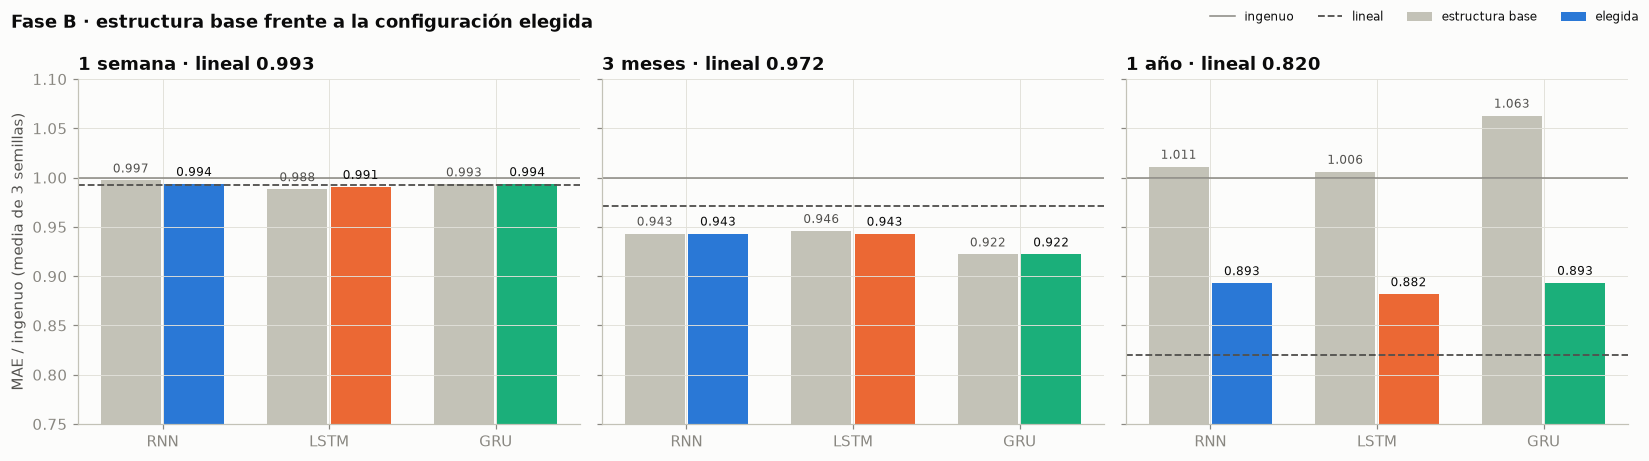

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
x = np.arange(len(config.CELDAS))
for ax, h in zip(axes, config.HORIZONTES):
    r = resultado_b.loc[HORIZONTE[h]].reindex(config.CELDAS)
    ax.bar(x - 0.19, r["base"], width=0.36, color=EJE, label="estructura base")
    ax.bar(x + 0.19, r["elegida"], width=0.36, color=[COLOR_RED[red] for red in config.CELDAS], label="elegida")
    for xi, (b, e) in enumerate(zip(r["base"], r["elegida"])):
        ax.text(xi - 0.19, b + 0.005, f"{b:.3f}", ha="center", va="bottom", fontsize=8, color=TINTA_2)
        ax.text(xi + 0.19, e + 0.005, f"{e:.3f}", ha="center", va="bottom", fontsize=8, color=TINTA)
    ax.axhline(1, color=TINTA_SUAVE, linewidth=1, label="ingenuo")
    ax.axhline(nota_lineal_b[h], color=TINTA_2, linestyle="--", linewidth=1.2, label="lineal")
    ax.set_xticks(x, config.CELDAS)
    ax.set_ylim(0.75, 1.1)
    ax.set_title(f"{HORIZONTE[h]} · lineal {nota_lineal_b[h]:.3f}")
axes[0].set_ylabel("MAE / ingenuo (media de 3 semillas)")
fig.suptitle("Fase B · estructura base frente a la configuración elegida", x=0.01, ha="left", fontweight="bold")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

Año a año (media de las tres redes y las tres semillas):

In [44]:
def filas_b(h, intentos):
    """Entrenamientos (búsqueda y final) de los intentos dados {red: intento} en un horizonte."""
    t = pd.concat([b_entrenos, b_confirmados], ignore_index=True)
    sel = [t[(t["horizonte"] == h) & (t["modelo"] == red) & (t["intento"] == i)] for red, i in intentos.items()]
    return pd.concat(sel, ignore_index=True)


def años_b(df, extra=("semilla",)):
    años = ex.resumir(df, por=[*extra, "pliegue"]).groupby("pliegue")["MAE / ingenuo"].mean()
    juntos = ex.resumir(df, por=list(extra))["MAE / ingenuo"].mean()
    return pd.Series({**{str(a): v for a, v in años.items()}, "años juntos": juntos})


por_año_b = {}
for h in config.HORIZONTES:
    por_año_b[(HORIZONTE[h], "base")] = años_b(filas_b(h, {red: 1 for red in config.CELDAS}))
    por_año_b[(HORIZONTE[h], "elegidas")] = años_b(filas_b(h, {red: elegidos_b[(h, red)] for red in config.CELDAS}))
    por_año_b[(HORIZONTE[h], "lineal")] = años_b(lineal_b[h], extra=())
# A 1 año, 2021 no se evalúa: solo tiene 1 respuesta antes del test
pd.DataFrame(por_año_b).T.round(3).astype(object).fillna("—")

2018  2019  2020  2021 años juntos
1 semana base     0.993 1.000 0.984 0.999       0.993
         elegidas 0.993 0.998 0.986 0.997       0.993
         lineal   1.005 0.997 0.986 0.984       0.993
3 meses  base     0.974 0.938 0.931 0.888       0.937
         elegidas 0.972 0.937 0.935 0.874       0.936
         lineal   1.016 0.887 0.940 1.139       0.972
1 año    base     1.016 1.434 0.716     —       1.027
         elegidas 1.009 1.099 0.693     —       0.889
         lineal   0.750 1.038 0.672     —       0.820

### 6.5 Curvas de aprendizaje de las elegidas

Pérdida en el train y en el trozo final del train que decide cuándo parar (parada temprana), época a época, en el pliegue de 2019 con la semilla 42. En gris, la pérdida de parada de la estructura base. La línea vertical marca la mejor época de la elegida: la versión que se guarda.

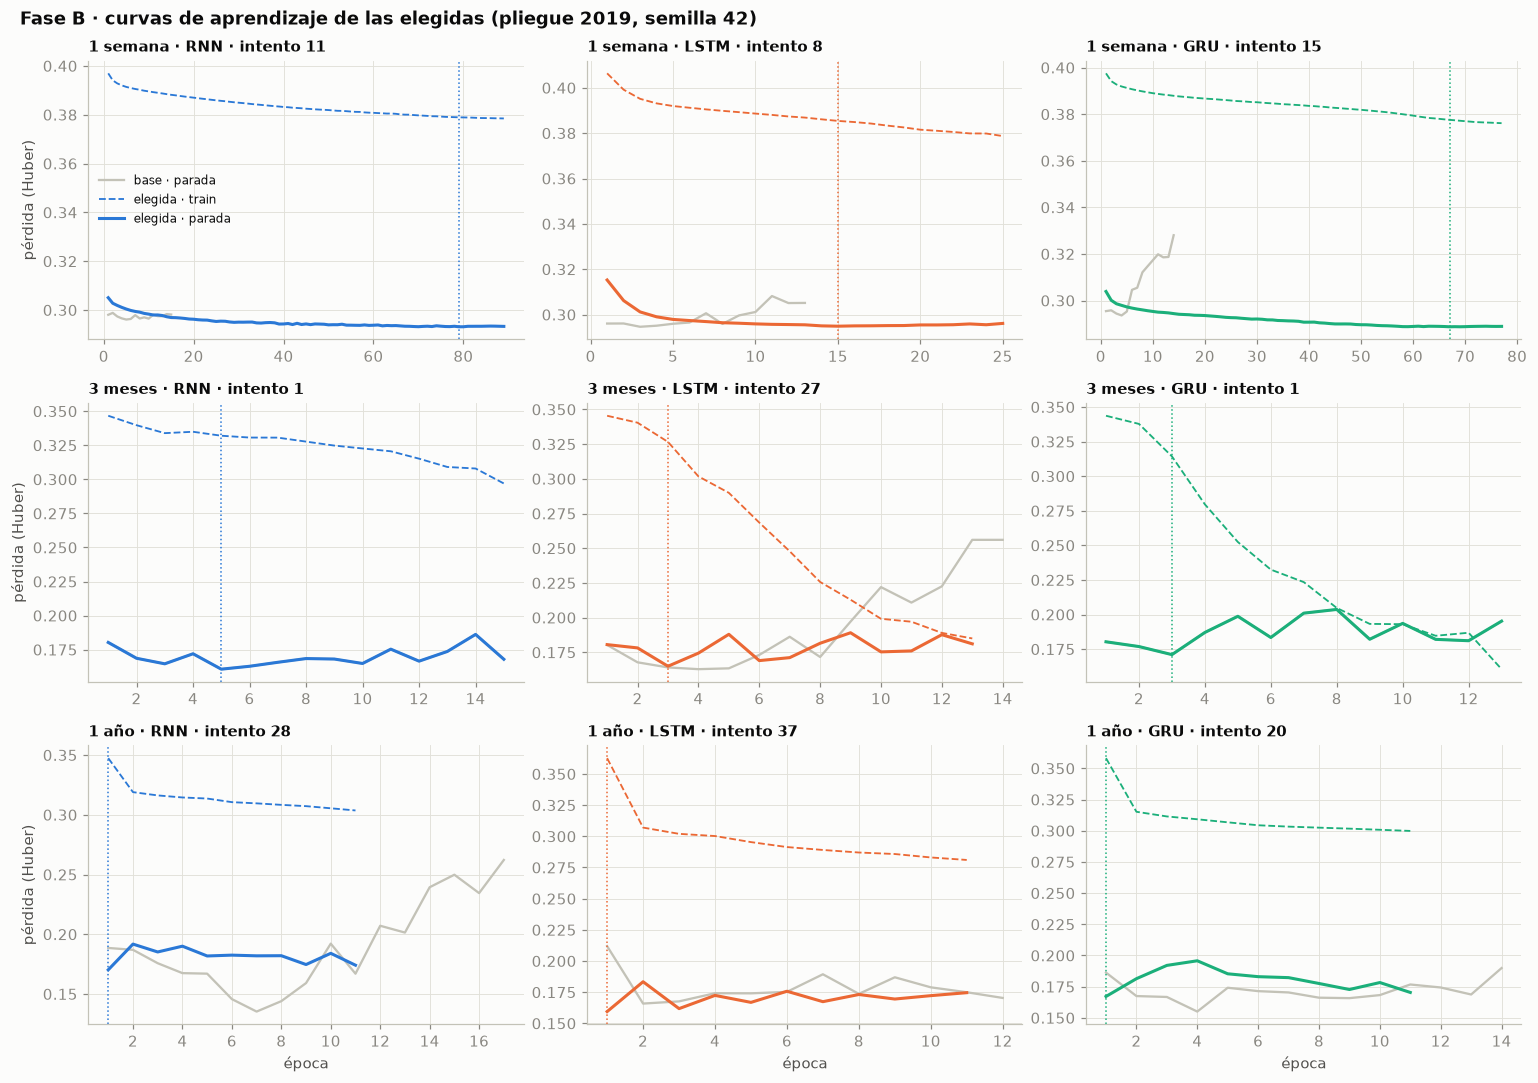

In [45]:
curvas_b = pd.read_csv(config.DIR_RESULTADOS / bu.ARCHIVOS["curvas"])
AÑO_CURVA = 2019
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for fila_ax, h in zip(axes, config.HORIZONTES):
    for ax, red in zip(fila_ax, config.CELDAS):
        i = elegidos_b[(h, red)]

        def curva(intento):
            return curvas_b[(curvas_b["horizonte"] == h) & (curvas_b["modelo"] == red) & (curvas_b["intento"] == intento)
                            & (curvas_b["pliegue"] == AÑO_CURVA) & (curvas_b["semilla"] == config.SEMILLA)]

        c, cb = curva(i), curva(1)
        ax.plot(cb["época"], cb["pérdida parada"], color=EJE, linewidth=1.5, label="base · parada")
        ax.plot(c["época"], c["pérdida train"], color=COLOR_RED[red], linestyle="--", linewidth=1.2, label="elegida · train")
        ax.plot(c["época"], c["pérdida parada"], color=COLOR_RED[red], linewidth=2, label="elegida · parada")
        mejor = b_entrenos[(b_entrenos["horizonte"] == h) & (b_entrenos["modelo"] == red) & (b_entrenos["intento"] == i)
                           & (b_entrenos["pliegue"] == AÑO_CURVA) & (b_entrenos["semilla"] == config.SEMILLA)]["mejor época"]
        if len(mejor):
            ax.axvline(mejor.iloc[0], color=COLOR_RED[red], linestyle=":", linewidth=1)
        ax.set_title(f"{HORIZONTE[h]} · {red} · intento {i}", fontsize=10)
        if red == config.CELDAS[0]:
            ax.set_ylabel("pérdida (Huber)")
        if h == "largo":
            ax.set_xlabel("época")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Fase B · curvas de aprendizaje de las elegidas (pliegue {AÑO_CURVA}, semilla {config.SEMILLA})",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 6.6 La poda

¿Se perdió algo al abandonar intentos? La poda decide con la nota tras 2 o 3 años de validación. Si esa nota parcial ordena los intentos casi igual que la final (correlación alta), la poda acierta. Y si los podados iban claramente peor que los mejores completos, no se perdió nada relevante.

In [46]:
poda = []
for h in config.HORIZONTES:
    d = b_intentos[b_intentos["horizonte"] == h]
    completos_h = d[d["estado"] == "completo"]
    podados_h = d[d["estado"] == "podado"]
    poda.append({"horizonte": HORIZONTE[h], "intentos": len(d), "podados": len(podados_h),
                 "correlación nota tras 2 años / final": spearmanr(completos_h["nota 2 años"],
                                                                    completos_h["MAE / ingenuo"]).correlation,
                 "mejor podado (nota al podarse)": podados_h["MAE / ingenuo"].min(),
                 "mejor completo": completos_h["MAE / ingenuo"].min()})
pd.DataFrame(poda).set_index("horizonte").round(3)

,intentos,podados,correlación nota tras 2 años / final,mejor podado (nota al podarse),mejor completo
horizonte,,,,,
1 semana,60,10,0.648,0.992,0.981
3 meses,120,59,0.334,0.922,0.893
1 año,140,12,0.723,0.959,0.881


### 6.7 Lectura

> 320 intentos (60 a 1 semana, 120 a 3 meses y 140 a 1 año), con 1.854 entrenamientos en la búsqueda y 184 en la final: 18,3 h de cálculo en el portátil, 15,4 de ellas a 1 semana. Las 9 elecciones están completas. A 1 semana ninguna elegida (intentos 11, 8 y 15) cae en el último cuarto, así que la ampliación (D25) solo se aplicó a la LSTM de 1 año.

**1 año: la búsqueda sí mejora, pero no alcanza al lineal.**
- Las redes pasan de 1,01-1,06 con la estructura base a 0,88-0,89 (RNN 0,893, LSTM 0,882, GRU 0,893). El lineal, con los mismos datos, da 0,820 y va por delante los tres años.
- Lo que más influye es la **velocidad de aprendizaje**: cuanto más lenta, mejor (correlación 0,76). También ayudan el lote grande (−0,51) y la regularización L2 (−0,35). El tamaño influye poco y, si acaso, a favor de las redes grandes (−0,17 a −0,36). Las elegidas aprenden a ≈ 0,0002 con lote 128.
- En 2018 y 2019 la mejor época de las elegidas es la 1.ª: la red apenas se aleja de su punto de partida, así que sus previsiones son prudentes. La época de parada a 1 año es poco fiable, porque el trozo que la decide tiene unas 3 respuestas independientes.
- Casi toda la mejora está en 2019, el año en que el Brent bajó (1,43 → 1,10). En 2018 y 2020 las elegidas quedan casi como la base.

**3 meses: la búsqueda no mejora la base.**
- Elegidas: la base en la RNN y la GRU, y el intento 27 en la LSTM, todas en 0,92-0,94. Siguen por delante del lineal (0,972), sobre todo en 2018 y 2021; en 2019 gana el lineal.
- Ningún valor influye en el error (todas las correlaciones por debajo de 0,25): cualquier configuración razonable rinde igual.
- Las finalistas ganaron la primera ronda en parte por suerte: con la semilla 42 daban 0,90-0,94 y con la 43 y la 44, 0,95. Por eso la base entra siempre en la final (D23).

**1 semana: tampoco.**
- Todo queda en 0,99 (RNN 0,994, LSTM 0,991, GRU 0,994), igual que la base (0,993) y el lineal (0,993), y cada año entre 0,98 y 1,01. Las redes aciertan si sube o baja el 54-56 % de las veces.
- La diferencia entre configuraciones es del mismo tamaño que el azar entre semillas (≈ 0,005): la búsqueda no puede distinguir una configuración buena de una afortunada. El lineal elige la regularización más fuerte, es decir, casi no predecir.
- Las elegidas aprenden más despacio que la base (su mejor época, de mediana, la 17.ª-45.ª, frente a la 4.ª-6.ª) y acaban en la misma pérdida. Como empatan, la regla se queda con las más pequeñas: la GRU elegida tiene 8 neuronas y 417 parámetros.

**Las tres redes empatan en los tres horizontes.** Ninguna celda (RNN, LSTM o GRU) es mejor que otra.

**La poda no hizo perder nada relevante.** A 1 año y a 1 semana la nota tras 2 años anticipa bien la final (0,72 y 0,65); a 3 meses, poco (0,33), pero allí todas las configuraciones rinden igual. Los podados iban siempre por detrás de los mejores completos.

**Balance: lejos del objetivo.** Con la configuración ajustada, las redes no aportan a 1 semana, mejoran un 6-8 % al ingenuo a 3 meses y, a 1 año, se quedan por detrás de un modelo lineal. Ajustar los hiperparámetros ya no da más de sí: el límite no está en la configuración de la red. Antes del examen final en test (sección 8) se seguirá trabajando para mejorar las redes.

## 7. Estabilidad: promedio de semillas (D27)

**Pregunta:** una red entrenada con otra semilla da otro resultado, y la época en que para es medio azar (sección 1.1). ¿Cuánto se gana promediando las previsiones de varias semillas? Y, de paso, ¿cuánto de lo conseguido en la fase B fue suerte?

**Cómo se mide** (sin volver a elegir nada):
- Las 9 configuraciones elegidas en la fase B (una por red y horizonte) se entrenan con 10 semillas (42-51) en todos los años de validación, y se guarda la previsión de cada ficha.
- El promedio de varias semillas es la media de los precios que prevé cada una. Así, su error nunca supera la media del error de sus semillas.
- El azar que queda se mide comparando grupos de semillas distintos (por ejemplo, 42-46 frente a 47-51).
- **Regla fijada antes de lanzar:** se adopta el promedio de 5 semillas. La curva de 1 a 10 es solo descriptiva.
- Las semillas 42, 43 y 44 son las de la fase B y deben dar lo mismo que allí. Las 45-51 no se usaron para elegir nada, así que miden mejor lo que rinde de verdad cada configuración.

Lo hace `scripts/estabilidad.py`, que guarda en `resultados/estabilidad.csv` (cada entrenamiento), `estabilidad_previsiones.csv` (la previsión de cada ficha) y `estabilidad_fichas.csv` (lo que pasó en cada ficha).

In [47]:
from oil_price import estabilidad as es

e_entrenos = es.leer_entrenos()
e_prev = es.leer_previsiones()
repetidos = es.comprobar_fase_b()
NUEVAS = [s for s in config.SEMILLAS_ESTABILIDAD if s not in SEMILLAS_B]
POS_H = {h: i for i, h in enumerate(config.HORIZONTES)}
POS_M = {m: i for i, m in enumerate([*config.CELDAS, "Lineal"])}


def en_orden(tabla):
    """Horizontes (1 semana, 3 meses, 1 año) y redes en el orden de siempre, con sus nombres."""
    clave = {"horizonte": POS_H, "modelo": POS_M}
    t = tabla.sort_index(key=lambda nivel: nivel.map(clave[nivel.name]) if nivel.name in clave else nivel)
    return t.rename(index=HORIZONTE, level="horizonte").rename_axis(index={"modelo": "red"})


print(f"{len(e_entrenos)} entrenamientos ({e_entrenos['segundos'].sum() / 3600:.1f} h de cálculo) "
      f"y {len(e_prev)} previsiones guardadas")
print(f"Semillas de la fase B ({', '.join(map(str, SEMILLAS_B))}): {len(repetidos)} entrenamientos repetidos, "
      f"diferencia máxima de MAE {repetidos['diferencia'].max():.1e} $: reproducen la fase B")

330 entrenamientos (5.1 h de cálculo) y 81900 previsiones guardadas
Semillas de la fase B (42, 43, 44): 99 entrenamientos repetidos, diferencia máxima de MAE 5.0e-07 $: reproducen la fase B


### 7.1 Cuánto se gana al promediar

Para 1, 2, 3, 5 y 10 semillas se forman grupos sin semillas repetidas (10 grupos de 1, 5 de 2, 3 de 3, 2 de 5 y 1 de 10) y se mide:
- **MAE / ingenuo:** la media de los grupos;
- **azar entre grupos:** cuánto cambia esa nota de un grupo a otro (desviación típica). Es el azar que queda;
- **cambio de la previsión:** cuánto se mueve el precio previsto de un grupo a otro, en % del precio y frente al error del ingenuo.

Con 5 semillas solo hay 2 grupos, así que el azar que queda se mide con poca precisión.

In [48]:
curva = es.curva_semillas(e_prev)
en_orden(curva).round(3)

grupos  MAE / ingenuo  azar entre grupos  cambio de la previsión (% del precio)  cambio / error del ingenuo
horizonte red  semillas promediadas                                                                                                             
1 semana  RNN  1                         10          0.994              0.003                                  0.329                       0.071
               2                          5          0.994              0.001                                  0.233                       0.050
               3                          3          0.993              0.001                                  0.243                       0.053
               5                          2          0.993              0.001                                  0.099                       0.021
               10                         1          0.993                NaN                                    NaN                         NaN
          LSTM 1                         10          0.997              0.020                                  0.520                       0.112
               2                          5          0.994              0.014                                  0.192                       0.041
               3                          3          0.992              0.008                                  0.217                       0.047
               5                          2          0.992              0.007                                  0.264                       0.057
               10                         1          0.991                NaN                                    NaN                         NaN
          GRU  1                         10          0.993              0.005                                  0.369                       0.080
               2                          5          0.992              0.002                                  0.230                       0.050
               3                          3          0.991              0.002                                  0.158                       0.034
               5                          2          0.991              0.002                                  0.171                       0.037
               10                         1          0.991                NaN                                    NaN                         NaN
3 meses   RNN  1                         10          0.946              0.010                                  1.676                       0.082
               2                          5          0.943              0.008                                  1.357                       0.066
               3                          3          0.941              0.003                                  0.934                       0.046
               5                          2          0.941              0.005                                  0.775                       0.038
               10                         1          0.941                NaN                                    NaN                         NaN
          LSTM 1                         10          0.959              0.019                                  2.474                       0.121
               2                          5          0.955              0.018                                  1.918                       0.094
               3                          3          0.951              0.016                                  1.677                       0.082
               5                          2          0.950              0.010                                  1.357                       0.066
               10                         1          0.950                NaN                                    NaN                         NaN
          GRU  1                         10          0.933              0.015                                  2.932      

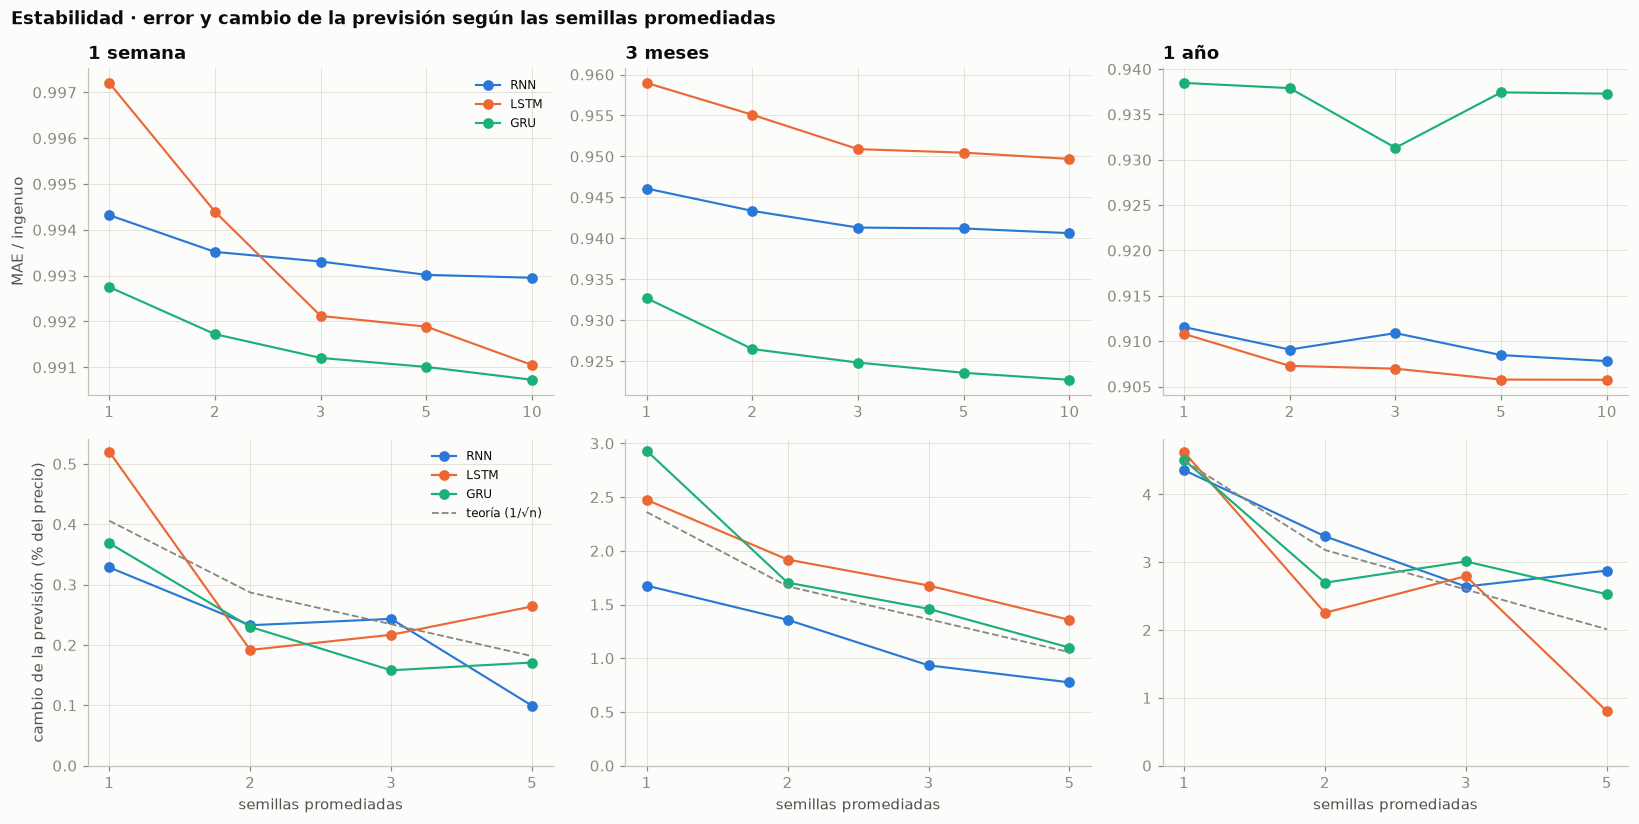

In [49]:
TAMAÑOS = [1, 2, 3, 5, 10]
x = np.arange(len(TAMAÑOS))
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6))
for col, h in enumerate(config.HORIZONTES):
    arriba, abajo = axes[0, col], axes[1, col]
    for red in config.CELDAS:
        c = curva.loc[(h, red)].reindex(TAMAÑOS)
        arriba.plot(x, c["MAE / ingenuo"], marker="o", color=COLOR_RED[red], label=red)
        abajo.plot(x[:-1], c["cambio de la previsión (% del precio)"].iloc[:-1], marker="o",
                   color=COLOR_RED[red], label=red)
    # Si el azar de cada semilla fuera independiente, el cambio bajaría como 1/√n
    una = curva.xs(1, level="semillas promediadas").loc[h, "cambio de la previsión (% del precio)"].mean()
    abajo.plot(x[:-1], una / np.sqrt(TAMAÑOS[:-1]), color=TINTA_SUAVE, linestyle="--", linewidth=1.2,
               label="teoría (1/√n)")
    arriba.set_title(HORIZONTE[h])
    arriba.set_xticks(x, TAMAÑOS)
    abajo.set_xticks(x[:-1], TAMAÑOS[:-1])
    abajo.set_ylim(bottom=0)
    abajo.set_xlabel("semillas promediadas")
axes[0, 0].set_ylabel("MAE / ingenuo")
axes[1, 0].set_ylabel("cambio de la previsión (% del precio)")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.suptitle("Estabilidad · error y cambio de la previsión según las semillas promediadas",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 7.2 ¿Hubo suerte en la fase B?

Las semillas 42, 43 y 44 son las que usó la fase B para elegir cada configuración; las 45-51 no se usaron para nada. Si la elegida ganó en parte por suerte, con las semillas nuevas dará peor.

In [50]:
por_semilla = es.nota(e_prev, por=("semilla",)).unstack("semilla")
suerte_e = pd.DataFrame({"fase B (42-44)": por_semilla[SEMILLAS_B].mean(axis=1),
                         "nuevas (45-51)": por_semilla[NUEVAS].mean(axis=1)})
suerte_e["diferencia"] = suerte_e["nuevas (45-51)"] - suerte_e["fase B (42-44)"]
suerte_e["mejor semilla"] = por_semilla.min(axis=1)
suerte_e["peor semilla"] = por_semilla.max(axis=1)
en_orden(suerte_e).round(3)

fase B (42-44)  nuevas (45-51)  diferencia  mejor semilla  peor semilla
horizonte red                                                                          
1 semana  RNN            0.994           0.995       0.001          0.989         0.999
          LSTM           0.991           1.000       0.009          0.987         1.054
          GRU            0.994           0.992      -0.001          0.985         0.999
3 meses   RNN            0.943           0.947       0.004          0.928         0.957
          LSTM           0.943           0.966       0.023          0.933         0.989
          GRU            0.922           0.937       0.015          0.912         0.959
1 año     RNN            0.893           0.920       0.026          0.891         0.992
          LSTM           0.882           0.923       0.041          0.867         0.990
          GRU            0.893           0.958       0.065          0.884         0.995

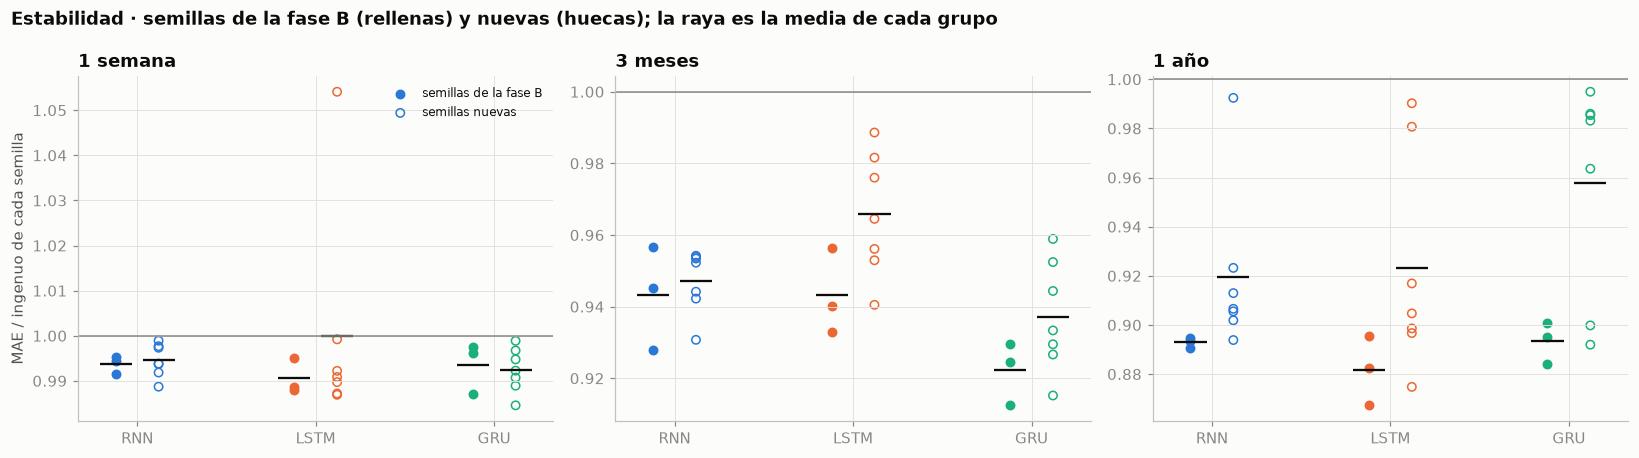

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, h in zip(axes, config.HORIZONTES):
    for xi, red in enumerate(config.CELDAS):
        fila = por_semilla.loc[(h, red)]
        ax.scatter(np.full(len(SEMILLAS_B), xi - 0.12), fila[SEMILLAS_B], s=30, color=COLOR_RED[red],
                   label="semillas de la fase B" if xi == 0 else None)
        ax.scatter(np.full(len(NUEVAS), xi + 0.12), fila[NUEVAS], s=30, facecolors="none",
                   edgecolors=COLOR_RED[red], label="semillas nuevas" if xi == 0 else None)
        for dx, grupo in ((-0.12, SEMILLAS_B), (0.12, NUEVAS)):
            ax.hlines(fila[grupo].mean(), xi + dx - 0.09, xi + dx + 0.09, color=TINTA, linewidth=1.5)
    ax.axhline(1, color=TINTA_SUAVE, linewidth=1)
    ax.set_xticks(range(len(config.CELDAS)), config.CELDAS)
    ax.set_title(HORIZONTE[h])
axes[0].set_ylabel("MAE / ingenuo de cada semilla")
axes[0].legend(fontsize=8)
fig.suptitle("Estabilidad · semillas de la fase B (rellenas) y nuevas (huecas); la raya es la media de cada grupo",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 7.3 1 año por dentro

A 1 año el azar entre semillas es el mayor. Primero, la época con que se queda cada entrenamiento (su «mejor época»: la que guarda la parada temprana), en todos los horizontes:

In [52]:
mejor_ep = e_entrenos.groupby(["horizonte", "modelo", "pliegue"])["mejor época"]
épocas_e = pd.concat({"mediana de la mejor época": mejor_ep.median().unstack(),
                      "% que se queda con la 1.ª": mejor_ep.apply(lambda s: (s == 1).mean() * 100).unstack()},
                     axis=1)
en_orden(épocas_e).apply(lambda col: col.map(lambda v: "—" if pd.isna(v) else f"{v:.0f}"))

mediana de la mejor época                % que se queda con la 1.ª               
pliegue                             2018 2019 2020 2021                      2018 2019 2020 2021
horizonte red                                                                                   
1 semana  RNN                          8   36   23   52                         0    0    0    0
          LSTM                         5   23   20   25                         0    0   20    0
          GRU                         14   42   26   38                         0    0    0    0
3 meses   RNN                          8    8    8    3                         0    0    0    0
          LSTM                         7    6    3    4                         0    0    0    0
          GRU                          7    2    2    8                         0    0    0    0
1 año     RNN                          1    1    8    —                       100   80    0    —
          LSTM                         1    1    8    —                       100  100   20    —
          GRU                          1    1   12    —                       100   90   40    —

Cada semilla a 1 año: su nota en cada año de validación y su mejor época en cada uno.

In [53]:
largo_e = e_prev[e_prev["horizonte"] == "largo"]
semillas_l = es.nota(largo_e, por=("semilla", "pliegue")).unstack("pliegue")
semillas_l.columns = [str(a) for a in semillas_l.columns]
semillas_l["años juntos"] = es.nota(largo_e, por=("semilla",))
semillas_l["mejor época (2018 · 2019 · 2020)"] = (
    e_entrenos[e_entrenos["horizonte"] == "largo"].sort_values("pliegue")
    .groupby(["horizonte", "modelo", "semilla"])["mejor época"].apply(lambda s: " · ".join(map(str, s))))
en_orden(semillas_l).droplevel("horizonte").round(3)

2018  2019  2020  años juntos mejor época (2018 · 2019 · 2020)
red  semilla                                                                
RNN  42      0.958 1.087 0.725        0.893                        1 · 1 · 8
     43      0.972 1.080 0.721        0.891                        1 · 1 · 7
     44      0.986 1.104 0.707        0.895                        1 · 1 · 8
     45      1.017 1.123 0.698        0.902                        1 · 1 · 7
     46      0.978 1.102 0.735        0.907                        1 · 1 · 6
     47      0.917 1.403 0.699        0.992                       1 · 16 · 9
     48      1.161 1.146 0.661        0.913                        1 · 2 · 9
     49      1.046 1.113 0.704        0.906                       1 · 1 · 15
     50      1.085 1.150 0.701        0.923                       1 · 1 · 13
     51      0.915 1.148 0.693        0.894                       1 · 1 · 10
LSTM 42      1.055 1.112 0.656        0.883                        1 · 1 · 8
     43      1.100 1.147 0.642        0.896                        1 · 1 · 6
     44      1.078 1.129 0.604        0.867                        1 · 1 · 8
     45      1.100 1.149 0.660        0.905                        1 · 1 · 9
     46      1.081 1.194 0.788        0.981                        1 · 1 · 1
     47      1.073 1.123 0.626        0.875                        1 · 1 · 8
     48      1.122 1.152 0.638        0.899                       1 · 1 · 10
     49      1.109 1.143 0.838        0.990                        1 · 1 · 1
     50      1.122 1.144 0.640        0.897                        1 · 1 · 7
     51      1.123 1.175 0.657        0.917                        1 · 1 · 7
GRU  42      1.000 1.079 0.723        0.895                       1 · 1 · 21
     43      0.950 1.050 0.737        0.884                       1 · 1 · 12
     44      0.978 1.104 0.721        0.901                       1 · 1 · 17
     45      1.056 1.147 0.840        0.985                        1 · 1 · 1
     46      0.989 1.083 0.717        0.892                       1 · 1 · 12
     47      1.073 1.142 0.834        0.983                        1 · 1 · 1
     48      0.914 1.342 0.733        0.986                      1 · 24 · 11
     49      1.041 1.131 0.812        0.964                        1 · 1 · 1
     50      1.001 1.083 0.729        0.900                       1 · 1 · 17
     51      1.090 1.127 0.865        0.995                        1 · 1 · 1

Año a año, con el promedio de las 10 semillas y el lineal (el de la sección 6):

In [54]:
prom10 = es.promedio(e_prev, config.SEMILLAS_ESTABILIDAD)
años_e = es.nota(prom10, por=("pliegue",)).unstack("pliegue")
años_e.columns = [str(a) for a in años_e.columns]
años_e["años juntos"] = es.nota(prom10)
lineal_años = pd.DataFrame({(h, "Lineal"): años_b(lineal_b[h], extra=()) for h in config.HORIZONTES}).T
lineal_años.index.names = ["horizonte", "modelo"]
# A 1 año, 2021 no se evalúa: solo tiene 1 respuesta antes del test
en_orden(pd.concat([años_e, lineal_años])).round(3).astype(object).fillna("—")

2018  2019  2020  2021 años juntos
horizonte red                                       
1 semana  RNN    0.992 0.996 0.984 1.003       0.993
          LSTM   0.994 0.993 0.989 0.988       0.991
          GRU    0.987 1.000 0.982 0.997       0.991
          Lineal 1.005 0.997 0.986 0.984       0.993
3 meses   RNN    0.927 0.908 0.957 0.968       0.941
          LSTM   0.951 1.011 0.935 0.889       0.950
          GRU    1.000 0.920 0.914 0.817       0.923
          Lineal 1.016 0.887 0.940 1.139       0.972
1 año     RNN    0.991 1.144 0.702     —       0.908
          LSTM   1.096 1.146 0.665     —       0.906
          GRU    1.007 1.127 0.771     —       0.937
          Lineal 0.750 1.038 0.672     —       0.820

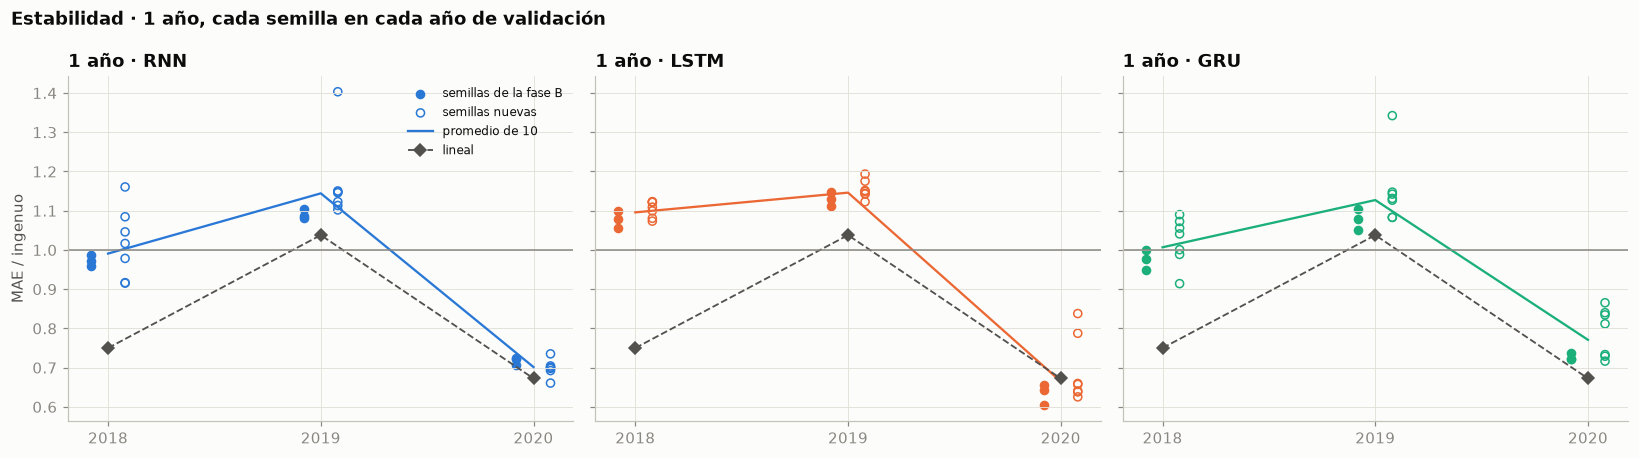

In [55]:
AÑOS_L = ["2018", "2019", "2020"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, red in zip(axes, config.CELDAS):
    for xi, año in enumerate(AÑOS_L):
        fila = semillas_l.loc[("largo", red), año]
        nuevas = fila.index.isin(NUEVAS)
        ax.scatter(np.full((~nuevas).sum(), xi - 0.08), fila[~nuevas], s=28, color=COLOR_RED[red],
                   label="semillas de la fase B" if xi == 0 else None)
        ax.scatter(np.full(nuevas.sum(), xi + 0.08), fila[nuevas], s=28, facecolors="none",
                   edgecolors=COLOR_RED[red], label="semillas nuevas" if xi == 0 else None)
    ax.plot(range(len(AÑOS_L)), años_e.loc[("largo", red), AÑOS_L], color=COLOR_RED[red], linewidth=1.5,
            label="promedio de 10")
    ax.plot(range(len(AÑOS_L)), lineal_años.loc[("largo", "Lineal"), AÑOS_L], color=TINTA_2, marker="D",
            linestyle="--", linewidth=1.2, label="lineal")
    ax.axhline(1, color=TINTA_SUAVE, linewidth=1)
    ax.set_xticks(range(len(AÑOS_L)), AÑOS_L)
    ax.set_title(f"1 año · {red}")
axes[0].set_ylabel("MAE / ingenuo")
axes[0].legend(fontsize=8)
fig.suptitle("Estabilidad · 1 año, cada semilla en cada año de validación", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 7.4 Resultado: lo que se adopta

Regla de D27: el promedio de 5 semillas. Hay dos grupos de 5: el 42-46, que incluye las 3 semillas de la fase B, y el 47-51, que no se usó para elegir nada. La nota adoptada es la media de los dos, y la de la fase B se pone al lado para ver cuánto cambia.

In [56]:
c5 = curva.xs(5, level="semillas promediadas")
c1 = curva.xs(1, level="semillas promediadas")
filas = []
for h in config.HORIZONTES:
    for red in config.CELDAS:
        q = e_prev[(e_prev["horizonte"] == h) & (e_prev["modelo"] == red)]
        g1, g2 = es.grupos(config.SEMILLAS_ESTABILIDAD, config.N_SEMILLAS_PROMEDIO)
        filas.append({"horizonte": h, "modelo": red,
                      "fase B (42-44)": resultado_b.loc[(HORIZONTE[h], red), "elegida"],
                      "una semilla (media de 10)": c1.loc[(h, red), "MAE / ingenuo"],
                      "promedio 42-46": es.nota(es.promedio(q, g1)).iloc[0],
                      "promedio 47-51": es.nota(es.promedio(q, g2)).iloc[0],
                      "promedio de 5 (adoptado)": c5.loc[(h, red), "MAE / ingenuo"],
                      "lineal": nota_lineal_b[h]})
resultado_e = pd.DataFrame(filas).set_index(["horizonte", "modelo"])
en_orden(resultado_e).round(3)

fase B (42-44)  una semilla (media de 10)  promedio 42-46  promedio 47-51  promedio de 5 (adoptado)  lineal
horizonte red                                                                                                              
1 semana  RNN            0.994                      0.994           0.993           0.993                     0.993   0.993
          LSTM           0.991                      0.997           0.987           0.997                     0.992   0.993
          GRU            0.994                      0.993           0.989           0.993                     0.991   0.993
3 meses   RNN            0.943                      0.946           0.938           0.945                     0.941   0.972
          LSTM           0.943                      0.959           0.944           0.957                     0.950   0.972
          GRU            0.922                      0.933           0.918           0.929                     0.924   0.972
1 año     RNN            0.893                      0.912           0.894           0.923                     0.908   0.820
          LSTM           0.882                      0.911           0.900           0.912                     0.906   0.820
          GRU            0.893                      0.938           0.911           0.964                     0.937   0.820

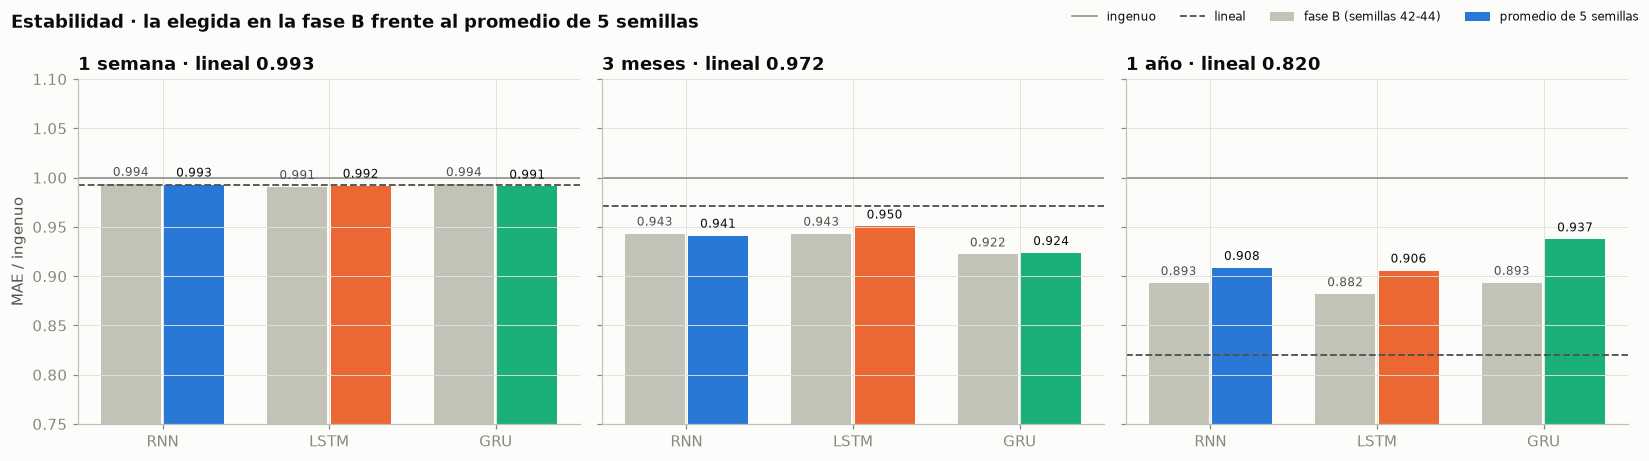

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
x = np.arange(len(config.CELDAS))
for ax, h in zip(axes, config.HORIZONTES):
    r = resultado_e.loc[h].reindex(config.CELDAS)
    ax.bar(x - 0.19, r["fase B (42-44)"], width=0.36, color=EJE, label="fase B (semillas 42-44)")
    ax.bar(x + 0.19, r["promedio de 5 (adoptado)"], width=0.36, color=[COLOR_RED[red] for red in config.CELDAS],
           label="promedio de 5 semillas")
    for xi, (b, e) in enumerate(zip(r["fase B (42-44)"], r["promedio de 5 (adoptado)"])):
        ax.text(xi - 0.19, b + 0.005, f"{b:.3f}", ha="center", va="bottom", fontsize=8, color=TINTA_2)
        ax.text(xi + 0.19, e + 0.005, f"{e:.3f}", ha="center", va="bottom", fontsize=8, color=TINTA)
    ax.axhline(1, color=TINTA_SUAVE, linewidth=1, label="ingenuo")
    ax.axhline(nota_lineal_b[h], color=TINTA_2, linestyle="--", linewidth=1.2, label="lineal")
    ax.set_xticks(x, config.CELDAS)
    ax.set_ylim(0.75, 1.1)
    ax.set_title(f"{HORIZONTE[h]} · lineal {nota_lineal_b[h]:.3f}")
axes[0].set_ylabel("MAE / ingenuo")
fig.suptitle("Estabilidad · la elegida en la fase B frente al promedio de 5 semillas", x=0.01, ha="left",
             fontweight="bold")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

### 7.5 Lectura

> 330 entrenamientos (las 9 elegidas × 10 semillas × 3 o 4 años) y 81.900 previsiones, en 5,1 h de cálculo. Las semillas 42-44 reproducen la fase B (diferencia máxima de MAE: 5·10⁻⁷ $).

**Lo esperado (apuntado antes de lanzar) frente a lo obtenido**

| | Esperado | Obtenido |
|---|---|---|
| Error | mejora de 0,00 a 0,02, mayor a 1 año | de 0,001 a 0,009; mayor a 3 meses (GRU 0,933 → 0,924, LSTM 0,959 → 0,950) que a 1 año (0,001-0,005) |
| Estabilidad | el azar baja a menos de la mitad (en teoría, a 0,45) | a 3 meses se cumple: el cambio de la previsión baja a 0,37-0,55 de lo que cambia con una semilla, y el azar de la nota, a la mitad. A 1 año, entre 0,17 y 0,66: muy desigual, y medido con una sola pareja de grupos |
| Lo que no cambia | la distancia con el lineal a 1 año y el empate entre redes | se cumple, y la distancia con el lineal crece |
| Semillas nuevas a 1 año | pueden dar algo peor que las de la elección | se cumple, y más de lo esperado: de 0,03 a 0,07 peor |

**La fase B era optimista, sobre todo a 1 año.** Con las semillas que no se usaron para elegir, las redes dan 0,03-0,07 peor a 1 año (RNN 0,920, LSTM 0,923 y GRU 0,958, frente a 0,88-0,89) y 0,00-0,02 peor a 3 meses. A 1 semana no cambia. Es el riesgo de elegir entre muchas configuraciones con pocos años de validación: la elegida ganó, en parte, por suerte.

**A 1 año, las redes no aprenden.**
- En 2018 y 2019, casi todos los entrenamientos se quedan con la 1.ª época (el 100 % en 2018 y el 80-100 % en 2019): todo lo que aprenden después empeora en el trozo que decide la parada. La red apenas se mueve de su punto de partida. Solo en 2020 aprende algo (mejor época mediana, la 8.ª-12.ª).
- Por eso cada semilla depende de dónde para cada año. Las peores (0,96-0,99) son las que en 2020 también se quedan con la 1.ª época (GRU 45, 47, 49 y 51; LSTM 46 y 49) o las que en 2019 siguen aprendiendo y se equivocan (RNN 47 y GRU 48, con 1,34-1,40 ese año).
- Las redes solo ganan al ingenuo en 2020 (0,67-0,77), el año del rebote tras el COVID. En 2018 no lo mejoran (0,99-1,10) y en 2019 pierden (1,13-1,15). El lineal les gana en 2018 (0,75) y en 2019 (1,04), y en 2020 queda a su altura (0,67).
- Promediar semillas no lo arregla: promedia redes que apenas han aprendido.

**A 3 meses, las redes siguen ganando al lineal**, y es el único horizonte donde aportan: 0,924 (GRU), 0,941 (RNN) y 0,950 (LSTM), frente a 0,972. Lo hacen de forma más regular: el lineal gana en 2019 (0,89) pero falla mucho en 2021 (1,14). La GRU queda primera, pero con 4 años de validación no basta para decir que sea mejor.

**A 1 semana, nada cambia:** todo en 0,99. El promedio solo quita alguna semilla rara (una LSTM con 1,054).

**Se adopta el promedio de 5 semillas en los tres horizontes** (regla de D27). Desde ahora, las notas de referencia de la validación son las de la tabla 7.4 y no las de la fase B.

**Balance.** Promediar hace la previsión más estable: con otras 5 semillas, el precio previsto a 3 meses se mueve un 0,8-1,4 %, frente al 1,7-2,9 % con una sola. Pero apenas mejora el error. El problema de fondo está a 1 año, donde las redes no aprenden y el lineal es mejor. El siguiente paso es combinar red y lineal (D28).

## 8. Combinación de red y lineal (D28)

**Pregunta:** a 1 año el lineal es mejor que las redes, y a 3 meses al revés. ¿Mejora algo mezclar las dos previsiones?

**Cómo se mide** (sin entrenar nada, solo en validación):
- La previsión combinada es la media, a partes iguales, del precio que prevé la red (promedio de 5 semillas, sección 7) y del que prevé el lineal.
- El lineal es el de referencia de la sección 6: sin tendencia, con los mismos datos que las redes y su mejor fuerza de regularización. Sus previsiones se recalculan con las mismas fichas que las redes (tarda segundos) y deben dar su nota de siempre.
- Como en la sección 7.4, la nota de cada red es la media de sus dos grupos de 5 semillas (42-46 y 47-51).
- **Regla, fijada antes de calcular:** en cada horizonte, con la media de las tres redes, la combinación se adopta si mejora a la mejor de las dos opciones por separado (red sola o lineal) en más del azar que queda con 5 semillas (tabla 7.1). Si empata, se queda la opción sola, por sencilla.
- La curva con otros pesos (de 0, el lineal solo, a 1, la red sola) es solo descriptiva: no se usa para elegir el peso.

Lo hace `src/oil_price/combinacion.py`.

In [58]:
from oil_price import combinacion as co

lin_c = co.previsiones_lineal()
comprobacion = pd.DataFrame({
    HORIZONTE[h]: {"regularización (alfa)": f"{co.alfa_lineal(h)[0]:g}",
                   "nota guardada": round(co.alfa_lineal(h)[1], 4),
                   "nota recalculada": round(es.nota(lin_c[lin_c["horizonte"] == h]).iloc[0], 4)}
    for h in config.HORIZONTES}).T
print(f"Lineal recalculado en {len(lin_c)} fichas, las mismas que las redes")
comprobacion

Lineal recalculado en 2730 fichas, las mismas que las redes


,regularización (alfa),nota guardada,nota recalculada
1 semana,100000,0.993,0.993
3 meses,1000,0.972,0.972
1 año,1,0.820,0.820


### 8.1 La regla aplicada

Media de las tres redes en cada horizonte: la red sola, el lineal solo y la mitad de cada uno. «Mejora» es lo que gana la combinación frente a la mejor de las dos por separado; para adoptarse tiene que superar el azar que queda con 5 semillas.

In [59]:
pesos_c = co.curva_pesos(e_prev, lin_c)
ruido_c = curva.xs(5, level="semillas promediadas")["azar entre grupos"].groupby(level="horizonte").mean()
regla_c = co.decidir(pesos_c, ruido_c.to_dict())
regla_c.reindex(list(config.HORIZONTES)).rename(index=HORIZONTE).round(3)

,red sola,lineal,combinación,ruido,mejor por separado,mejora,se adopta,se queda
1 semana,0.992,0.993,0.990,0.003,0.992,0.002,False,red sola
3 meses,0.938,0.972,0.945,0.008,0.938,-0.007,False,red sola
1 año,0.917,0.820,0.851,0.022,0.820,-0.032,False,lineal


### 8.2 Con otros pesos (solo descriptivo)

Cada red con el peso que se le da en la mezcla: 0 es el lineal solo; 1, la red sola; la línea punteada, la mitad (la regla).

In [60]:
en_orden(pesos_c).round(3)

peso de la red  0.000  0.250  0.500  0.750  1.000
horizonte red                                    
1 semana  RNN   0.993  0.991  0.989  0.990  0.993
          LSTM  0.993  0.991  0.989  0.990  0.992
          GRU   0.993  0.991  0.990  0.990  0.991
3 meses   RNN   0.972  0.961  0.952  0.946  0.941
          LSTM  0.972  0.958  0.950  0.948  0.950
          GRU   0.972  0.949  0.934  0.926  0.924
1 año     RNN   0.820  0.828  0.847  0.875  0.908
          LSTM  0.820  0.829  0.846  0.872  0.906
          GRU   0.820  0.833  0.861  0.896  0.937

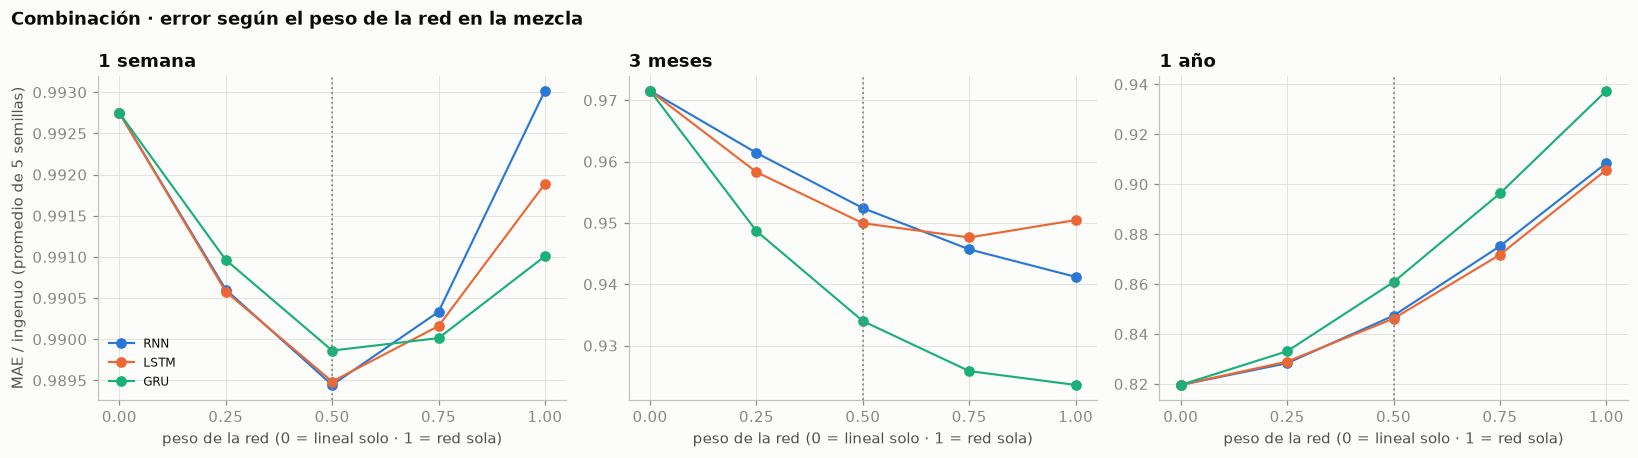

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, h in zip(axes, config.HORIZONTES):
    for red in config.CELDAS:
        fila = pesos_c.loc[(h, red)]
        ax.plot(fila.index, fila.values, marker="o", color=COLOR_RED[red], label=red)
    ax.axvline(config.PESO_RED_COMBINACION, color=TINTA_SUAVE, linestyle=":", linewidth=1.2)
    ax.set_xticks(config.PESOS_CURVA_COMBINACION)
    ax.set_title(HORIZONTE[h])
    ax.set_xlabel("peso de la red (0 = lineal solo · 1 = red sola)")
axes[0].set_ylabel("MAE / ingenuo (promedio de 5 semillas)")
axes[0].legend(fontsize=8)
fig.suptitle("Combinación · error según el peso de la red en la mezcla", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 8.3 Año a año

Media de las tres redes en cada año de validación: la red sola, la mitad de cada uno y el lineal solo.

In [62]:
OPCIONES_C = {1.0: "red sola", config.PESO_RED_COMBINACION: "mitad y mitad", 0.0: "lineal"}
COLUMNA_REGLA = {1.0: "red sola", config.PESO_RED_COMBINACION: "combinación", 0.0: "lineal"}
por_año_c = co.curva_pesos(e_prev, lin_c, pesos=list(OPCIONES_C), por=("pliegue",))
filas = []
for h in config.HORIZONTES:
    for peso, nombre in OPCIONES_C.items():
        años = por_año_c[peso].xs(h, level="horizonte").groupby(level="pliegue").mean()
        filas.append(pd.Series({**{str(a): v for a, v in años.items()},
                                "años juntos": regla_c.loc[h, COLUMNA_REGLA[peso]]}, name=(HORIZONTE[h], nombre)))
años_c = pd.DataFrame(filas)
años_c.index = pd.MultiIndex.from_tuples(años_c.index, names=["horizonte", "opción"])
# A 1 año, 2021 no se evalúa: solo tiene 1 respuesta antes del test
años_c.round(3).astype(object).fillna("—")

2018  2019  2020  2021 años juntos
horizonte opción                                           
1 semana  red sola      0.991 0.997 0.986 0.997       0.992
          mitad y mitad 0.996 0.992 0.984 0.987       0.990
          lineal        1.005 0.997 0.986 0.984       0.993
3 meses   red sola      0.960 0.948 0.936 0.893       0.938
          mitad y mitad 0.966 0.905 0.937 1.006       0.945
          lineal        1.016 0.887 0.940 1.139       0.972
1 año     red sola      1.032 1.140 0.713     —       0.917
          mitad y mitad 0.822 1.088 0.678     —       0.851
          lineal        0.750 1.038 0.672     —       0.820

### 8.4 Por qué mezclar apenas ayuda

Mezclar dos previsiones solo ayuda si se equivocan de forma distinta. Para cada red (promedio de las 10 semillas): cuánto se parece su previsión a la del lineal (correlación) y cuánto se mueve respecto a ella (1 = lo mismo; 0,5 = la mitad).

In [63]:
prom10_c = es.promedio(e_prev, config.SEMILLAS_ESTABILIDAD)
lin_fechas = lin_c.assign(fecha=lin_c["fecha"].astype(prom10_c["fecha"].dtype))
pares_c = prom10_c.merge(lin_fechas[co.CLAVE_FICHA + ["variación prevista"]], on=co.CLAVE_FICHA,
                         suffixes=("", " lineal"))
parecido = pares_c.groupby(["horizonte", "modelo"]).apply(lambda d: pd.Series({
    "correlación con el lineal": d["variación prevista"].corr(d["variación prevista lineal"]),
    "tamaño frente al lineal": d["variación prevista"].std() / d["variación prevista lineal"].std()}),
    include_groups=False)
en_orden(parecido).round(2)

correlación con el lineal  tamaño frente al lineal
horizonte red                                                     
1 semana  RNN                       0.240                    1.640
          LSTM                      0.230                    1.540
          GRU                       0.250                    1.330
3 meses   RNN                       0.830                    0.900
          LSTM                      0.800                    0.980
          GRU                       0.760                    1.010
1 año     RNN                       0.940                    0.610
          LSTM                      0.940                    0.720
          GRU                       0.950                    0.480

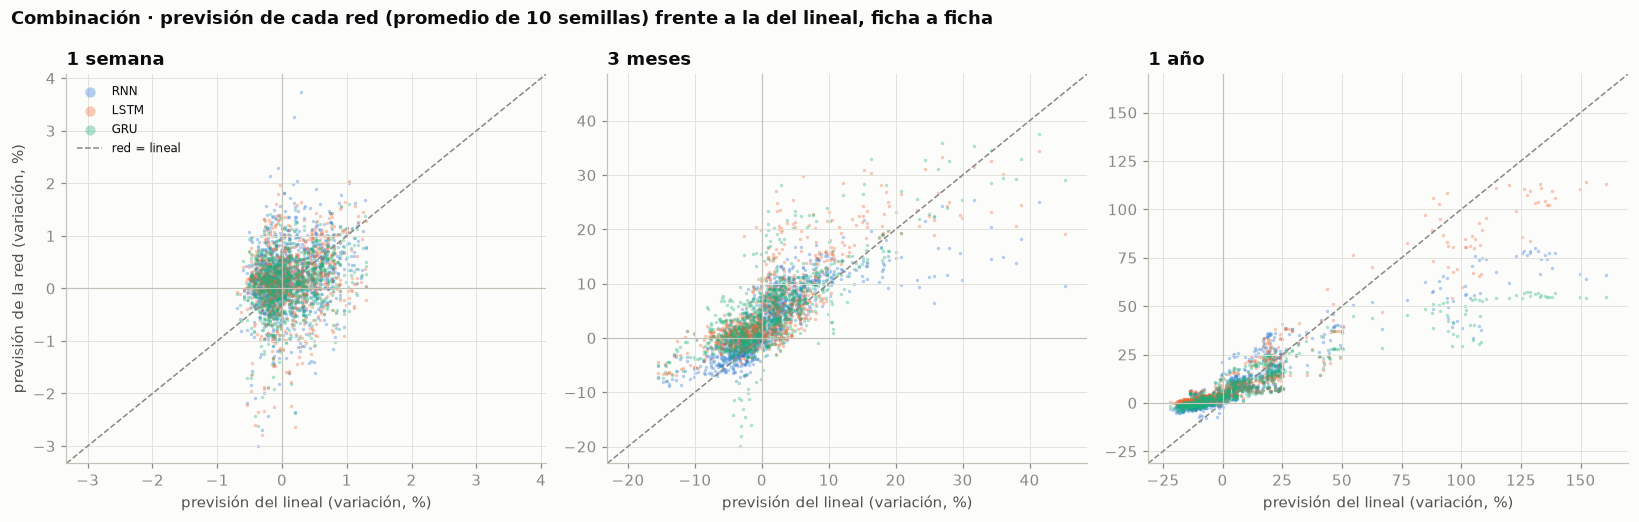

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, h in zip(axes, config.HORIZONTES):
    d = pares_c[pares_c["horizonte"] == h]
    for red in config.CELDAS:
        r = d[d["modelo"] == red]
        ax.scatter(100 * np.expm1(r["variación prevista lineal"]), 100 * np.expm1(r["variación prevista"]),
                   s=5, alpha=0.35, color=COLOR_RED[red], linewidths=0, label=red)
    # Mismos límites en los dos ejes, para que la diagonal «red = lineal» quede a 45°
    valores = 100 * np.expm1(d[["variación prevista", "variación prevista lineal"]])
    bajo, alto = valores.min().min(), valores.max().max()
    margen = 0.05 * (alto - bajo)
    lim = (bajo - margen, alto + margen)
    ax.plot(lim, lim, color=TINTA_SUAVE, linestyle="--", linewidth=1, label="red = lineal")
    ax.axhline(0, color=EJE, linewidth=0.8)
    ax.axvline(0, color=EJE, linewidth=0.8)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_title(HORIZONTE[h])
    ax.set_xlabel("previsión del lineal (variación, %)")
axes[0].set_ylabel("previsión de la red (variación, %)")
axes[0].legend(fontsize=8, markerscale=3)
fig.suptitle("Combinación · previsión de cada red (promedio de 10 semillas) frente a la del lineal, ficha a ficha",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 8.5 Lectura

> El lineal recalculado da exactamente su nota de siempre en las 2.730 fichas de validación, las mismas que las redes. Cálculo de segundos, sin entrenar.

**La combinación no se adopta en ningún horizonte.** A 1 semana y a 3 meses se queda la red sola; a 1 año, el lineal sigue siendo lo mejor.
- **1 semana:** la mezcla da 0,990, frente a 0,992 de la red sola. Mejora 0,002, menos que el azar (0,003): es un empate, y en empate se queda lo sencillo.
- **3 meses:** la mezcla (0,945) es algo **peor** que la red sola (0,938).
- **1 año:** la mezcla (0,851) queda entre la red sola (0,917) y el lineal (0,820), y no le gana.

**Lo esperado (apuntado antes de calcular) frente a lo obtenido**

| | Esperado | Obtenido |
|---|---|---|
| 1 año | entre las dos, más cerca del lineal (0,83-0,86); no se adopta | 0,846-0,861; no se adopta |
| 3 meses | algo mejor que la red sola (0,92-0,94), quizá dentro del azar | algo peor que la red sola (0,934-0,952 frente a 0,924-0,950) |
| 1 semana | nada (0,99); no se adopta | 0,989-0,990; empate |

**A 1 año, las redes son una copia en pequeño del lineal.** Su previsión va en la misma dirección que la del lineal casi siempre (correlación 0,94-0,95), pero se mueve la mitad o dos tercios (0,48-0,72). En el gráfico, los puntos de 1 año forman una recta más tumbada que la diagonal. Por eso, cuanto más peso tiene el lineal en la mezcla, mejor, sin excepción, con las tres redes (de 0,91-0,94 con la red sola a 0,82 con el lineal solo). Mezclarlas solo acorta la previsión del lineal, y año a año la mezcla queda siempre detrás de él (0,82 frente a 0,75 en 2018, 1,09 frente a 1,04 en 2019 y 0,68 frente a 0,67 en 2020). Las redes no encuentran nada que el lineal no vea.

**A 3 meses, red y lineal se parecen demasiado para que mezclarlos ayude.** Sus previsiones se correlacionan 0,76-0,83 y tienen el mismo tamaño. La mezcla gana en 2019, el buen año del lineal (de 0,95 a 0,91), pero pierde más en 2021, su mal año (de 0,89 a 1,01, con el lineal en 1,14). La RNN y la GRU van mejor solas; la LSTM, con tres cuartos de red, empata.

**A 1 semana, al revés:** red y lineal casi no se parecen (correlación 0,23-0,25), y la mezcla a partes iguales es el mejor punto de la curva para las tres redes. Pero la ganancia es de 0,001-0,004 frente a la red sola, del tamaño del azar: dos previsiones que son casi ruido se compensan un poco, nada más.

**Qué implica**
- A 1 año, la idea de una red que parte del lineal y aprende lo que le falta tiene poco recorrido: con estos datos, las redes no encuentran nada que el lineal no vea. No se hace por ahora.
- La conclusión de 1 año se refuerza: con los datos actuales, ninguna red supera a un modelo lineal sencillo.
- A 3 meses, las redes recogen lo que ve el lineal y algo más, y van mejor solas.

## 9. Qué ve cada modelo

**Pregunta:** ¿qué variables y qué situaciones mueven la previsión de cada modelo? Sirve para tres cosas: elegir qué información nueva merece la pena probar, entender por qué las redes no superan al lineal a 1 año, y explicar las previsiones en la aplicación («qué factores pueden invalidarla»).

**Las entradas** (las mismas para todos los modelos): las variaciones diarias del Brent, el WTI, el cobre, el oro, el índice del dólar y el VIX, y la **volatilidad del Brent** en el último mes (21 sesiones), en los últimos 20 días (a 1 semana, 252).

**Cómo se mide** (solo validación; no elige nada):
- **Lineal:** su previsión es una suma de aportaciones, una por variable y día, así que se reparte exactamente entre las variables. Además, se reajusta sin cada variable y con solo ella.
- **Redes** (promedio de 5 semillas, 42-46, como en D27): se desordena cada variable entre fichas y se mide cuánto empeora la nota; si la red no usa esa variable, no cambia nada. Hay que reentrenarlas, así que lo hace `scripts/importancia.py` (unos 10 minutos), que guarda `resultados/importancia.csv` y `resultados/efectos.csv`. A 1 semana no se hace: es lento y allí ningún modelo aporta.
- **Situaciones típicas:** cuánto cambia de media la previsión si la volatilidad fuese el doble o la mitad, o si el Brent y el WTI estuvieran un 10 % más abajo que hace un mes.

### 9.1 Lo que mueve la previsión del lineal

Qué parte de lo que se mueve la previsión del lineal viene de cada variable (desviación típica de su aportación, en % de la suma de todas) y cuánto se parece esa aportación a la previsión entera (correlación), en las fichas de validación:

In [65]:
from oil_price import explicacion as xp

bases_x = ex._bases()
aport_x = {h: xp.aportaciones_lineal(h, bases_x) for h in config.HORIZONTES}
peso_x = pd.concat({HORIZONTE[h]: xp.peso_variables(a) for h, a in aport_x.items()}, axis=1)
peso_x.sort_values(("1 año", "% de lo que mueve la previsión"), ascending=False).round(2)

1 semana                                                     3 meses                               \
                  % de lo que mueve la previsión correlación con la previsión % de lo que mueve la previsión correlación con la previsión   
volatilidad Brent                         47.640                        0.880                         36.330                        0.860   
Brent                                     12.060                        0.390                         14.540                        0.110   
cobre                                      5.970                        0.430                         17.090                        0.380   
dólar                                      6.720                        0.270                          8.080                        0.370   
oro                                        7.250                        0.130                          6.090                        0.180   
WTI                                       12.600                        0.420                          7.980                        0.160   
VIX                                        7.770                        0.220                          9.890                        0.340   

                                           1 año                               
                  % de lo que mueve la previsión correlación con la previsión  
volatilidad Brent                         67.020                        0.990  
Brent                                     13.050                       -0.210  
cobre                                      6.270                        0.190  
dólar                                      6.250                        0.170  
oro                                        2.560                       -0.110  
WTI                                        2.460                        0.080  
VIX                                        2.390                        0.160

La previsión del lineal y la parte que pone la volatilidad, día a día, junto a lo que pasó de verdad:

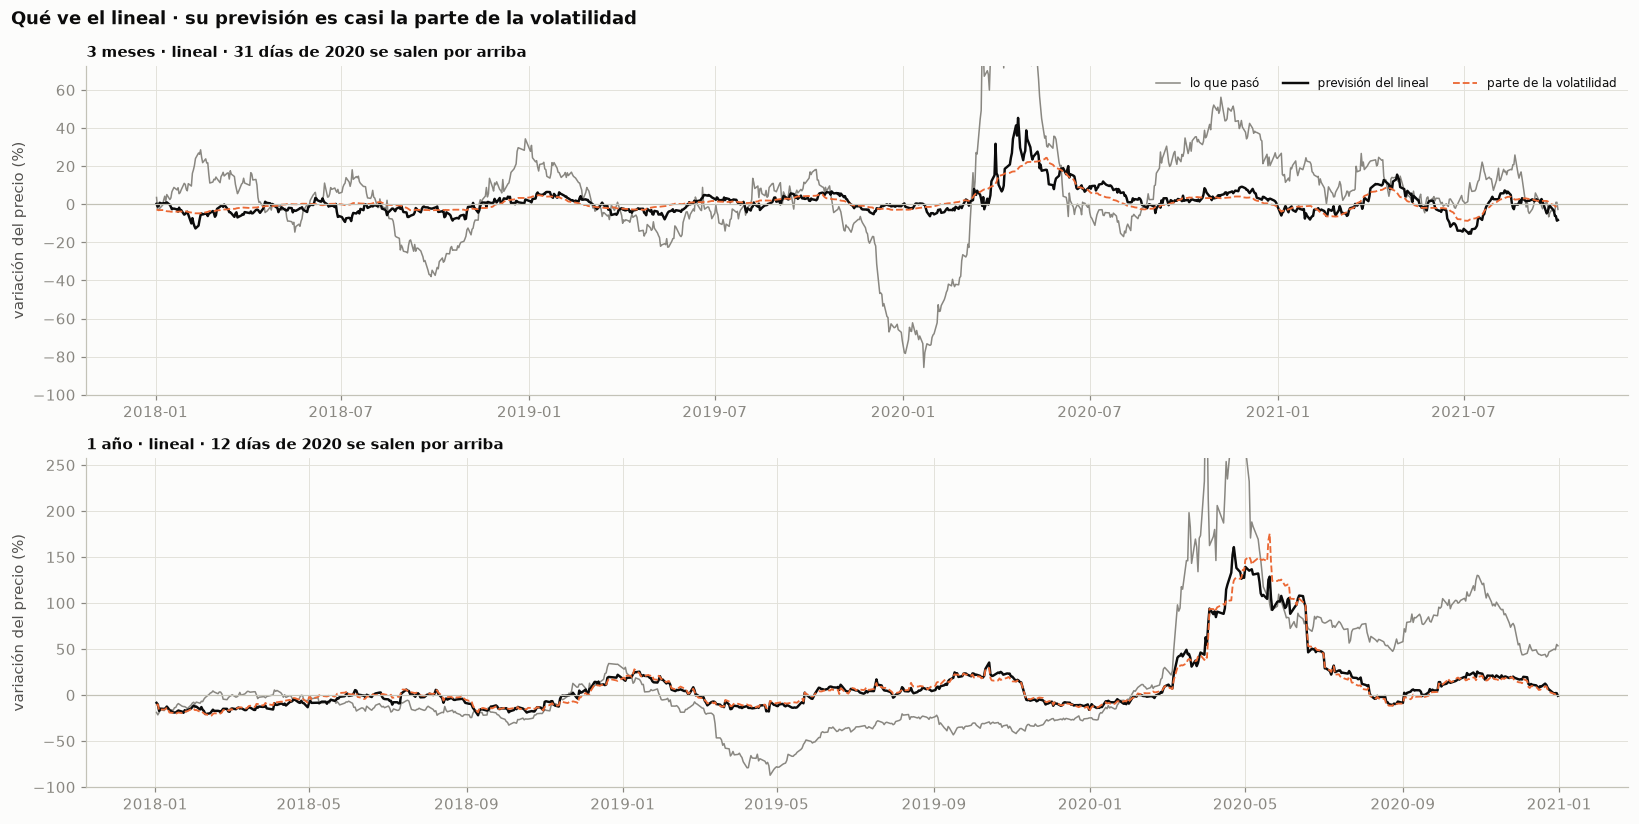

In [66]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7.6))
for ax, h in zip(axes, ["medio", "largo"]):
    a = aport_x[h].sort_values("fecha")
    real = e_prev[(e_prev["horizonte"] == h) & (e_prev["semilla"] == config.SEMILLA)
                  & (e_prev["modelo"] == config.CELDAS[0])].sort_values("fecha")
    ax.plot(real["fecha"], 100 * np.expm1(real["variación real"]), color=TINTA_SUAVE, linewidth=1, label="lo que pasó")
    ax.plot(a["fecha"], 100 * np.expm1(a["previsión"]), color=TINTA, linewidth=1.6, label="previsión del lineal")
    ax.plot(a["fecha"], 100 * np.expm1(a["volatilidad Brent"]), color=C["naranja"], linewidth=1.2, linestyle="--",
            label="parte de la volatilidad")
    ax.axhline(0, color=EJE, linewidth=0.8)
    techo = max(1.6 * 100 * np.expm1(a["previsión"].max()), 60)
    fuera = (100 * np.expm1(real["variación real"]) > techo).sum()
    ax.set_ylim(-100, techo)
    ax.set_ylabel("variación del precio (%)")
    ax.set_title(f"{HORIZONTE[h]} · lineal" + (f" · {fuera} días de 2020 se salen por arriba" if fuera else ""),
                 fontsize=10)
axes[0].legend(fontsize=8, ncol=3)
fig.suptitle("Qué ve el lineal · su previsión es casi la parte de la volatilidad", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()
plt.show()

### 9.2 El lineal sin cada variable y con solo ella

Nota del lineal (misma regularización, años juntos) al reajustarlo sin una variable o solo con ella. Si quitarla no cambia nada, no aporta; si con ella sola se acerca a «todas», casi todo viene de ahí.

In [67]:
quitar_x = pd.concat({HORIZONTE[h]: xp.quitar_variables_lineal(h, bases_x) for h in config.HORIZONTES}, axis=1)
quitar_x.round(3)

1 semana            3 meses              1 año          
                  sin ella solo ella sin ella solo ella sin ella solo ella
todas                0.993     0.993    0.972     0.972    0.820     0.820
Brent                0.992     1.000    0.972     1.008    0.818     1.000
WTI                  0.992     1.000    0.969     1.004    0.820     1.000
cobre                0.992     1.001    0.980     1.003    0.834     0.990
oro                  0.993     1.000    0.970     1.013    0.821     0.996
dólar                0.993     0.999    0.975     0.998    0.833     0.987
VIX                  0.993     1.000    0.972     1.005    0.817     1.003
volatilidad Brent    1.001     0.992    1.011     0.968    0.981     0.853

Año a año: con todas las variables, solo con la volatilidad y con todas menos la volatilidad.

In [68]:
filas = {}
for h in config.HORIZONTES:
    internas = [k for k, v in xp.NOMBRES.items() if v in aport_x[h].columns]
    opciones = {"todas": None, "solo volatilidad": ["log_vol_brent"],
                "sin volatilidad": [v for v in internas if v != "log_vol_brent"]}
    for nombre, variables in opciones.items():
        filas[(HORIZONTE[h], nombre)] = xp.nota_lineal(h, variables, bases_x)
pd.DataFrame(filas).T.rename_axis(["horizonte", "variables"]).round(3).astype(object).fillna("—")

2018  2019  2020  2021 años juntos
horizonte variables                                           
1 semana  todas            1.005 0.997 0.986 0.984       0.993
          solo volatilidad 1.004 0.999 0.986 0.979       0.992
          sin volatilidad  1.001 0.999 0.998 1.006       1.001
3 meses   todas            1.016 0.887 0.940 1.139       0.972
          solo volatilidad 1.014 0.892 0.944 1.097       0.968
          sin volatilidad  1.027 0.981 1.003 1.062       1.011
1 año     todas            0.750 1.038 0.672     —       0.820
          solo volatilidad 0.828 1.055 0.705     —       0.853
          sin volatilidad  0.910 0.989 0.996     —       0.981

### 9.3 Lo que usan las redes

Cuánto empeora la nota (MAE / ingenuo, años juntos) al desordenar cada variable entre fichas, para el promedio de 5 semillas de cada red y para el lineal. Cero: el modelo no la usa. Media de 5 desórdenes distintos.

In [69]:
importancia_x, efectos_x = xp.leer()
tabla_imp = importancia_x.pivot_table(index=["horizonte", "variable"], columns="modelo", values="pérdida", sort=False)
tabla_imp = tabla_imp[[*config.CELDAS, "Lineal"]]
orden_var = tabla_imp.groupby(level="variable").mean().mean(axis=1).sort_values(ascending=False).index
tabla_imp = tabla_imp.reindex(pd.MultiIndex.from_product([["medio", "largo"], orden_var], names=["horizonte", "variable"]))
print("Nota sin desordenar: " + " · ".join(
    f"{HORIZONTE[h]} {m} {n:.3f}" for (h, m), n in importancia_x.groupby(["horizonte", "modelo"], sort=False)["nota"].first().items()))
tabla_imp.rename(index=HORIZONTE, level="horizonte").round(3)

Nota sin desordenar: 3 meses RNN 0.938 · 3 meses LSTM 0.944 · 3 meses GRU 0.918 · 3 meses Lineal 0.972 · 1 año RNN 0.894 · 1 año LSTM 0.900 · 1 año GRU 0.911 · 1 año Lineal 0.820


modelo                         RNN   LSTM    GRU  Lineal
horizonte variable                                      
3 meses   volatilidad Brent  0.083  0.067  0.088   0.059
          Brent              0.012  0.019 -0.003   0.010
          VIX                0.009  0.004  0.018   0.006
          cobre              0.018 -0.001  0.007  -0.003
          dólar              0.002  0.003  0.005   0.002
          WTI                0.001  0.005  0.006   0.002
          oro               -0.002  0.002  0.001   0.001
1 año     volatilidad Brent  0.065  0.095  0.049   0.152
          Brent              0.002 -0.006 -0.002   0.028
          VIX                0.001  0.002  0.002  -0.001
          cobre              0.003  0.005  0.003   0.002
          dólar              0.002  0.001  0.002   0.006
          WTI                0.002 -0.001  0.000   0.001
          oro                0.001  0.001  0.001  -0.001

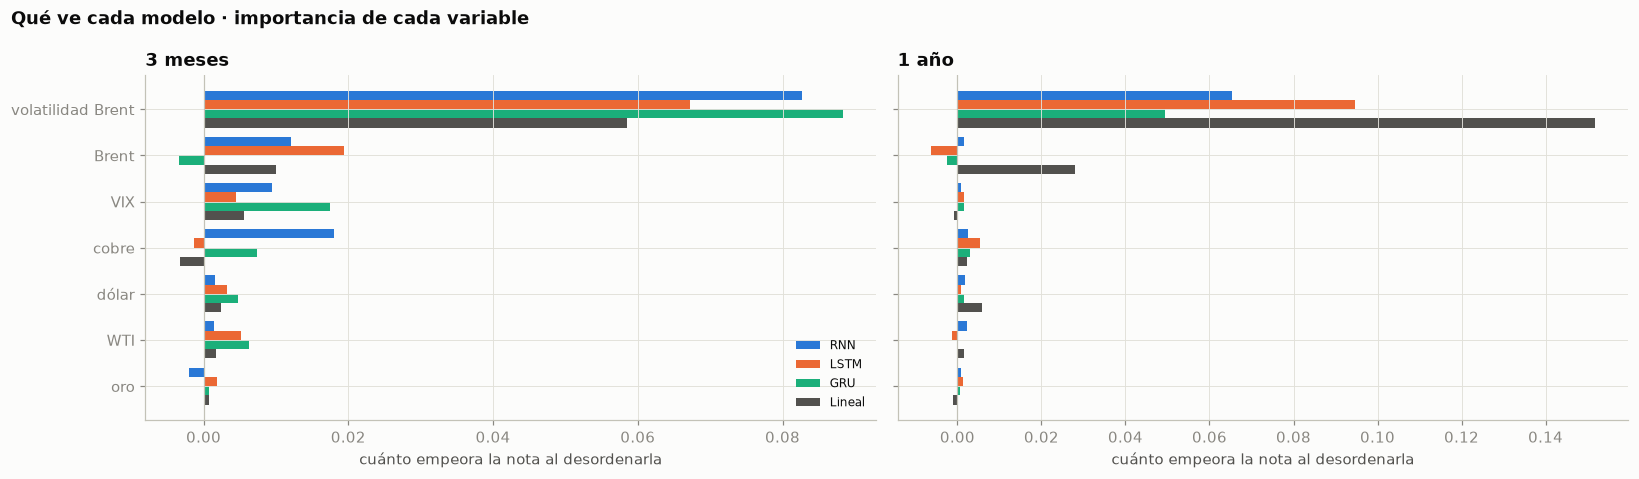

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
COLOR_MODELO = {**COLOR_RED, "Lineal": TINTA_2}
y = np.arange(len(orden_var))
for ax, h in zip(axes, ["medio", "largo"]):
    t = tabla_imp.loc[h].reindex(orden_var)
    for k, m in enumerate([*config.CELDAS, "Lineal"]):
        ax.barh(y + (k - 1.5) * 0.2, t[m], height=0.2, color=COLOR_MODELO[m], label=m)
    ax.axvline(0, color=EJE, linewidth=0.8)
    ax.set_yticks(y, orden_var)
    ax.set_title(HORIZONTE[h])
    ax.set_xlabel("cuánto empeora la nota al desordenarla")
axes[0].invert_yaxis()   # eje compartido: se invierte una sola vez (la más importante, arriba)
axes[0].legend(fontsize=8)
fig.suptitle("Qué ve cada modelo · importancia de cada variable", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 9.4 Situaciones típicas

Cuánto cambia de media la previsión (en % del precio) si, con todo lo demás igual, la volatilidad del Brent fuese el doble o la mitad, o si el Brent y el WTI estuvieran un 10 % más abajo que hace un mes:

In [71]:
tabla_ef = efectos_x.pivot_table(index=["horizonte", "escenario"], columns="modelo",
                                 values="cambio medio de la previsión (%)", sort=False)
tabla_ef[[*config.CELDAS, "Lineal"]].rename(index=HORIZONTE, level="horizonte").round(1)

modelo                                    RNN    LSTM     GRU  Lineal
horizonte escenario                                                  
3 meses   volatilidad ×2                7.800  11.600   8.700   7.100
          volatilidad ×0,5             -6.700  -8.600  -7.200  -6.700
          Brent y WTI −10 % en un mes   2.600   3.400   3.000   1.400
1 año     volatilidad ×2               14.000  14.600  11.800  34.700
          volatilidad ×0,5            -14.800 -12.900 -13.500 -25.800
          Brent y WTI −10 % en un mes  -0.400   0.600  -0.200   3.200

### 9.5 Lectura

> Las redes se reentrenaron con las semillas 42-46 (8 minutos): sin desordenar nada, su nota coincide exactamente con la de su promedio en la estabilidad (sección 7).

**El lineal mira casi solo una cosa: la volatilidad del Brent en el último mes.**
- Es lo que más mueve su previsión en los tres horizontes: dos tercios a 1 año, más de un tercio a 3 meses y la mitad a 1 semana. A 1 año, su previsión entera es casi la parte de la volatilidad (correlación 0,99; gráfico 9.1).
- Sin ella, el lineal no aporta nada: 1,001 a 1 semana, 1,011 a 3 meses y 0,981 a 1 año. Con solo ella: 0,992, 0,968 y 0,853. A 3 meses, solo con la volatilidad va incluso algo mejor que con todas las variables (0,968 frente a 0,972).
- **Su regla: tras la tormenta, rebote.** Con la volatilidad al doble de lo normal, prevé un 7 % más a 3 meses y un 35 % más a 1 año; con la mitad, un 7 % y un 26 % menos.
- Lo demás pesa poco. A 1 año aportan algo el cobre y el dólar (sin ellos, 0,833-0,834) y el último mes del Brent y el WTI: tras una caída del 10 %, prevé un 3 % más (algo de corrección). El Brent y el WTI se sustituyen entre sí: quitando uno, el otro hace su papel. El oro y el VIX no aportan.

**Las redes también miran sobre todo la volatilidad, pero distinto según el horizonte.**
- **3 meses:** la usan con la misma fuerza que el lineal o más (volatilidad al doble: un 8-12 % más, frente al 7 % del lineal). Además aprovechan algo del último mes del Brent (tras una caída del 10 %, un 3 % más, frente al 1 % del lineal), del cobre (la RNN) y del VIX (la GRU). Ese «algo más» es lo que les da ventaja sobre el lineal a 3 meses.
- **1 año:** solo la volatilidad, y con menos de la mitad de fuerza que el lineal (al doble: un 12-15 % más, frente al 35 %). Nada más: ni el último mes del Brent, ni el cobre, ni el dólar. Es la copia en pequeño de la sección 8.

**Por qué funciona la regla de la volatilidad.** En el pasado, la volatilidad alta llegó casi siempre con desplomes (2008, 2014-2016, 2020), y después el precio se recuperó. En validación, casi toda la ventaja a 1 año está en 2020: el lineal previó el rebote tras el desplome, aunque se quedó corto (gráfico 9.1).

**Cautela.** Es una sola idea, aprendida de pocos episodios. Y no distingue si la volatilidad sube por un desplome o por una subida brusca. En validación ya se ve una vez, a pequeña escala: en septiembre de 2019, el ataque a las instalaciones petroleras saudíes hizo saltar el precio, subió la volatilidad y el lineal previó un 20-35 % más a 1 año (gráfico 9.1); un año después el precio había caído un 30-40 %. La gran tormenta de la validación, la de 2020, fue de caída. Sin usar el test, se puede comprobar en el train (2000-2017) si tras las subidas bruscas pasa lo mismo.

**Qué implica**
- **Información nueva:** la señal que funciona es el estrés del mercado. Lo más prometedor es medirlo mejor: el VIX en nivel (ahora solo entra su variación diaria) o la volatilidad del Brent a más plazo. Añadir más variaciones diarias, no.
- **Aplicación:** la explicación es sencilla. A 3 meses y a 1 año, la previsión depende sobre todo de lo nervioso que esté el mercado, y tras las tormentas el precio suele recuperarse. Lo que puede invalidarla: que la tormenta venga de una subida y no de una caída, o un episodio sin precedentes.